# El pulso del AMBA · Notebook completo
Código completo de la serie: secciones 00 a 12, verificación del post 1, gráficos de los posts 1, 2 y 3 y prueba de sensibilidad.
Ejecutar celda por celda, en orden y en la misma sesión (o *Entorno de ejecución → Ejecutar todo*). Versión del 16/10/2026.

**Cifras congeladas el 16/10/2026** con la descarga de ese día (1.517.680 filas, datos hasta el 14/10/2026; corte consolidado al 31/08/2026). Resultados esperados: sección 05, 17 de 17; post 1, 26 de 26; gráfico del post 2, 11 de 11; slide 7, 8 de 8; gráfico del post 3, 5 de 5; prueba de sensibilidad, 25 de 25 reproducidas; sección 12, **66 de 66**.
Una descarga nueva puede traer más filas preliminares (posteriores al corte): es lo esperado. Lo que no debe cambiar es el período consolidado (sección 05, grupo C).

**Sección 10:** usa `datos_bcra.csv` de la sesión de Colab o de la raíz de Google Drive; si no está, lo descarga del repositorio.

## 00 · Configuración

In [1]:
# El pulso del AMBA · Sección 00: configuracion
# Primera sección: no depende de ninguna otra.

# ================
# 0. CONFIGURACIÓN
# ================
# COLAB: %pip install -q duckdb

import platform
import shutil
from datetime import timedelta

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import requests

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 130)

# Fuentes
URL_SUBE = "https://archivos-datos.transporte.gob.ar/upload/Dat_Ab_Usos/dat-ab-usos-{anio}.csv"
URL_FERIADOS = "https://api.argentinadatos.com/v1/feriados/{anio}"
ANIOS = [2024, 2025, 2026]

# Decisiones de análisis (explícitas, para que queden documentadas)
FECHA_FIN_CONSOLIDADO = "2026-08-31"   # corte fijo de esta publicación (septiembre ya figura consolidado: ver bitácora)
TOLERANCIA_BCRA_PCT = 10.0             # BCRA cuenta viajes pagos; el dataset, transacciones netas
UMBRAL_PRELIMINAR_PCT = 1.0            # máximo aceptado de preliminares dentro del período consolidado
UMBRAL_COBERTURA_LINEAS = 0.8          # un día con < 80% de las líneas habituales se revisa

# Base de datos local
RUTA_BASE = "sube_pulso_amba.duckdb"
RUTA_RESPALDO_DRIVE = "/content/drive/MyDrive/sube_pulso_amba.duckdb"

# Entorno de ejecución
# Las cifras publicadas se calcularon con estas versiones. Si en el futuro un número
# no coincide, esto separa "cambió la librería" de "cambió la fuente".
print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"duckdb {duckdb.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.16 | pandas 2.2.3 | duckdb 1.3.2 | matplotlib 3.10.0


## 01 · Descarga

In [2]:
# El pulso del AMBA · Sección 01: descarga
# Requiere haber ejecutado antes la sección 00 en la misma sesión.

# ==================================
# 1. DESCARGA DE LOS DATOS OFICIALES
# ==================================
def detectar_separador(url, codificacion):
    """Lee 5 filas: si quedan en una sola columna, el separador real es ';'."""
    muestra = pd.read_csv(url, encoding=codificacion, nrows=5)
    return ";" if len(muestra.columns) == 1 else ","


def descargar_anio(anio):
    """Descarga el CSV de un año probando las codificaciones habituales de los portales públicos."""
    url = URL_SUBE.format(anio=anio)
    for codificacion in ["utf-8", "latin-1"]:
        try:
            separador = detectar_separador(url, codificacion)
            tabla = pd.read_csv(url, encoding=codificacion, sep=separador, low_memory=False)
            tabla["anio_archivo"] = anio   # trazabilidad: de qué archivo vino cada fila
            print(f"{anio}: {len(tabla):,} filas | codificación={codificacion} | separador='{separador}'")
            return tabla
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer el archivo de {anio}")


df_sube = pd.concat([descargar_anio(anio) for anio in ANIOS], ignore_index=True)
df_sube.columns = df_sube.columns.str.strip().str.lower()

# Tipos correctos desde el inicio. errors="coerce" convierte lo inválido en NaN/NaT
# para poder CONTARLO en la verificación, en lugar de ocultarlo o frenar la carga.
df_sube["dia_transporte"] = pd.to_datetime(df_sube["dia_transporte"], errors="coerce")
df_sube["cantidad"] = pd.to_numeric(df_sube["cantidad"], errors="coerce")

print(f"\nTotal descargado: {len(df_sube):,} filas")
print("Columnas:", df_sube.columns.tolist())

2024: 504,631 filas | codificación=utf-8 | separador=','
2025: 541,557 filas | codificación=utf-8 | separador=','
2026: 471,492 filas | codificación=utf-8 | separador=','

Total descargado: 1,517,680 filas
Columnas: ['dia_transporte', 'nombre_empresa', 'linea', 'amba', 'tipo_transporte', 'jurisdiccion', 'provincia', 'municipio', 'cantidad', 'dato_preliminar', 'anio_archivo']


## 02 · Verificación del dataset crudo

In [3]:
# El pulso del AMBA · Sección 02: verificacion dataset
# Requiere haber ejecutado antes las secciones 00 a 01 en la misma sesión.

# =================================
# 2. VERIFICACIÓN DEL DATASET CRUDO
# =================================

# Cada control queda con un estado: OK | REVISAR | FALLA | INFO
registro_controles = []


def registrar_control(grupo, control, valor, estado, detalle=""):
    """Agrega una fila al informe de verificación del dataset."""
    registro_controles.append({"grupo": grupo, "control": control, "valor": valor,
                               "estado": estado, "detalle": detalle})


# 2.1 Estructura: ¿coincide con el diccionario oficial?
COLUMNAS_DICCIONARIO = {"dia_transporte", "nombre_empresa", "linea", "amba",
                        "jurisdiccion", "provincia", "municipio", "cantidad"}
columnas_reales = set(df_sube.columns) - {"anio_archivo"}
columnas_faltantes = COLUMNAS_DICCIONARIO - columnas_reales
columnas_no_documentadas = columnas_reales - COLUMNAS_DICCIONARIO

registrar_control("Estructura", "Columnas del diccionario ausentes", len(columnas_faltantes),
                  "OK" if not columnas_faltantes else "FALLA", ", ".join(sorted(columnas_faltantes)))
registrar_control("Estructura", "Columnas no documentadas", len(columnas_no_documentadas),
                  "INFO", ", ".join(sorted(columnas_no_documentadas)))

# 2.2 Integridad de valores
fechas_invalidas = int(df_sube["dia_transporte"].isna().sum())
registrar_control("Integridad", "Fechas inválidas o vacías", fechas_invalidas,
                  "OK" if fechas_invalidas == 0 else "FALLA")

cantidades_invalidas = int(df_sube["cantidad"].isna().sum())
registrar_control("Integridad", "Cantidades inválidas o vacías", cantidades_invalidas,
                  "OK" if cantidades_invalidas == 0 else "FALLA")

# La cantidad viene "neteada de reversas": un negativo puede ser legítimo, por eso se revisa
filas_negativas = int((df_sube["cantidad"] < 0).sum())
registrar_control("Integridad", "Cantidades negativas", filas_negativas,
                  "OK" if filas_negativas == 0 else "REVISAR", "Posibles reversas netas")

registrar_control("Integridad", "Filas con cantidad cero", int((df_sube["cantidad"] == 0).sum()), "INFO",
                  "Puede ser una línea sin servicio ese día")

# 2.3 Duplicados
columnas_originales = [col for col in df_sube.columns if col != "anio_archivo"]
duplicados_exactos = int(df_sube.duplicated(subset=columnas_originales).sum())
registrar_control("Duplicados", "Filas idénticas", duplicados_exactos,
                  "OK" if duplicados_exactos == 0 else "FALLA")

CLAVE_NATURAL = ["dia_transporte", "nombre_empresa", "linea", "tipo_transporte",
                 "jurisdiccion", "provincia", "municipio"]
duplicados_de_clave = int(df_sube.duplicated(subset=CLAVE_NATURAL).sum())
registrar_control("Duplicados", "Misma línea, empresa y día repetidos", duplicados_de_clave,
                  "OK" if duplicados_de_clave == 0 else "REVISAR",
                  "Ojo: la jurisdicción es parte de la clave (ver sección 6)")

# 2.4 Coherencia entre archivo y fecha
filas_fuera_de_su_anio = int((df_sube["dia_transporte"].dt.year != df_sube["anio_archivo"]).sum())
registrar_control("Coherencia", "Filas cuya fecha no corresponde al año del archivo", filas_fuera_de_su_anio,
                  "OK" if filas_fuera_de_su_anio == 0 else "REVISAR")

# 2.5 Completitud temporal
fecha_minima, fecha_maxima = df_sube["dia_transporte"].min(), df_sube["dia_transporte"].max()
registrar_control("Completitud", "Rango de fechas", f"{fecha_minima.date()} → {fecha_maxima.date()}", "INFO")

calendario_completo = pd.date_range(fecha_minima, fecha_maxima, freq="D")
dias_presentes = pd.DatetimeIndex(df_sube["dia_transporte"].dropna().dt.normalize().unique())
dias_faltantes = calendario_completo.difference(dias_presentes)
registrar_control("Completitud", "Días sin ningún registro", len(dias_faltantes),
                  "OK" if len(dias_faltantes) == 0 else "REVISAR")

# Un día puede existir con cobertura parcial: distingue "faltan datos" de "hubo menos viajes".
# LIMITACIÓN CONOCIDA: la referencia es la mediana de TODO el período, y la cantidad de líneas
# crece con los años. Por eso algunos domingos de principios de 2024 quedan debajo del umbral
# por faltantes leves del interior, con el AMBA completo. La sección 03 los explica; se
# reemplaza por una referencia local (AMBA e interior por separado) después de publicar.
lineas_por_dia = df_sube.groupby("dia_transporte")["linea"].nunique()
mediana_lineas_por_dia = lineas_por_dia.median()
dias_cobertura_baja = lineas_por_dia[lineas_por_dia < UMBRAL_COBERTURA_LINEAS * mediana_lineas_por_dia]
registrar_control("Completitud", "Días con cobertura de líneas < 80% de la mediana", len(dias_cobertura_baja),
                  "OK" if len(dias_cobertura_baja) == 0 else "REVISAR",
                  f"Mediana: {mediana_lineas_por_dia:.0f} líneas/día (detalle en la sección 3)")

# 2.6 Datos preliminares
es_preliminar = df_sube["dato_preliminar"].eq("SI")
en_periodo_consolidado = df_sube["dia_transporte"] <= FECHA_FIN_CONSOLIDADO
pct_preliminar_consolidado = (df_sube.loc[es_preliminar & en_periodo_consolidado, "cantidad"].sum()
                              / df_sube.loc[en_periodo_consolidado, "cantidad"].sum() * 100)
registrar_control("Preliminares", "Transacciones preliminares hasta el corte consolidado",
                  f"{pct_preliminar_consolidado:.3f}%",
                  "OK" if pct_preliminar_consolidado < UMBRAL_PRELIMINAR_PCT else "REVISAR",
                  f"Corte: {FECHA_FIN_CONSOLIDADO}")

# 2.7 Triangulación con una fuente independiente (BCRA)
total_mensual_pais = df_sube.groupby(df_sube["dia_transporte"].dt.to_period("M"))["cantidad"].sum()
REFERENCIAS_BCRA_2025 = {
    "2025-02": (283_000_000, "BCRA, Informe de Pagos Minoristas de marzo 2025"),
    "2025-04": (363_500_000, "BCRA, Informe de Pagos Minoristas de mayo 2025"),
}
for mes, (viajes_bcra, fuente) in REFERENCIAS_BCRA_2025.items():
    total_dataset = total_mensual_pais.get(pd.Period(mes, freq="M"), 0)
    diferencia_pct = (total_dataset - viajes_bcra) / viajes_bcra * 100
    registrar_control("Triangulación BCRA", f"{mes}: total país frente a BCRA", f"{diferencia_pct:+.1f}%",
                      "OK" if abs(diferencia_pct) <= TOLERANCIA_BCRA_PCT else "REVISAR",
                      f"Dataset: {total_dataset:,.0f} | BCRA: {viajes_bcra:,} | {fuente}")

# Informe
informe_dataset = pd.DataFrame(registro_controles)
print(informe_dataset.to_string(index=False))
print("\nResumen:", informe_dataset["estado"].value_counts().to_dict())
informe_dataset.to_csv("informe_verificacion_dataset.csv", index=False, encoding="utf-8")

# Detalle de preliminares por mes (2026): ¿son días enteros o filas sueltas?
datos_2026 = df_sube[df_sube["dia_transporte"].dt.year == 2026].copy()
datos_2026["mes"] = datos_2026["dia_transporte"].dt.strftime("%Y-%m")
datos_2026["cantidad_preliminar"] = datos_2026["cantidad"].where(datos_2026["dato_preliminar"] == "SI", 0)
preliminares_por_mes = datos_2026.groupby("mes").agg(transacciones=("cantidad", "sum"),
                                                     preliminares=("cantidad_preliminar", "sum"))
preliminares_por_mes["pct_preliminar"] = (preliminares_por_mes["preliminares"]
                                          / preliminares_por_mes["transacciones"] * 100).round(2)
print("\nPorcentaje de transacciones preliminares por mes (2026):")
print(preliminares_por_mes["pct_preliminar"].to_string())

             grupo                                               control                   valor  estado                                                                                    detalle
        Estructura                     Columnas del diccionario ausentes                       0      OK                                                                                           
        Estructura                              Columnas no documentadas                       2    INFO                                                           dato_preliminar, tipo_transporte
        Integridad                             Fechas inválidas o vacías                       0      OK                                                                                           
        Integridad                         Cantidades inválidas o vacías                       0      OK                                                                                           
        Integridad  

## 03 · Diagnóstico de anomalías

In [4]:
# El pulso del AMBA · Sección 03: anomalias
# Requiere haber ejecutado antes las secciones 00 a 02 en la misma sesión.

# ===========================
# 3. DIAGNÓSTICO DE ANOMALÍAS
# ===========================
print("FILAS CON CANTIDAD NEGATIVA (reversas que superaron a las validaciones del día)")
print(df_sube.loc[df_sube["cantidad"] < 0,
                  ["dia_transporte", "nombre_empresa", "linea", "tipo_transporte", "cantidad"]]
      .to_string(index=False))

# Cada día con baja cobertura se compara con la mediana de SU MISMO día de la semana:
# un domingo se compara con domingos, no con un martes.
NOMBRES_DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
totales_diarios = df_sube.groupby("dia_transporte").agg(lineas_activas=("linea", "nunique"),
                                                        transacciones=("cantidad", "sum"))
totales_diarios["dia_semana"] = totales_diarios.index.dayofweek
mediana_por_dia_semana = totales_diarios.groupby("dia_semana")["transacciones"].median()
totales_diarios["pct_vs_mediana_mismo_dia"] = (totales_diarios["transacciones"]
                                               / totales_diarios["dia_semana"].map(mediana_por_dia_semana)
                                               * 100).round(1)

dias_a_explicar = totales_diarios.loc[dias_cobertura_baja.index].copy()
dias_a_explicar["nombre_dia"] = dias_a_explicar["dia_semana"].map(lambda numero: NOMBRES_DIAS[numero])
print("\nDÍAS CON BAJA COBERTURA DE LÍNEAS")
print("Transacciones normales con menos líneas = carga parcial; transacciones muy bajas = evento real")
print(dias_a_explicar[["nombre_dia", "lineas_activas", "transacciones", "pct_vs_mediana_mismo_dia"]].to_string())

# Las cargas parciales se separan en AMBA e interior, comparando cada día con los mismos
# días de la semana ±14 días (referencia local, que no depende del crecimiento de líneas).
# Resultado: el 14/01, 18/02, 05/03 y 10/03/2024 solo les faltaban líneas del interior;
# el AMBA estuvo completo, así que no son eventos del análisis.
print("\nCARGAS PARCIALES DE 2024: ¿AMBA O INTERIOR?")
print(duckdb.sql("""
    WITH totales_por_dia AS (
        SELECT CAST(dia_transporte AS DATE) AS fecha,
               amba,
               COUNT(DISTINCT linea)        AS lineas,
               SUM(cantidad)                AS transacciones
        FROM df_sube
        WHERE CAST(dia_transporte AS DATE) BETWEEN DATE '2024-01-01' AND DATE '2024-03-31'
        GROUP BY ALL
    ),
    dias_a_revisar AS (
        SELECT UNNEST([DATE '2024-01-14', DATE '2024-02-18',
                       DATE '2024-03-05', DATE '2024-03-10']) AS fecha
    )
    SELECT r.fecha,
           ['lunes','martes','miércoles','jueves','viernes','sábado','domingo'][isodow(r.fecha)] AS nombre_dia,
           d.amba,
           d.lineas,
           MEDIAN(v.lineas)                                          AS lineas_vecinos,
           d.transacciones,
           ROUND(d.transacciones / MEDIAN(v.transacciones) * 100, 1) AS pct_transacciones_vs_vecinos
    FROM dias_a_revisar AS r
    JOIN totales_por_dia AS d ON d.fecha = r.fecha
    JOIN totales_por_dia AS v
      ON  v.amba = d.amba
      AND isodow(v.fecha) = isodow(r.fecha)
      AND v.fecha <> r.fecha
      AND v.fecha BETWEEN r.fecha - INTERVAL 14 DAY AND r.fecha + INTERVAL 14 DAY
    GROUP BY r.fecha, d.amba, d.lineas, d.transacciones
    ORDER BY r.fecha, d.amba
""").df().to_string(index=False))

FILAS CON CANTIDAD NEGATIVA (reversas que superaron a las validaciones del día)
dia_transporte nombre_empresa              linea tipo_transporte  cantidad
    2024-02-20  SOFSE - Mitre FFCC_MITRE_CAPILLA            TREN        -3
    2024-03-05  SOFSE - Mitre FFCC_MITRE_CAPILLA            TREN      -105
    2024-04-20  SOFSE - Mitre FFCC_MITRE_CAPILLA            TREN        -1
    2025-05-03  SOFSE - Mitre    FCC MITRE_TIGRE            TREN        -1

DÍAS CON BAJA COBERTURA DE LÍNEAS
Transacciones normales con menos líneas = carga parcial; transacciones muy bajas = evento real
               nombre_dia  lineas_activas  transacciones  pct_vs_mediana_mismo_dia
dia_transporte                                                                    
2024-01-01          lunes             979        2279255                      17.4
2024-01-14        domingo            1094        4622678                     114.0
2024-02-18        domingo            1087        4050407                      99.9


## 04 · Modelo en DuckDB

In [5]:
# El pulso del AMBA · Sección 04: modelo duckdb
# Requiere haber ejecutado antes las secciones 00 a 03 en la misma sesión.

# ============================
# 4. MODELO DE DATOS EN DUCKDB
# ============================

# staging → dim_fecha / dim_linea → hechos → duplicados → incidencias → feriados → vistas
conexion = duckdb.connect(RUTA_BASE)

# Se borra en orden inverso a las dependencias (primero lo que depende de otra cosa)
for sentencia_borrado in [
    "DROP VIEW  IF EXISTS vista_dia_vs_habil_tipico",
    "DROP VIEW  IF EXISTS vista_diaria_amba",
    "DROP VIEW  IF EXISTS vista_transacciones_consolidadas",
    "DROP TABLE IF EXISTS feriados_oficiales",
    "DROP TABLE IF EXISTS incidencias_calidad",
    "DROP TABLE IF EXISTS hechos_transacciones_diarias",
    "DROP TABLE IF EXISTS eventos_verificados",
    "DROP TABLE IF EXISTS dim_linea",
    "DROP TABLE IF EXISTS dim_fecha",
    "DROP TABLE IF EXISTS staging_sube_crudo",
]:
    conexion.execute(sentencia_borrado)

# 4.1 STAGING: copia fiel del CSV oficial, con limpieza mínima
# DuckDB lee el DataFrame df_sube por su nombre, como si fuera una tabla.
conexion.execute("""
CREATE TABLE staging_sube_crudo AS
SELECT
    CAST(dia_transporte AS DATE)    AS dia_transporte,
    nombre_empresa,
    linea,
    amba,
    tipo_transporte,
    NULLIF(TRIM(jurisdiccion), '')  AS jurisdiccion,
    NULLIF(TRIM(provincia), '')     AS provincia,
    -- 'SN' y 'SD' aparecen solo en líneas que no pertenecen a un único municipio:
    -- NULL significa "no aplica" (verificado: solo las líneas MUNICIPALES tienen municipio)
    CASE WHEN TRIM(municipio) IN ('', 'SN', 'SD') THEN NULL
         ELSE TRIM(municipio) END   AS municipio,
    CAST(cantidad AS INTEGER)       AS cantidad,
    dato_preliminar
FROM df_sube
""")

# 4.2 DIMENSIÓN FECHA
conexion.execute("""
CREATE TABLE dim_fecha (
    fecha             DATE     PRIMARY KEY,
    anio              SMALLINT NOT NULL,
    mes               TINYINT  NOT NULL,
    nombre_mes        VARCHAR  NOT NULL,
    dia_semana        TINYINT  NOT NULL,   -- 1 = lunes ... 7 = domingo
    nombre_dia        VARCHAR  NOT NULL,
    es_fin_de_semana  BOOLEAN  NOT NULL
)
""")

# isodow(): 1 = lunes, 7 = domingo. Las listas de DuckDB empiezan en 1, así que
# lista[isodow(fecha)] da el nombre exacto sin depender del idioma del servidor.
conexion.execute("""
INSERT INTO dim_fecha
SELECT
    fecha,
    year(fecha),
    month(fecha),
    ['enero','febrero','marzo','abril','mayo','junio','julio',
     'agosto','septiembre','octubre','noviembre','diciembre'][month(fecha)],
    isodow(fecha),
    ['lunes','martes','miércoles','jueves','viernes','sábado','domingo'][isodow(fecha)],
    isodow(fecha) >= 6
FROM (SELECT DISTINCT dia_transporte AS fecha FROM staging_sube_crudo)
""")

# 4.3 DIMENSIÓN LÍNEA
conexion.execute("""
CREATE TABLE dim_linea (
    linea_id                INTEGER PRIMARY KEY,
    nombre_empresa          VARCHAR NOT NULL,
    linea                   VARCHAR NOT NULL,
    tipo_transporte         VARCHAR NOT NULL,
    jurisdiccion            VARCHAR,   -- tal como la informa la fuente
    provincia               VARCHAR,
    municipio               VARCHAR,
    amba                    VARCHAR NOT NULL,
    numero_linea            INTEGER,   -- identidad estable de las líneas nacionales y porteñas del AMBA
    jurisdiccion_corregida  VARCHAR    -- jurisdicción según el código de línea (regla CABA_LINEA_)
)
""")

# row_number() reemplaza al AUTO_INCREMENT de MySQL.
# numero_linea permite seguir a "la línea 12" como una sola serie antes y después
# del traspaso Nación → Ciudad, aunque la fuente la informe en dos jurisdicciones.
conexion.execute("""
INSERT INTO dim_linea
SELECT
    row_number() OVER (ORDER BY tipo_transporte, nombre_empresa, linea,
                                jurisdiccion, provincia, municipio, amba) AS linea_id,
    nombre_empresa, linea, tipo_transporte, jurisdiccion, provincia, municipio, amba,
    CASE WHEN tipo_transporte = 'COLECTIVO'
          AND amba = 'SI'
          AND (jurisdiccion IN ('NACIONAL', 'C.A.B.A') OR starts_with(linea, 'CABA_LINEA_'))
         THEN TRY_CAST(regexp_extract(linea, '(\\d+)', 1) AS INTEGER)
    END AS numero_linea,
    CASE WHEN starts_with(linea, 'CABA_LINEA_') THEN 'C.A.B.A'
         ELSE jurisdiccion
    END AS jurisdiccion_corregida
FROM (
    SELECT DISTINCT nombre_empresa, linea, tipo_transporte,
                    jurisdiccion, provincia, municipio, amba
    FROM staging_sube_crudo
)
""")

# 4.4 EVENTOS VERIFICADOS (días atípicos, cada uno con su fuente)
conexion.execute("""
CREATE TABLE eventos_verificados (
    fecha        DATE    PRIMARY KEY REFERENCES dim_fecha (fecha),
    tipo_evento  VARCHAR NOT NULL CHECK (tipo_evento IN
                 ('PARO', 'FERIADO', 'CARGA_PARCIAL', 'VISPERA', 'NO_LABORABLE')),
    descripcion  VARCHAR NOT NULL,
    fuente       VARCHAR NOT NULL
)
""")

# Un evento es un día atípico PARA EL AMBA: es lo que esta tabla excluye del análisis.
# Las cargas parciales del 14/01, 18/02, 05/03 y 10/03/2024 no figuran: les faltaban líneas
# del interior, pero el AMBA estuvo completo esos días (verificado contra los mismos días
# de la semana, ±14 días; ver bitácora, sección 1). Excluirlos sacaría días normales de las medianas.
conexion.execute("""
INSERT INTO eventos_verificados VALUES
('2024-01-01', 'FERIADO',       'Año Nuevo',                                                   'Feriado nacional inamovible'),
('2024-01-24', 'PARO',          'Paro general CGT: transporte urbano hasta las 19 h',          'https://www.expreso.ec/actualidad/mundo/argentina-alista-huelga-general-jueves-199268.html'),
('2024-03-28', 'NO_LABORABLE',  'Jueves Santo',                                                'Día no laborable (Ley 27.399)'),
('2024-04-11', 'PARO',          'Paro de colectivos UTA: unas 140 líneas sin servicio',        'https://www.tiempoar.com.ar/ta_article/paro-de-colectivos-cuales-son-las-lineas-que-no-prestan-servicio-y-hasta-cuando/'),
('2024-05-01', 'FERIADO',       'Día del Trabajador',                                          'Feriado nacional inamovible'),
('2024-05-09', 'PARO',          'Paro general CGT: colectivos, trenes y subte',                'https://www.lanacion.com.ar/politica/cuando-es-el-paro-general-de-la-cgt-y-el-transporte-nid07052024/'),
('2024-10-30', 'PARO',          'Paro de transporte: trenes y subte (la UTA levantó su paro)', 'https://www.diagonales.com/paro_t6241bf027e014e0475e231cd'),
('2024-12-24', 'VISPERA',       'Nochebuena',                                                  'Patrón observado en la SUBE (sección 7); no es feriado'),
('2024-12-25', 'FERIADO',       'Navidad',                                                     'Feriado nacional inamovible'),
('2024-12-31', 'VISPERA',       'Fin de año',                                                  'Patrón observado en la SUBE (sección 7); no es feriado'),
('2025-01-01', 'FERIADO',       'Año Nuevo',                                                   'Feriado nacional inamovible'),
('2025-04-10', 'PARO',          'Paro general CGT: trenes y subte (los colectivos funcionaron)', 'https://eleconomista.com.ar/politica/todo-lo-tenes-saber-sobre-paro-general-10-abril-n83742'),
('2025-04-17', 'NO_LABORABLE',  'Jueves Santo',                                                'Día no laborable (Ley 27.399)'),
('2025-05-01', 'FERIADO',       'Día del Trabajador',                                          'Feriado nacional inamovible'),
('2025-05-06', 'PARO',          'Paro de colectivos UTA (24 h)',                               'https://www.canal26.com/general/2025/05/06/paro-de-colectivos-del-martes-6-de-mayo-que-lineas-se-adhieren-a-la-medida-de-fuerza-y-cuales-funcionan/'),
('2025-12-24', 'VISPERA',       'Nochebuena',                                                  'Patrón observado en la SUBE (sección 7); no es feriado'),
('2025-12-31', 'VISPERA',       'Fin de año',                                                  'Patrón observado en la SUBE (sección 7); no es feriado'),
('2026-02-19', 'PARO',          'Paro general CGT contra la reforma laboral',                  'https://www.bloomberglinea.com/latinoamerica/argentina/a-que-hora-se-levanta-el-paro-de-la-cgt-y-como-impacta-en-colectivos-trenes-el-subte-y-vuelos/'),
('2026-05-01', 'FERIADO',       'Día del Trabajador',                                          'Feriado nacional inamovible')
""")

# 4.5 TABLA DE HECHOS
conexion.execute("""
CREATE TABLE hechos_transacciones_diarias (
    fecha          DATE    NOT NULL REFERENCES dim_fecha (fecha),
    linea_id       INTEGER NOT NULL REFERENCES dim_linea (linea_id),
    cantidad       INTEGER NOT NULL,
    es_preliminar  BOOLEAN NOT NULL,
    es_duplicado   BOOLEAN NOT NULL,   -- se marca, no se borra: la tabla sigue siendo fiel a la fuente
    PRIMARY KEY (fecha, linea_id)
)
""")

# Punto clave: NULL = NULL no da verdadero, da NULL (desconocido).
# Con "=", las filas de subte (jurisdicción y provincia en NULL) se perderían EN SILENCIO.
# IS NOT DISTINCT FROM es la "igualdad segura ante NULL" del estándar SQL (en MySQL: <=>).
conexion.execute("""
INSERT INTO hechos_transacciones_diarias
SELECT s.dia_transporte, l.linea_id, s.cantidad, s.dato_preliminar = 'SI', FALSE
FROM staging_sube_crudo AS s
JOIN dim_linea AS l
  ON  l.nombre_empresa  = s.nombre_empresa
  AND l.linea           = s.linea
  AND l.tipo_transporte = s.tipo_transporte
  AND l.jurisdiccion    IS NOT DISTINCT FROM s.jurisdiccion
  AND l.provincia       IS NOT DISTINCT FROM s.provincia
  AND l.municipio       IS NOT DISTINCT FROM s.municipio
  AND l.amba            = s.amba
""")

# 4.6 MARCADO DE DUPLICADOS (regla general, no un parche por línea)
# Una fila mal etiquetada (jurisdicción declarada distinta de la corregida) es duplicada
# si ese mismo día existe un registro bien etiquetado de la misma línea.
conexion.execute("""
UPDATE hechos_transacciones_diarias AS h
SET es_duplicado = TRUE
FROM dim_linea AS linea_mal_etiquetada
WHERE h.linea_id = linea_mal_etiquetada.linea_id
  AND linea_mal_etiquetada.jurisdiccion <> linea_mal_etiquetada.jurisdiccion_corregida
  AND EXISTS (
        SELECT 1
        FROM hechos_transacciones_diarias AS h2
        JOIN dim_linea AS linea_bien_etiquetada ON linea_bien_etiquetada.linea_id = h2.linea_id
        WHERE linea_bien_etiquetada.jurisdiccion = linea_bien_etiquetada.jurisdiccion_corregida
          AND linea_bien_etiquetada.jurisdiccion_corregida = linea_mal_etiquetada.jurisdiccion_corregida
          AND linea_bien_etiquetada.numero_linea = linea_mal_etiquetada.numero_linea
          AND h2.fecha = h.fecha
  )
""")

# 4.7 INCIDENCIAS DE CALIDAD (documentación para el README)
conexion.execute("""
CREATE TABLE incidencias_calidad (
    incidencia_id    INTEGER PRIMARY KEY,
    numero_linea     INTEGER,
    desde            DATE    NOT NULL,
    hasta            DATE    NOT NULL,
    tipo_incidencia  VARCHAR NOT NULL CHECK (tipo_incidencia IN
                     ('TRANSICION', 'DOBLE_CONTEO', 'JURISDICCION_ERRONEA', 'CARGA_PARCIAL', 'FIN_DE_SERVICIO')),
    descripcion      VARCHAR NOT NULL,
    accion_tomada    VARCHAR NOT NULL
)
""")

conexion.execute("""
INSERT INTO incidencias_calidad VALUES
(1, NULL, '2025-01-20', '2025-02-03', 'TRANSICION',
    'Traspaso de 31 líneas de Nación a Ciudad (acta del 03/09/2024). Corte efectivo en el sistema: 01/02/2025. Días con reparto entre jurisdicciones (la suma da alrededor del 100% de un día normal).',
    'Sin corrección: ambas jurisdicciones se unen mediante numero_linea'),
(2, 99, '2026-02-01', '2026-02-12', 'DOBLE_CONTEO',
    'Línea 99 informada a la vez como NACIONAL (con código CABA_LINEA_99) y como C.A.B.A., con cantidades casi idénticas. El 05/02 solo existe el registro NACIONAL.',
    'Se marcan como duplicadas las filas NACIONAL de los días con registro C.A.B.A.; la del 05/02 se reasigna a C.A.B.A.'),
(3, 99, '2026-02-12', '2026-02-12', 'FIN_DE_SERVICIO',
    'Último día de la línea 99: fusionada con la 106 como Ramal B (Resolución 18/2026 de la Secretaría de Transporte de CABA, publicada el 30/01/2026). Jornada de transición con 3.245 transacciones.',
    'Se conserva un solo registro; la serie de la línea 99 termina en esta fecha'),
(4, 6, '2025-05-01', '2025-05-07', 'JURISDICCION_ERRONEA',
    'Registrada como MUNICIPAL (Nudo S.A.); no existe registro C.A.B.A. esos días.',
    'Se reasigna a C.A.B.A. mediante jurisdiccion_corregida'),
(5, 23, '2025-09-01', '2025-09-09', 'JURISDICCION_ERRONEA',
    'Registrada como PROVINCIAL (Transportes Río Grande); no existe registro C.A.B.A. esos días.',
    'Se reasigna a C.A.B.A. mediante jurisdiccion_corregida'),
(6, 23, '2025-11-01', '2025-11-12', 'JURISDICCION_ERRONEA',
    'Registrada como PROVINCIAL (Transportes Automotores Riachuelo); no existe registro C.A.B.A. esos días.',
    'Se reasigna a C.A.B.A. mediante jurisdiccion_corregida'),
(7, 6, '2025-05-07', '2025-05-07', 'FIN_DE_SERVICIO',
    'Último día de la línea 6 en los datos; fusionada con la 50 según la prensa (canal26.com, 05/02/2026). Sus últimos 7 días figuran como MUNICIPAL (incidencia 4).',
    'La serie de la línea 6 termina en esta fecha'),
(8, 23, '2025-11-12', '2025-11-12', 'FIN_DE_SERVICIO',
    'Último día de la línea 23 en los datos; fusionada con la 115 según la prensa (canal26.com, 05/02/2026). Sus últimos 12 días figuran como PROVINCIAL (incidencia 6).',
    'La serie de la línea 23 termina en esta fecha'),
(9, 75, '2025-11-30', '2025-11-30', 'FIN_DE_SERVICIO',
    'Último día de la línea 75 en los datos; eliminada según la prensa (canal26.com, 05/02/2026), sin línea absorbente informada.',
    'La serie de la línea 75 termina en esta fecha'),
(10, 90, '2025-09-16', '2025-09-16', 'FIN_DE_SERVICIO',
    'Último día de la línea 90 en los datos; fusionada con la 151 según la prensa (canal26.com, 05/02/2026).',
    'La serie de la línea 90 termina en esta fecha')
""")

# 4.8 FERIADOS OFICIALES (fuente comunitaria: se verifica en la sección 7)
lista_feriados = []
for anio in ANIOS:
    respuesta = requests.get(URL_FERIADOS.format(anio=anio), timeout=30)
    respuesta.raise_for_status()   # si la API falla, que se note: nunca seguir con datos parciales
    lista_feriados.extend(respuesta.json())

df_feriados = pd.DataFrame(lista_feriados)
df_feriados["fecha"] = pd.to_datetime(df_feriados["fecha"]).dt.date
# Si dos feriados caen el mismo día, se unen en una fila (la fecha es clave primaria)
df_feriados = (df_feriados.groupby("fecha", as_index=False)
               .agg(tipo=("tipo", " / ".join), nombre=("nombre", " / ".join)))

conexion.execute("""
CREATE TABLE feriados_oficiales (
    fecha   DATE    PRIMARY KEY,
    tipo    VARCHAR NOT NULL,   -- inamovible, trasladable o puente
    nombre  VARCHAR NOT NULL,
    fuente  VARCHAR NOT NULL
)
""")
conexion.execute("""
INSERT INTO feriados_oficiales
SELECT fecha, tipo, nombre, 'api.argentinadatos.com/v1/feriados' FROM df_feriados
""")

# 4.9 VISTA DE ANÁLISIS: acá viven todas las reglas de la verificación
conexion.execute(f"""
CREATE VIEW vista_transacciones_consolidadas AS
SELECT
    h.fecha,
    f.anio, f.mes, f.nombre_mes, f.dia_semana, f.nombre_dia, f.es_fin_de_semana,
    l.linea_id, l.nombre_empresa, l.linea, l.numero_linea, l.tipo_transporte,
    l.jurisdiccion_corregida AS jurisdiccion,          -- regla: jurisdicción según el código de línea
    l.jurisdiccion           AS jurisdiccion_original,
    l.provincia, l.municipio, l.amba,
    h.cantidad               AS cantidad_original,
    GREATEST(h.cantidad, 0)  AS cantidad_analisis,     -- regla: negativos tratados como cero
    e.tipo_evento,
    e.descripcion            AS descripcion_evento
FROM hechos_transacciones_diarias AS h
JOIN dim_fecha AS f ON f.fecha    = h.fecha
JOIN dim_linea AS l ON l.linea_id = h.linea_id
LEFT JOIN eventos_verificados AS e ON e.fecha = h.fecha   -- LEFT: la mayoría de los días no tiene evento
WHERE h.fecha <= DATE '{FECHA_FIN_CONSOLIDADO}'           -- regla: solo el período consolidado
  AND NOT h.es_duplicado                                  -- regla: duplicados verificados excluidos
""")

# 4.10 VISTA DIARIA DEL AMBA: un registro por día
# tipo_dia ordena prioridades: un evento verificado pesa más que un feriado,
# y un feriado más que un fin de semana.
conexion.execute("""
CREATE VIEW vista_diaria_amba AS
SELECT
    v.fecha, v.anio, v.mes, v.nombre_mes, v.dia_semana, v.nombre_dia, v.es_fin_de_semana,
    SUM(v.cantidad_analisis)                                                AS transacciones_total,
    SUM(v.cantidad_analisis) FILTER (WHERE v.tipo_transporte = 'COLECTIVO') AS transacciones_colectivo,
    SUM(v.cantidad_analisis) FILTER (WHERE v.tipo_transporte = 'TREN')      AS transacciones_tren,
    SUM(v.cantidad_analisis) FILTER (WHERE v.tipo_transporte = 'SUBTE')     AS transacciones_subte,
    SUM(v.cantidad_analisis) FILTER (WHERE v.tipo_transporte = 'LANCHAS')   AS transacciones_lanchas,
    ANY_VALUE(v.tipo_evento)        AS tipo_evento,
    ANY_VALUE(v.descripcion_evento) AS descripcion_evento,
    fer.fecha IS NOT NULL           AS es_feriado,
    fer.nombre                      AS nombre_feriado,
    fer.tipo                        AS tipo_feriado,
    CASE
        WHEN ANY_VALUE(v.tipo_evento) IS NOT NULL THEN 'EVENTO'
        WHEN fer.fecha IS NOT NULL                THEN 'FERIADO'
        WHEN v.es_fin_de_semana                   THEN 'FIN_DE_SEMANA'
        ELSE 'HABIL'
    END                             AS tipo_dia
FROM vista_transacciones_consolidadas AS v
LEFT JOIN feriados_oficiales AS fer ON fer.fecha = v.fecha
WHERE v.amba = 'SI'
GROUP BY v.fecha, v.anio, v.mes, v.nombre_mes, v.dia_semana, v.nombre_dia,
         v.es_fin_de_semana, fer.fecha, fer.nombre, fer.tipo
""")

# 4.11 VISTA "DÍA FRENTE A UN DÍA HÁBIL TÍPICO"
# Referencia de cada día: mediana de los días HÁBILES del mismo día de la semana, ±35 días.
# Se usa para feriados, paros y días atípicos (secciones 7 y 12).
conexion.execute("""
CREATE VIEW vista_dia_vs_habil_tipico AS
WITH referencia AS (
    SELECT d.fecha,
           MEDIAN(r.transacciones_total)     AS mediana_total,
           MEDIAN(r.transacciones_colectivo) AS mediana_colectivo,
           MEDIAN(r.transacciones_tren)      AS mediana_tren,
           MEDIAN(r.transacciones_subte)     AS mediana_subte
    FROM vista_diaria_amba AS d
    JOIN vista_diaria_amba AS r
      ON  r.dia_semana = d.dia_semana
      AND r.tipo_dia   = 'HABIL'
      AND r.fecha     <> d.fecha
      AND r.fecha BETWEEN d.fecha - INTERVAL 35 DAY AND d.fecha + INTERVAL 35 DAY
    GROUP BY d.fecha
)
SELECT d.fecha, d.nombre_dia, d.dia_semana, d.tipo_dia, d.tipo_evento, d.descripcion_evento,
       d.es_feriado, d.nombre_feriado, d.tipo_feriado, d.transacciones_total,
       ROUND(d.transacciones_total     / r.mediana_total     * 100, 1) AS pct_total,
       ROUND(d.transacciones_colectivo / r.mediana_colectivo * 100, 1) AS pct_colectivo,
       ROUND(d.transacciones_tren      / r.mediana_tren      * 100, 1) AS pct_tren,
       ROUND(d.transacciones_subte     / r.mediana_subte     * 100, 1) AS pct_subte
FROM vista_diaria_amba AS d
JOIN referencia AS r USING (fecha)
""")


# 4.12 Respaldo en Google Drive (solo en Colab)
def respaldar_base_en_drive():
    """Copia la base a Drive para no reconstruirla en la próxima sesión.
    Es una comodidad, no un paso del análisis: si Drive no se puede montar (por ejemplo,
    con 'Ejecutar todo' la ventana de autorización vence), se avisa y la corrida sigue."""
    try:
        from google.colab import drive
    except ImportError:
        print("Fuera de Colab: se omite el respaldo en Drive")
        return
    try:
        drive.mount("/content/drive")
        conexion.execute("CHECKPOINT")   # vuelca a disco lo pendiente antes de copiar
        shutil.copy(RUTA_BASE, RUTA_RESPALDO_DRIVE)
        print(f"Base respaldada en {RUTA_RESPALDO_DRIVE}")
    except Exception as error:   # el modelo ya está construido: un respaldo fallido no lo invalida
        print(f"AVISO: no se pudo respaldar en Drive ({error}). El modelo está completo; la corrida sigue.")


respaldar_base_en_drive()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Mounted at /content/drive
Base respaldada en /content/drive/MyDrive/sube_pulso_amba.duckdb


## 05 · Verificación del modelo
Si algún control da FALLA, no sigas: todo lo que viene después depende de esta sección.

In [6]:
# El pulso del AMBA · Sección 05: verificacion modelo
# Requiere haber ejecutado antes las secciones 00 a 04 en la misma sesión.

# ==========================
# 5. VERIFICACIÓN DEL MODELO
# ==========================

# Cada cifra obtenida con SQL se compara con pandas o con un valor ya verificado.
resultados_modelo = []


def consultar_valor(consulta):
    """Ejecuta una consulta que devuelve un único valor (None se interpreta como 0)."""
    valor = conexion.sql(consulta).fetchone()[0]
    return 0 if valor is None else valor


def comparar_control(grupo, control, valor_sql, valor_esperado):
    """Registra si el valor obtenido con SQL coincide exactamente con el esperado."""
    resultados_modelo.append({
        "grupo": grupo, "control": control,
        "valor_sql": f"{int(valor_sql):,}", "valor_esperado": f"{int(valor_esperado):,}",
        "estado": "OK" if int(valor_sql) == int(valor_esperado) else "FALLA",
    })


# A. Integridad de la carga: nada se perdió ni se alteró
GRUPO = "A. Integridad de la carga"
comparar_control(GRUPO, "Filas en staging",
                 consultar_valor("SELECT COUNT(*) FROM staging_sube_crudo"), len(df_sube))
comparar_control(GRUPO, "Filas en hechos (el JOIN no perdió filas)",
                 consultar_valor("SELECT COUNT(*) FROM hechos_transacciones_diarias"), len(df_sube))
comparar_control(GRUPO, "Suma total de cantidad",
                 consultar_valor("SELECT SUM(cantidad) FROM hechos_transacciones_diarias"),
                 int(df_sube["cantidad"].sum()))

sumas_por_anio_sql = dict(conexion.sql(
    "SELECT year(fecha), SUM(cantidad) FROM hechos_transacciones_diarias GROUP BY 1").fetchall())
for anio, suma_pandas in df_sube.groupby(df_sube["dia_transporte"].dt.year)["cantidad"].sum().items():
    comparar_control(GRUPO, f"Suma de cantidad {anio}", sumas_por_anio_sql.get(int(anio), 0), int(suma_pandas))

# B. Valores que crecen con cada actualización (se calculan, no se fijan)
GRUPO = "B. Valores dinámicos"
comparar_control(GRUPO, "Filas preliminares",
                 consultar_valor("SELECT COUNT(*) FROM hechos_transacciones_diarias WHERE es_preliminar"),
                 int((df_sube["dato_preliminar"] == "SI").sum()))
comparar_control(GRUPO, "Días en dim_fecha",
                 consultar_valor("SELECT COUNT(*) FROM dim_fecha"),
                 df_sube["dia_transporte"].dt.normalize().nunique())

# C. Valores fijos: si cambian, la fuente modificó el pasado (queremos que FALLE)
GRUPO = "C. Valores fijos verificados"
comparar_control(GRUPO, "Total 2025-02 (contraste BCRA)", consultar_valor("""
    SELECT SUM(cantidad) FROM hechos_transacciones_diarias
    WHERE fecha BETWEEN DATE '2025-02-01' AND DATE '2025-02-28'"""), 270_547_148)
comparar_control(GRUPO, "Total 2025-04 (contraste BCRA)", consultar_valor("""
    SELECT SUM(cantidad) FROM hechos_transacciones_diarias
    WHERE fecha BETWEEN DATE '2025-04-01' AND DATE '2025-04-30'"""), 347_072_568)
# 19 eventos: las cargas parciales del interior no cuentan, porque el AMBA estuvo completo esos días
comparar_control(GRUPO, "Eventos verificados cargados",
                 consultar_valor("SELECT COUNT(*) FROM eventos_verificados"), 19)
comparar_control(GRUPO, "Filas consolidadas en hechos (hasta el corte)", consultar_valor(f"""
    SELECT COUNT(*) FROM hechos_transacciones_diarias
    WHERE fecha <= DATE '{FECHA_FIN_CONSOLIDADO}'"""), 1_440_295)

# D. Correcciones documentadas
GRUPO = "D. Correcciones"
comparar_control(GRUPO, "Filas marcadas como duplicadas (línea 99, feb-2026)",
                 consultar_valor("SELECT COUNT(*) FROM hechos_transacciones_diarias WHERE es_duplicado"), 11)
comparar_control(GRUPO, "Transacciones marcadas como duplicadas",
                 consultar_valor("SELECT SUM(cantidad) FROM hechos_transacciones_diarias WHERE es_duplicado"),
                 123_437)
comparar_control(GRUPO, "Números de línea con código CABA_LINEA_ (las 31 del acta)", consultar_valor("""
    SELECT COUNT(DISTINCT numero_linea) FROM dim_linea WHERE starts_with(linea, 'CABA_LINEA_')"""), 31)
# 1.440.295 filas consolidadas menos los 11 duplicados verificados (incidencia 2)
comparar_control(GRUPO, "Filas en la vista consolidada (sin duplicados)",
                 consultar_valor("SELECT COUNT(*) FROM vista_transacciones_consolidadas"), 1_440_284)
comparar_control(GRUPO, "Incidencias de calidad documentadas",
                 consultar_valor("SELECT COUNT(*) FROM incidencias_calidad"), 10)

# Informe y veredicto
informe_modelo = pd.DataFrame(resultados_modelo)
print("=" * 100 + "\nINFORME DE VERIFICACIÓN DEL MODELO\n" + "=" * 100)
for nombre_grupo, controles_del_grupo in informe_modelo.groupby("grupo", sort=False):
    print(f"\n{nombre_grupo}")
    print(controles_del_grupo.drop(columns="grupo").to_string(index=False))

cantidad_fallas = int((informe_modelo["estado"] == "FALLA").sum())
print("\nVEREDICTO:", "modelo verificado ✔" if cantidad_fallas == 0
      else f"{cantidad_fallas} control(es) con FALLA: revisar antes de analizar")
informe_modelo.to_csv("informe_verificacion_modelo.csv", index=False, encoding="utf-8")

print("\nValores de relleno restantes (esperado: solo 'JN' en provincia = jurisdicción nacional)")
print(conexion.sql("""
    SELECT 'provincia' AS campo, provincia AS valor, COUNT(*) AS filas
    FROM staging_sube_crudo WHERE length(provincia) <= 3 GROUP BY provincia
    UNION ALL
    SELECT 'municipio', municipio, COUNT(*)
    FROM staging_sube_crudo WHERE length(municipio) <= 3 GROUP BY municipio
""").df().to_string(index=False))

INFORME DE VERIFICACIÓN DEL MODELO

A. Integridad de la carga
                                  control      valor_sql valor_esperado estado
                         Filas en staging      1,517,680      1,517,680     OK
Filas en hechos (el JOIN no perdió filas)      1,517,680      1,517,680     OK
                   Suma total de cantidad 10,821,465,187 10,821,465,187     OK
                    Suma de cantidad 2024  4,135,387,458  4,135,387,458     OK
                    Suma de cantidad 2025  3,910,145,584  3,910,145,584     OK
                    Suma de cantidad 2026  2,775,932,145  2,775,932,145     OK

B. Valores dinámicos
           control valor_sql valor_esperado estado
Filas preliminares    24,033         24,033     OK
 Días en dim_fecha     1,018          1,018     OK

C. Valores fijos verificados
                                      control   valor_sql valor_esperado estado
               Total 2025-02 (contraste BCRA) 270,547,148    270,547,148     OK
               Total

## 06 · Anexo: diagnóstico de la fuente

In [7]:
# El pulso del AMBA · Sección 06: anexo diagnostico fuente
# Requiere haber ejecutado antes las secciones 00 a 05 en la misma sesión.

# ==================================
# 6. ANEXO: DIAGNÓSTICO DE LA FUENTE
# ==================================

# Evidencia detrás de las reglas del modelo (municipio, traspaso, doble conteo).
# 6.1 Regla de municipio: solo las líneas MUNICIPALES tienen municipio
print("¿EN QUÉ JURISDICCIONES HAY MUNICIPIO CARGADO?")
print(conexion.sql("""
    SELECT jurisdiccion, COUNT(*) AS filas, COUNT(municipio) AS con_municipio,
           ROUND(COUNT(municipio) * 100.0 / COUNT(*), 1) AS pct_con_municipio
    FROM staging_sube_crudo
    GROUP BY jurisdiccion ORDER BY filas DESC
""").df().to_string(index=False))

# 6.2 Traspaso de 31 líneas de Nación a Ciudad (acta del 03/09/2024)
LINEAS_TRASPASADAS_OFICIAL = {4, 6, 7, 12, 23, 25, 26, 34, 39, 42, 44, 47, 50, 61, 62, 64,
                              65, 68, 76, 84, 90, 99, 102, 106, 107, 108, 109, 115, 118, 132, 151}
numeros_lineas_caba = set(conexion.sql("""
    SELECT DISTINCT TRY_CAST(regexp_extract(linea, '(\\d+)', 1) AS INTEGER) AS numero_linea
    FROM staging_sube_crudo WHERE jurisdiccion = 'C.A.B.A'
""").df()["numero_linea"].dropna().astype(int))
print(f"\nLíneas con jurisdicción C.A.B.A.: {len(numeros_lineas_caba)} | "
      f"coinciden con el acta: {len(numeros_lineas_caba & LINEAS_TRASPASADAS_OFICIAL)} | "
      f"fuera del acta: {sorted(numeros_lineas_caba - LINEAS_TRASPASADAS_OFICIAL)}")

# 6.3 Días con la misma línea en dos jurisdicciones: ¿reparto o doble conteo?
# Si la suma de ambas ronda el 100% de un día normal de esa línea, es un reparto;
# si ronda el 200%, es una duplicación.
lista_sql = ", ".join(str(numero) for numero in sorted(LINEAS_TRASPASADAS_OFICIAL))
superposiciones = conexion.sql(f"""
    WITH registros AS (
        SELECT TRY_CAST(regexp_extract(linea, '(\\d+)', 1) AS INTEGER) AS numero_linea,
               jurisdiccion, dia_transporte, SUM(cantidad) AS cantidad
        FROM staging_sube_crudo
        WHERE tipo_transporte = 'COLECTIVO' AND jurisdiccion IN ('NACIONAL', 'C.A.B.A')
        GROUP BY ALL
    ),
    diario_por_linea AS (
        SELECT numero_linea, dia_transporte,
               SUM(cantidad)                     AS total_combinado,
               COUNT(DISTINCT jurisdiccion) = 2  AS es_superpuesto
        FROM registros WHERE numero_linea IN ({lista_sql})
        GROUP BY ALL
    ),
    referencia AS (
        SELECT s.numero_linea, s.dia_transporte, MEDIAN(r.total_combinado) AS mediana_referencia
        FROM diario_por_linea AS s
        JOIN diario_por_linea AS r
          ON  r.numero_linea = s.numero_linea
          AND isodow(r.dia_transporte) = isodow(s.dia_transporte)
          AND r.dia_transporte BETWEEN s.dia_transporte - INTERVAL 35 DAY AND s.dia_transporte + INTERVAL 35 DAY
          AND NOT r.es_superpuesto
        WHERE s.es_superpuesto
        GROUP BY ALL
    )
    SELECT d.numero_linea, d.dia_transporte, d.total_combinado, r.mediana_referencia,
           ROUND(d.total_combinado / r.mediana_referencia * 100, 1) AS pct_vs_dia_normal
    FROM diario_por_linea AS d
    JOIN referencia AS r USING (numero_linea, dia_transporte)
    ORDER BY d.numero_linea, d.dia_transporte
""").df()

superposiciones["diagnostico"] = pd.cut(superposiciones["pct_vs_dia_normal"],
                                        bins=[0, 70, 130, 170, float("inf")],
                                        labels=["Revisar (bajo)", "Reparto", "Revisar", "Probable doble conteo"])
print("\nDÍAS SUPERPUESTOS POR DIAGNÓSTICO")
print(superposiciones.groupby(["diagnostico", "numero_linea"], observed=True).size()
      .rename("dias").reset_index().to_string(index=False))
superposiciones.to_csv("superposicion_traspaso_caba.csv", index=False, encoding="utf-8")

¿EN QUÉ JURISDICCIONES HAY MUNICIPIO CARGADO?
jurisdiccion  filas  con_municipio  pct_con_municipio
  PROVINCIAL 740386              0                0.0
   MUNICIPAL 607904         607904              100.0
    NACIONAL 144392              0                0.0
     C.A.B.A  17762              0                0.0
        None   7236              0                0.0

Líneas con jurisdicción C.A.B.A.: 31 | coinciden con el acta: 31 | fuera del acta: []

DÍAS SUPERPUESTOS POR DIAGNÓSTICO
          diagnostico  numero_linea  dias
       Revisar (bajo)            99     1
              Reparto             4     1
              Reparto             7     1
              Reparto            12     3
              Reparto            25     3
              Reparto            26     1
              Reparto            34     2
              Reparto            39     2
              Reparto            42     3
              Reparto            44     1
              Reparto            47     1
    

## 07 · Calendario y días atípicos

In [8]:
# El pulso del AMBA · Sección 07: calendario y dias atipicos
# Requiere haber ejecutado antes las secciones 00 a 06 en la misma sesión.

# =========================================
# 7. CALENDARIO DE FERIADOS Y DÍAS ATÍPICOS
# =========================================
# 7.1 ¿El calendario coincide con la SUBE? Todo feriado debería mostrar caída
feriados_en_dia_habil = conexion.sql("""
    SELECT fecha, nombre_dia, tipo_feriado, nombre_feriado, pct_total
    FROM vista_dia_vs_habil_tipico
    WHERE es_feriado AND dia_semana <= 5
    ORDER BY pct_total DESC
""").df()
print("FERIADOS EN DÍA HÁBIL (% de un día hábil típico). Uno cerca de 100% sería sospechoso.")
print(feriados_en_dia_habil.to_string(index=False))

# 7.2 Días hábiles con caída fuerte y su "firma" por modo
# Paro de colectivos: cae el colectivo; paro ferroviario: tren y subte cerca de 0;
# clima, víspera o vacaciones: caída pareja. La firma ORIENTA la búsqueda en la prensa;
# no confirma una causa.
dias_atipicos = conexion.sql("""
    SELECT fecha, nombre_dia, pct_total, pct_colectivo, pct_tren, pct_subte,
           CASE
               WHEN pct_colectivo < 50 AND pct_tren < 30 THEN 'Paro amplio'
               WHEN pct_colectivo < 50                    THEN 'Paro de colectivos'
               WHEN pct_tren < 30 AND pct_subte < 30      THEN 'Paro de trenes y subte'
               WHEN GREATEST(pct_colectivo, pct_tren, pct_subte)
                  - LEAST(pct_colectivo, pct_tren, pct_subte) <= 15 THEN 'Caída pareja'
               ELSE 'Mixta'
           END AS firma_probable
    FROM vista_dia_vs_habil_tipico
    WHERE tipo_dia = 'HABIL' AND pct_total < 80
    ORDER BY fecha
""").df()
print("\nDÍAS HÁBILES SIN EVENTO CONOCIDO Y CAÍDA FUERTE (< 80%)")
print(dias_atipicos.to_string(index=False))

FERIADOS EN DÍA HÁBIL (% de un día hábil típico). Uno cerca de 100% sería sospechoso.
     fecha nombre_dia tipo_feriado                                            nombre_feriado  pct_total
2025-11-21    viernes       puente                             Puente turístico no laborable       62.6
2025-08-15    viernes       puente                             Puente turístico no laborable       60.7
2025-05-02    viernes       puente                             Puente turístico no laborable       60.3
2026-07-10    viernes       puente                             Puente turístico no laborable       58.7
2026-03-23      lunes       puente                             Puente turístico no laborable       52.1
2024-10-11    viernes       puente                                  Feriado puente turístico       46.0
2025-10-10    viernes       puente                             Puente turístico no laborable       45.8
2024-06-20     jueves   inamovible        Paso a la Inmortalidad del General Manue

## 08 · Eje 1: el pulso del AMBA

DÍA HÁBIL TÍPICO DEL AMBA: 10,501,963 transacciones
Control total AMBA abril 2025: 272,239,199 (esperado 272,239,199) → OK

PARTICIPACIÓN POR MODO (%)
 colectivo  tren  subte  lanchas
     84.35 10.14    5.5      0.0

PERFIL SEMANAL (100 = día hábil típico del mismo mes)
 dia_semana nombre_dia  dias  p25  mediana   p75
          1      lunes   125 92.8     97.7 100.0
          2     martes   130 96.5    100.0 102.0
          3  miércoles   130 97.4    100.3 102.5
          4     jueves   127 97.1    100.6 102.6
          5    viernes   127 98.7    101.0 103.1
          6     sábado   135 56.1     60.1  64.0
          7    domingo   134 28.3     31.1  33.2

FIN DE SEMANA POR MODO (% de la mediana hábil de cada modo en su mismo mes)
nombre_dia  colectivo  tren  subte
    sábado       61.0  56.2   49.0
   domingo       32.7  18.6   25.8

ESTACIONALIDAD (millones de transacciones por día hábil)
anio         2024   2025   2026
nombre_mes                     
enero        9.46   8.32   7.62


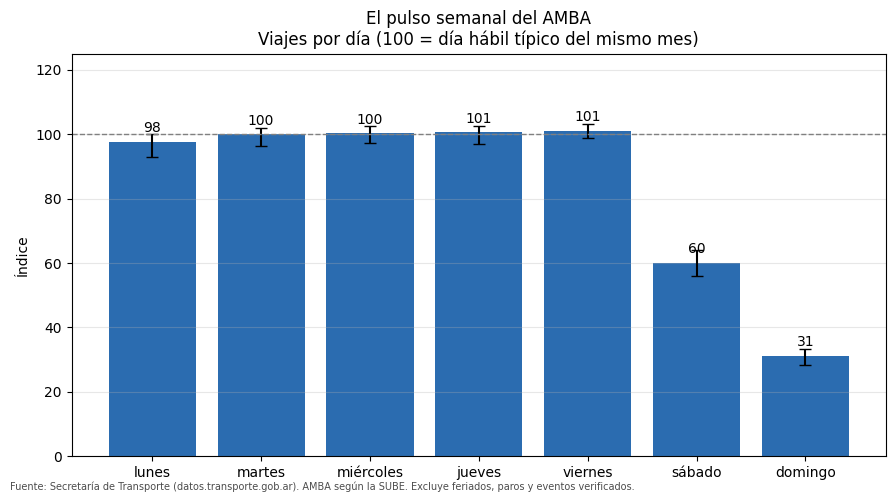

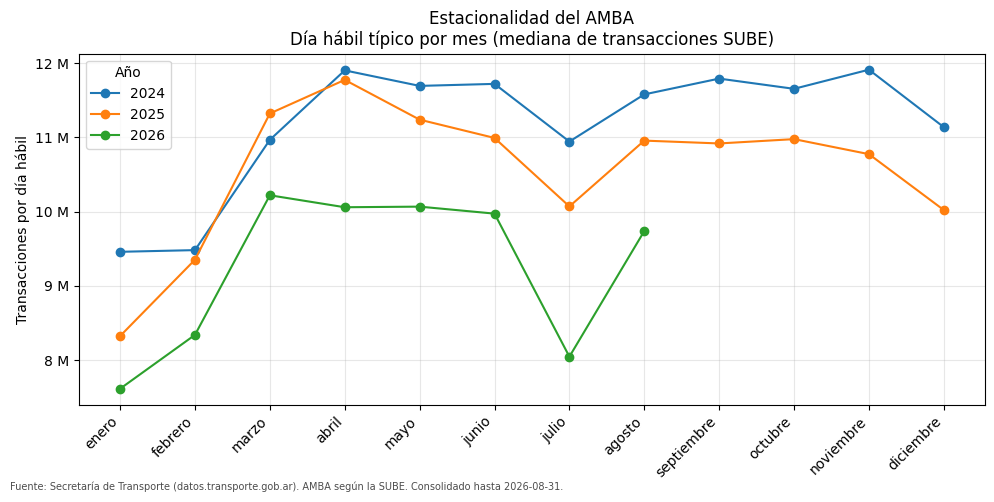

In [9]:
# El pulso del AMBA · Sección 08: eje1 pulso
# Requiere haber ejecutado antes las secciones 00 a 07 en la misma sesión.

# ============================
# 8. EJE 1 · EL PULSO DEL AMBA
# ============================


# Solo días "normales": hábiles y fines de semana sin eventos ni feriados.
mediana_dia_habil = conexion.sql(
    "SELECT MEDIAN(transacciones_total) FROM vista_diaria_amba WHERE tipo_dia = 'HABIL'").fetchone()[0]
print(f"DÍA HÁBIL TÍPICO DEL AMBA: {mediana_dia_habil:,.0f} transacciones")

# Control: la vista diaria debe reproducir el total AMBA ya verificado (abril 2025)
total_abril_2025_amba = conexion.sql(
    "SELECT SUM(transacciones_total) FROM vista_diaria_amba WHERE anio = 2025 AND mes = 4").fetchone()[0]
print(f"Control total AMBA abril 2025: {total_abril_2025_amba:,.0f} (esperado 272,239,199) →",
      "OK" if int(total_abril_2025_amba) == 272_239_199 else "FALLA")

# 8.1 Participación por modo en días hábiles
# Cociente de sumas (no mediana de cocientes) para que los porcentajes sumen 100.
# COALESCE: no hay lanchas en el AMBA según la SUBE; sin él, la suma NULL daría NaN.
participacion_modos = conexion.sql("""
    SELECT ROUND(SUM(transacciones_colectivo) / SUM(transacciones_total) * 100, 2)              AS colectivo,
           ROUND(SUM(transacciones_tren)      / SUM(transacciones_total) * 100, 2)              AS tren,
           ROUND(SUM(transacciones_subte)     / SUM(transacciones_total) * 100, 2)              AS subte,
           ROUND(COALESCE(SUM(transacciones_lanchas), 0) / SUM(transacciones_total) * 100, 2) AS lanchas
    FROM vista_diaria_amba WHERE tipo_dia = 'HABIL'
""").df()
print("\nPARTICIPACIÓN POR MODO (%)")
print(participacion_modos.to_string(index=False))

# 8.2 Perfil semanal sin tendencia
# Cada día se expresa como % de la mediana hábil de SU MISMO mes y año: así un lunes de
# 2024 y uno de 2026 son comparables aunque el nivel general haya cambiado.
perfil_indice = conexion.sql("""
    WITH base_mensual AS (
        SELECT anio, mes, MEDIAN(transacciones_total) AS mediana_habil_mes
        FROM vista_diaria_amba WHERE tipo_dia = 'HABIL' GROUP BY anio, mes
    ),
    dias_indexados AS (
        SELECT d.dia_semana, d.nombre_dia, d.transacciones_total / b.mediana_habil_mes * 100 AS indice
        FROM vista_diaria_amba AS d JOIN base_mensual AS b USING (anio, mes)
        WHERE d.tipo_dia IN ('HABIL', 'FIN_DE_SEMANA')
    )
    SELECT dia_semana, nombre_dia, COUNT(*) AS dias,
           ROUND(QUANTILE_CONT(indice, 0.25), 1) AS p25,
           ROUND(MEDIAN(indice), 1)              AS mediana,
           ROUND(QUANTILE_CONT(indice, 0.75), 1) AS p75
    FROM dias_indexados GROUP BY dia_semana, nombre_dia ORDER BY dia_semana
""").df()
print("\nPERFIL SEMANAL (100 = día hábil típico del mismo mes)")
print(perfil_indice.to_string(index=False))

# 8.3 Fin de semana por modo
fin_de_semana_modos = conexion.sql("""
    WITH base_mensual AS (
        SELECT anio, mes,
               MEDIAN(transacciones_colectivo) AS med_colectivo,
               MEDIAN(transacciones_tren)      AS med_tren,
               MEDIAN(transacciones_subte)     AS med_subte
        FROM vista_diaria_amba WHERE tipo_dia = 'HABIL' GROUP BY anio, mes
    )
    SELECT d.nombre_dia,
           ROUND(MEDIAN(d.transacciones_colectivo / b.med_colectivo * 100), 1) AS colectivo,
           ROUND(MEDIAN(d.transacciones_tren      / b.med_tren      * 100), 1) AS tren,
           ROUND(MEDIAN(d.transacciones_subte     / b.med_subte     * 100), 1) AS subte
    FROM vista_diaria_amba AS d JOIN base_mensual AS b USING (anio, mes)
    WHERE d.tipo_dia = 'FIN_DE_SEMANA'
    GROUP BY d.dia_semana, d.nombre_dia ORDER BY d.dia_semana
""").df()
print("\nFIN DE SEMANA POR MODO (% de la mediana hábil de cada modo en su mismo mes)")
print(fin_de_semana_modos.to_string(index=False))

# 8.4 Estacionalidad: mediana del día hábil por mes y año
estacionalidad = conexion.sql("""
    SELECT anio, mes, nombre_mes, MEDIAN(transacciones_total) AS mediana_dia_habil
    FROM vista_diaria_amba WHERE tipo_dia = 'HABIL'
    GROUP BY anio, mes, nombre_mes ORDER BY anio, mes
""").df()
tabla_estacional = estacionalidad.pivot(index="mes", columns="anio", values="mediana_dia_habil")
tabla_estacional.index = estacionalidad.drop_duplicates("mes").set_index("mes")["nombre_mes"]
print("\nESTACIONALIDAD (millones de transacciones por día hábil)")
print((tabla_estacional / 1e6).round(2).to_string())

# 8.5 Gráficos
NOTA_FUENTE = "Fuente: Secretaría de Transporte (datos.transporte.gob.ar). AMBA según la SUBE."

figura, eje = plt.subplots(figsize=(9, 5))
eje.bar(perfil_indice["nombre_dia"], perfil_indice["mediana"],
        yerr=[perfil_indice["mediana"] - perfil_indice["p25"], perfil_indice["p75"] - perfil_indice["mediana"]],
        capsize=4, color="#2b6cb0")
eje.axhline(100, color="gray", linestyle="--", linewidth=1)
for posicion, valor in enumerate(perfil_indice["mediana"]):
    eje.text(posicion, valor + 3, f"{valor:.0f}", ha="center", fontsize=10)
eje.set_ylim(0, 125)
eje.set_title("El pulso semanal del AMBA\nViajes por día (100 = día hábil típico del mismo mes)")
eje.set_ylabel("Índice")
eje.grid(axis="y", alpha=0.3)
figura.text(0.01, 0.01, NOTA_FUENTE + " Excluye feriados, paros y eventos verificados.", fontsize=7, alpha=0.7)
figura.tight_layout()
figura.savefig("pulso_semanal_indice_amba.png", dpi=200)
plt.show()

formato_millones = mticker.FuncFormatter(lambda valor, _: f"{valor / 1e6:.0f} M")
figura, eje = plt.subplots(figsize=(10, 5))
for anio in tabla_estacional.columns:
    eje.plot(tabla_estacional.index, tabla_estacional[anio], marker="o", label=str(anio))
eje.yaxis.set_major_formatter(formato_millones)
eje.set_title("Estacionalidad del AMBA\nDía hábil típico por mes (mediana de transacciones SUBE)")
eje.set_ylabel("Transacciones por día hábil")
eje.legend(title="Año")
eje.grid(alpha=0.3)
plt.setp(eje.get_xticklabels(), rotation=45, ha="right")
figura.text(0.01, 0.01, NOTA_FUENTE + f" Consolidado hasta {FECHA_FIN_CONSOLIDADO}.", fontsize=7, alpha=0.7)
figura.tight_layout()
figura.savefig("estacionalidad_amba.png", dpi=200)
plt.show()

## Verificación de las cifras del post 1 (slides 2 a 5)
Esperado: 26 de 26 cifras OK.

In [10]:
# El pulso del AMBA · Verificación anticipada del post 1 (slides 2 a 5)
# Requiere haber ejecutado antes las secciones 00 a 08 en la misma sesión.

# ========================================================
# VERIFICACIÓN ANTICIPADA: cifras del post 1, recalculadas
# ========================================================

# Es un adelanto de la sección 12, con las mismas funciones y tolerancias. El post 1 sale
# primero y tiene las cifras menos firmes (paros), así que se congela antes que el resto.
# Todo lo que usa ya existe al terminar la sección 08. La sección 12 completa vuelve a
# verificar estas cifras al final, junto con las de los posts 2 a 4.
# OK = el valor calculado coincide con el publicado dentro de la tolerancia del redondeo.
# REVISAR = hay que corregir la slide antes de publicar.
cifras_carrusel = []


def verificar_cifra(slide, descripcion, calculado, publicado, tolerancia):
    """Compara una cifra recalculada con la publicada en el carrusel."""
    cifras_carrusel.append({
        "slide": slide, "cifra": descripcion, "calculado": round(float(calculado), 2),
        "publicado": publicado,
        "estado": "OK" if abs(float(calculado) - publicado) <= tolerancia else "REVISAR",
    })


def verificar_condicion(slide, descripcion, calculado, condicion_cumplida, texto_publicado):
    """Para afirmaciones cualitativas ('menos de una quinta parte', etc.)."""
    cifras_carrusel.append({"slide": slide, "cifra": descripcion, "calculado": round(float(calculado), 2),
                            "publicado": texto_publicado, "estado": "OK" if condicion_cumplida else "REVISAR"})


# Slide 2 · Un día hábil
verificar_cifra(2, "Día hábil típico (millones)", mediana_dia_habil / 1e6, 10.5, 0.05)
verificar_cifra(2, "Participación colectivo (%)", participacion_modos["colectivo"][0], 84, 0.5)
verificar_cifra(2, "Participación tren (%)", participacion_modos["tren"][0], 10, 0.5)
verificar_cifra(2, "Participación subte (%)", participacion_modos["subte"][0], 5.5, 0.05)

# Slide 3 · Perfil semanal (incluye el sábado 60% y el domingo 31% de la slide 4)
for dia, publicado in zip(perfil_indice["nombre_dia"], [98, 100, 100, 101, 101, 60, 31]):
    verificar_cifra(3, f"Índice {dia}", perfil_indice.loc[perfil_indice["nombre_dia"] == dia, "mediana"].iloc[0],
                    publicado, 0.5)


# Slide 4 · Días libres
def categoria_feriado(fila):
    nombre = fila["nombre_feriado"].lower()
    if "no laborable" in nombre:
        return "Puente turístico no laborable"
    if "año nuevo" in nombre or "navidad" in nombre:
        return "Navidad y Año Nuevo"
    if "trabajador" in nombre:
        return "1 de mayo"
    if "puente" in fila["tipo_feriado"]:
        return "Feriado puente 2024 (no publicado)"
    return "Feriado nacional"


feriados_en_dia_habil["categoria"] = feriados_en_dia_habil.apply(categoria_feriado, axis=1)
rangos_feriados = feriados_en_dia_habil.groupby("categoria")["pct_total"].agg(["min", "max", "mean"])
print("Rangos por categoría de feriado (%):")
print(rangos_feriados.round(1).to_string())
for categoria, (minimo, maximo) in {"Puente turístico no laborable": (46, 63), "Feriado nacional": (27, 42),
                                    "Navidad y Año Nuevo": (14, 19)}.items():
    verificar_cifra(4, f"{categoria}: mínimo (%)", rangos_feriados.loc[categoria, "min"], minimo, 0.5)
    verificar_cifra(4, f"{categoria}: máximo (%)", rangos_feriados.loc[categoria, "max"], maximo, 0.5)
verificar_cifra(4, "1 de mayo: promedio (%)", rangos_feriados.loc["1 de mayo", "mean"], 25, 1)

# Slide 5 · Paros (AMBA, frente a un día hábil típico del mismo día de la semana, ±35 días)
paros = conexion.sql("""
    SELECT fecha, pct_total, pct_colectivo, pct_tren, pct_subte
    FROM vista_dia_vs_habil_tipico
    WHERE fecha IN ('2024-05-09', '2026-02-19', '2024-04-11', '2025-05-06', '2025-04-10')
""").df().set_index("fecha")
paros.index = paros.index.astype(str)
print("\nParos recalculados (AMBA):")
print(paros.to_string())
# Valores publicados: AMBA, frente a días hábiles del mismo día de la semana ±35 días
for fecha, publicado in {"2024-05-09": 5, "2026-02-19": 8, "2024-04-11": 33,
                         "2025-05-06": 27, "2025-04-10": 53}.items():
    verificar_cifra(5, f"Paro {fecha}: total (%)", paros.loc[fecha, "pct_total"], publicado, 0.5)
# "Colectivo a una quinta parte": se controla la frase, no un número redondeado. El valor tiene
# que estar claramente cerca de 20% (entre 18 y 22), igual que en la sección 12.
verificar_condicion(5, "Paro 2024-04-11: colectivo a una quinta parte (18–22%)",
                    paros.loc["2024-04-11", "pct_colectivo"],
                    18 <= paros.loc["2024-04-11", "pct_colectivo"] <= 22, "una quinta parte")
verificar_condicion(5, "Paro 2024-04-11: subte normal", paros.loc["2024-04-11", "pct_subte"],
                    paros.loc["2024-04-11", "pct_subte"] >= 90, "subte normal")
verificar_condicion(5, "Paro 2025-04-10: trenes y subte en 0%",
                    paros.loc["2025-04-10", ["pct_tren", "pct_subte"]].max(),
                    paros.loc["2025-04-10", ["pct_tren", "pct_subte"]].max() < 1, "0%")

# Informe
informe_post_1 = pd.DataFrame(cifras_carrusel)
print("\n" + "=" * 100 + "\nVERIFICACIÓN DE LAS CIFRAS DEL POST 1 (slides 2 a 5)\n" + "=" * 100)
print(informe_post_1.to_string(index=False))
cifras_a_revisar = informe_post_1[informe_post_1["estado"] == "REVISAR"]
print(f"\nVEREDICTO: {len(informe_post_1) - len(cifras_a_revisar)} de {len(informe_post_1)} cifras OK")
if len(cifras_a_revisar):
    print("Corregir antes de publicar:")
    print(cifras_a_revisar.to_string(index=False))
informe_post_1.to_csv("verificacion_cifras_post_1.csv", index=False, encoding="utf-8")

Rangos por categoría de feriado (%):
                                     min   max  mean
categoria                                           
1 de mayo                           24.5  25.2  24.9
Feriado nacional                    27.3  42.3  34.8
Feriado puente 2024 (no publicado)  32.1  46.0  37.0
Navidad y Año Nuevo                 13.8  19.3  15.8
Puente turístico no laborable       45.8  62.6  56.7

Paros recalculados (AMBA):
            pct_total  pct_colectivo  pct_tren  pct_subte
fecha                                                    
2025-05-06       27.3           18.1      67.4      100.4
2026-02-19        8.0            9.5       0.0        0.0
2024-05-09        4.8            5.8       0.0        0.0
2025-04-10       53.1           62.5       0.0        0.0
2024-04-11       33.0           20.5      80.2      101.1

VERIFICACIÓN DE LAS CIFRAS DEL POST 1 (slides 2 a 5)
 slide                                                  cifra  calculado        publicado estado
     2 

## Gráfico del post 1 · pictograma de colectivos
Genera `post1_colectivos.png` (1080 × 1350). Descargalo desde el panel de archivos: la vista de Colab recorta los márgenes.

ESCALA DE DÍAS (% de un día hábil típico, AMBA)
                   categoria     grupo  dias  desde  mediana  hasta          tipo_rango
                      Sábado Día libre   135   56.1     60.1   64.0 percentiles 25 a 75
         Puente no laborable Día libre     6   45.8     59.5   62.6     mínimo a máximo
Paro general, con colectivos      Paro     1   53.1     53.1   53.1     mínimo a máximo
            Feriado nacional Día libre    27   27.3     35.1   42.3     mínimo a máximo
                     Domingo Día libre   134   28.3     31.1   33.2 percentiles 25 a 75
          Paro de colectivos      Paro     2   27.3     30.2   33.0     mínimo a máximo
                   1 de mayo Día libre     3   24.5     25.0   25.2     mínimo a máximo
         Navidad y Año Nuevo Día libre     5   13.8     15.7   19.3     mínimo a máximo
                Paro general      Paro     2    4.8      6.4    8.0     mínimo a máximo
  OK      Puente no laborable: 45.8–62.6 (verificado 46–63)
  OK      Fe

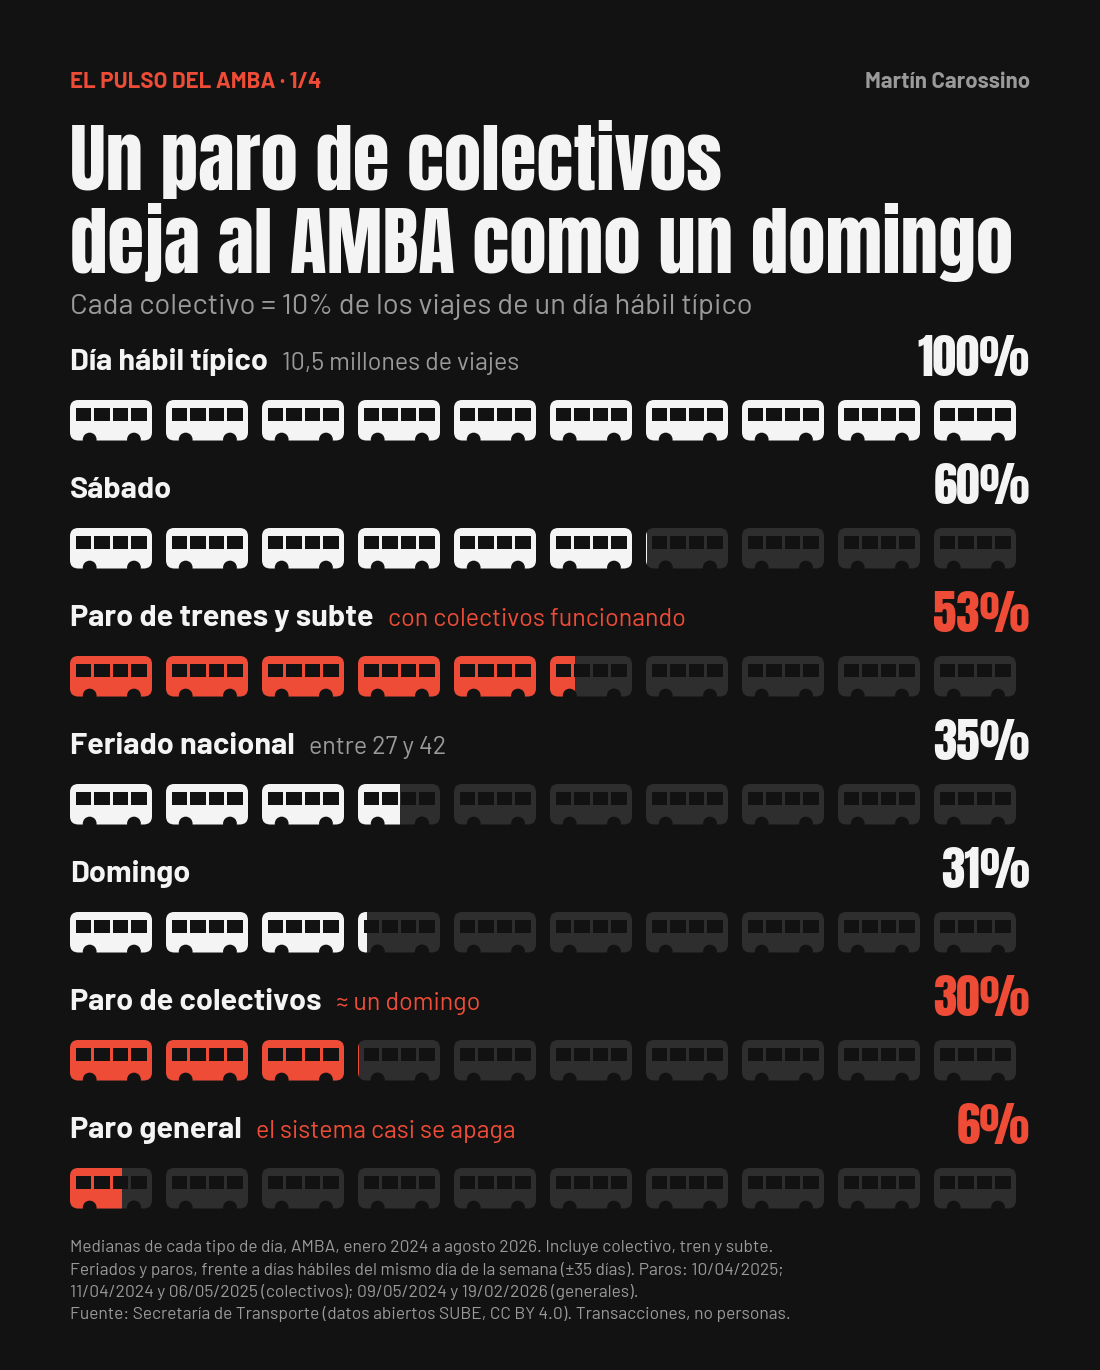

Guardado: post1_colectivos.png (1080 × 1350 px)


In [11]:
# El pulso del AMBA · Gráfico del post 1: escala única de días
# Requiere haber ejecutado antes las secciones 00 a 08 en la misma sesión.

# ===================================================================
# GRÁFICO DEL POST 1 · ¿Cuánto se mueve el AMBA según el tipo de día?
# ===================================================================

# Una sola escala: 100 = día hábil típico. Cada fila muestra un RANGO (no un punto),
# porque los días de un mismo tipo no son idénticos: el rango muestra esa variación.
import math
import os
from matplotlib import font_manager

# 1. Datos: todo se resuelve en SQL
# Hay dos referencias, y las dos significan "100 = día hábil típico":
#   · feriados y paros: días hábiles del MISMO día de la semana, ±35 días (vista_dia_vs_habil_tipico).
#     Un feriado que cae martes se compara con martes cercanos.
#   · sábados y domingos: la mediana hábil de su MISMO mes (como en la sección 8.2).
#     Un sábado no tiene "sábados hábiles" con los que compararse, por eso usa el mes.
# El rango cambia según la cantidad de días:
#   · feriados y paros (pocos días): del mínimo al máximo, sin dejar ninguno afuera;
#   · sábados y domingos (unos 130 cada uno): el 50% central (percentiles 25 a 75), porque
#     el mínimo y el máximo serían días excepcionales (vacaciones, lluvias) y no "un sábado".
escala_dias = conexion.sql("""
    WITH feriados AS (
        SELECT CASE
                   WHEN nombre_feriado ILIKE '%no laborable%'                             THEN 'Puente no laborable'
                   WHEN nombre_feriado ILIKE '%año nuevo%' OR nombre_feriado ILIKE '%navidad%' THEN 'Navidad y Año Nuevo'
                   WHEN nombre_feriado ILIKE '%trabajador%'                               THEN '1 de mayo'
                   WHEN tipo_feriado ILIKE '%puente%'                                     THEN NULL   -- puentes 2024 (eran feriados): fuera, como en la slide 4
                   ELSE 'Feriado nacional'
               END        AS categoria,
               'Día libre' AS grupo,
               pct_total
        FROM vista_dia_vs_habil_tipico
        WHERE es_feriado AND dia_semana <= 5
    ),
    paros AS (
        SELECT CASE
                   WHEN fecha IN (DATE '2024-05-09', DATE '2026-02-19') THEN 'Paro general'
                   WHEN fecha IN (DATE '2024-04-11', DATE '2025-05-06') THEN 'Paro de colectivos'
                   ELSE 'Paro general, con colectivos'                         -- 10/04/2025: los colectivos funcionaron
               END    AS categoria,
               'Paro'  AS grupo,
               pct_total
        FROM vista_dia_vs_habil_tipico
        WHERE fecha IN (DATE '2024-05-09', DATE '2026-02-19', DATE '2024-04-11',
                        DATE '2025-05-06', DATE '2025-04-10')
    ),
    eventos AS (
        SELECT categoria, grupo,
               COUNT(*)         AS dias,
               MIN(pct_total)    AS desde,
               MEDIAN(pct_total) AS mediana,
               MAX(pct_total)    AS hasta,
               'mínimo a máximo' AS tipo_rango
        FROM (SELECT * FROM feriados UNION ALL SELECT * FROM paros)
        WHERE categoria IS NOT NULL
        GROUP BY categoria, grupo
    ),
    base_mensual AS (
        SELECT anio, mes, MEDIAN(transacciones_total) AS mediana_habil_mes
        FROM vista_diaria_amba WHERE tipo_dia = 'HABIL' GROUP BY anio, mes
    ),
    fin_de_semana AS (
        SELECT CASE WHEN d.dia_semana = 6 THEN 'Sábado' ELSE 'Domingo' END AS categoria,
               'Día libre' AS grupo,
               COUNT(*) AS dias,
               QUANTILE_CONT(d.transacciones_total / b.mediana_habil_mes * 100, 0.25) AS desde,
               MEDIAN(d.transacciones_total / b.mediana_habil_mes * 100)             AS mediana,
               QUANTILE_CONT(d.transacciones_total / b.mediana_habil_mes * 100, 0.75) AS hasta,
               'percentiles 25 a 75' AS tipo_rango
        FROM vista_diaria_amba AS d JOIN base_mensual AS b USING (anio, mes)
        WHERE d.tipo_dia = 'FIN_DE_SEMANA'
        GROUP BY ALL
    )
    SELECT * FROM eventos
    UNION ALL
    SELECT * FROM fin_de_semana
    ORDER BY mediana DESC
""").df()

print("ESCALA DE DÍAS (% de un día hábil típico, AMBA)")
print(escala_dias.round(1).to_string(index=False))

def redondear(valor):
    """Redondeo "de escuela" (24,5 → 25). El round() de Python redondea al par (24,5 → 24),
    y eso haría que el gráfico muestre un número distinto del verificado."""
    return int(math.floor(valor + 0.5))


# Control: los rangos del gráfico tienen que ser los mismos ya verificados en la slide 4 y 5.
# Si alguno no coincide, el gráfico y el carrusel dirían cosas distintas.
VALORES_VERIFICADOS = {   # categoría: (desde, hasta) redondeados, según 02_cifras_publicadas.md
    "Puente no laborable": (46, 63), "Feriado nacional": (27, 42),
    "Navidad y Año Nuevo": (14, 19), "1 de mayo": (25, 25),
    "Paro general": (5, 8), "Paro de colectivos": (27, 33), "Paro general, con colectivos": (53, 53),
}
for categoria, (desde_esperado, hasta_esperado) in VALORES_VERIFICADOS.items():
    fila = escala_dias[escala_dias["categoria"] == categoria].iloc[0]
    coincide = (redondear(fila["desde"]) == desde_esperado) and (redondear(fila["hasta"]) == hasta_esperado)
    print(f"  {'OK     ' if coincide else 'REVISAR'} {categoria}: {fila['desde']:.1f}–{fila['hasta']:.1f}"
          f" (verificado {desde_esperado}–{hasta_esperado})")

# 2. Estética del afiche
# Fondo casi negro, colectivos claros y un solo color de acento (rojo) para los paros.
# El rojo pasó el validador de contraste sobre el fondo; además, cada fila dice su nombre:
# el color nunca es lo único que distingue un paro de un día libre.
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

COLOR_FONDO = "#121212"
COLOR_TEXTO = "#F4F4F4"
COLOR_TEXTO_SUAVE = "#9A9A9A"
COLOR_LLENO = "#F4F4F4"      # colectivos "con pasajeros" en días libres
COLOR_PARO = "#EE4C37"       # colectivos "con pasajeros" en días de paro
COLOR_VACIO = "#2E2E2E"      # colectivos que no salen


def cargar_fuente(nombre_archivo, url):
    """Descarga una tipografía de Google Fonts y la registra en Matplotlib.
    Si falla (sin conexión), devuelve None y el gráfico usa la tipografía por defecto."""
    try:
        if not os.path.exists(nombre_archivo):
            respuesta = requests.get(url, timeout=30)
            respuesta.raise_for_status()
            with open(nombre_archivo, "wb") as archivo:
                archivo.write(respuesta.content)
        font_manager.fontManager.addfont(nombre_archivo)
        return font_manager.FontProperties(fname=nombre_archivo)
    except Exception as error:
        print(f"No se pudo cargar {nombre_archivo} ({error}); se usa la tipografía por defecto")
        return None


URL_FUENTES = "https://github.com/google/fonts/raw/main/ofl/"
fuente_impacto = cargar_fuente("Anton-Regular.ttf", URL_FUENTES + "anton/Anton-Regular.ttf")
fuente_texto = cargar_fuente("Barlow-Regular.ttf", URL_FUENTES + "barlow/Barlow-Regular.ttf")
fuente_negrita = cargar_fuente("Barlow-Bold.ttf", URL_FUENTES + "barlow/Barlow-Bold.ttf")


def estilo(fuente, tamanio, color=COLOR_TEXTO):
    """Parámetros de texto en un solo lugar: cada texto declara su jerarquía (fuente y tamaño)."""
    if fuente is None:
        return {"fontsize": tamanio, "color": color}
    return {"fontproperties": font_manager.FontProperties(fname=fuente.get_file(), size=tamanio), "color": color}


# 3. Pictograma: 10 colectivos por fila
# Cada colectivo = 10% de los viajes de un día hábil típico. Si un día vale 35, se pintan
# 3 colectivos y medio. Las cifras son las MEDIANAS ya verificadas (02_cifras_publicadas.md).
def fila_de(categoria):
    """Devuelve la fila de escala_dias de una categoría (falla si no existe: mejor que un hueco silencioso)."""
    return escala_dias[escala_dias["categoria"] == categoria].iloc[0]


def rango_texto(categoria):
    fila = fila_de(categoria)
    return f"entre {redondear(fila['desde'])} y {redondear(fila['hasta'])}"


filas_pictograma = [   # (nombre, valor, es_paro, comentario)
    ("Día hábil típico", 100, False, f"{mediana_dia_habil / 1e6:.1f} millones de viajes".replace(".", ",")),
    ("Sábado", fila_de("Sábado")["mediana"], False, ""),
    ("Paro de trenes y subte", fila_de("Paro general, con colectivos")["mediana"], True, "con colectivos funcionando"),
    ("Feriado nacional", fila_de("Feriado nacional")["mediana"], False, rango_texto("Feriado nacional")),
    ("Domingo", fila_de("Domingo")["mediana"], False, ""),
    ("Paro de colectivos", fila_de("Paro de colectivos")["mediana"], True, "≈ un domingo"),
    ("Paro general", fila_de("Paro general")["mediana"], True, "el sistema casi se apaga"),
]


def dibujar_colectivo(eje, x, y, ancho, alto, color, recorte=None):
    """Dibuja un colectivo de costado (carrocería, ventanillas y ruedas) con su esquina inferior en (x, y).
    'recorte' es un rectángulo opcional: solo se ve la parte del colectivo que cae adentro.
    Así se pinta 'medio colectivo' sin dibujar una figura distinta."""
    partes = [
        FancyBboxPatch((x, y + alto * 0.12), ancho, alto * 0.88,
                       boxstyle=f"round,pad=0,rounding_size={alto * 0.18}", linewidth=0, facecolor=color),
    ]
    for elemento in partes:
        eje.add_patch(elemento)
        if recorte is not None:
            elemento.set_clip_path(recorte)
    # Ventanillas y ruedas en color de fondo: "agujeros" que dan forma al ícono
    ancho_ventanilla = ancho * 0.19
    for numero in range(4):
        eje.add_patch(Rectangle((x + ancho * 0.07 + numero * ancho * 0.225, y + alto * 0.55),
                                ancho_ventanilla, alto * 0.28, facecolor=COLOR_FONDO, linewidth=0))
    for posicion_rueda in (0.24, 0.78):
        eje.add_patch(Circle((x + ancho * posicion_rueda, y + alto * 0.14), alto * 0.15,
                             facecolor=COLOR_FONDO, linewidth=0))


figura = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor=COLOR_FONDO)
eje = figura.add_axes([0, 0, 1, 1], facecolor=COLOR_FONDO)
eje.set_xlim(0, 1080)   # el eje mide lo mismo que la imagen: 1 unidad = 1 píxel
eje.set_ylim(0, 1350)
eje.axis("off")
dibujante = figura.canvas.get_renderer()


def borde_derecho(texto):
    """Dónde termina un texto, en píxeles. Se mide después de dibujarlo: así el comentario
    se ubica justo al lado del nombre, sea cual sea la tipografía."""
    return texto.get_window_extent(dibujante).x1


def texto_que_entra(x, y, contenido, fuente, tamanio_maximo, ancho_maximo, **opciones):
    """Escribe un texto y, si no entra en el ancho disponible, achica la letra de a un punto."""
    for tamanio in range(tamanio_maximo, 20, -1):
        texto = eje.text(x, y, contenido, **opciones, **estilo(fuente, tamanio))
        ancho = texto.get_window_extent(dibujante).width
        if ancho <= ancho_maximo:
            return texto
        texto.remove()
    return eje.text(x, y, contenido, **opciones, **estilo(fuente, 20))


# Encabezado: la serie, el hallazgo como titular y cómo leer el gráfico
eje.text(60, 1272, "EL PULSO DEL AMBA · 1/4", **estilo(fuente_negrita, 16, COLOR_PARO))
eje.text(1020, 1272, "Martín Carossino", ha="right", **estilo(fuente_negrita, 16, COLOR_TEXTO_SUAVE))
texto_que_entra(60, 1240, "Un paro de colectivos\ndeja al AMBA como un domingo", fuente_impacto, 54, 960,
                va="top", linespacing=1.05)
eje.text(60, 1046, "Cada colectivo = 10% de los viajes de un día hábil típico", **estilo(fuente_texto, 21, COLOR_TEXTO_SUAVE))

ANCHO_COLECTIVO, ALTO_COLECTIVO, PASO = 82, 46, 96
ALTURA_FILA, Y_PRIMERA_FILA = 128, 990
for indice, (nombre, valor, es_paro, comentario) in enumerate(filas_pictograma):
    y_fila = Y_PRIMERA_FILA - indice * ALTURA_FILA
    color = COLOR_PARO if es_paro else COLOR_LLENO
    # Rótulo: nombre a la izquierda, comentario al lado, valor grande a la derecha
    texto_nombre = eje.text(60, y_fila, nombre, va="baseline", **estilo(fuente_negrita, 22))
    if comentario:
        eje.text(borde_derecho(texto_nombre) + 14, y_fila, comentario, va="baseline",
                 **estilo(fuente_texto, 18, COLOR_PARO if es_paro else COLOR_TEXTO_SUAVE))
    eje.text(1020, y_fila - 6, f"{redondear(valor)}%", ha="right", va="baseline",
             **estilo(fuente_impacto, 34, color))
    # Diez colectivos: primero todos "vacíos", después el color encima, recortado hasta el valor.
    # El recorte se calcula COLECTIVO POR COLECTIVO: la fracción pintada es del ANCHO DEL ÍCONO
    # (82 px), no del paso entre íconos (96 px, ícono + espacio).
    y_iconos = y_fila - 22 - ALTO_COLECTIVO - 8
    colectivos_llenos = valor / 10   # 35,1% → 3,51 colectivos
    for numero in range(10):
        x_colectivo = 60 + numero * PASO
        dibujar_colectivo(eje, x_colectivo, y_iconos, ANCHO_COLECTIVO, ALTO_COLECTIVO, COLOR_VACIO)
        fraccion_llena = min(max(colectivos_llenos - numero, 0), 1)   # 1 = entero, 0,51 = el cuarto, 0 = vacío
        if fraccion_llena > 0:
            recorte = Rectangle((x_colectivo, y_iconos - 5), ANCHO_COLECTIVO * fraccion_llena, ALTO_COLECTIVO + 10,
                                transform=eje.transData)
            dibujar_colectivo(eje, x_colectivo, y_iconos, ANCHO_COLECTIVO, ALTO_COLECTIVO, color, recorte)

# Pie: método y fuente
NOTA = ("Medianas de cada tipo de día, AMBA, enero 2024 a agosto 2026. Incluye colectivo, tren y subte.\n"
        "Feriados y paros, frente a días hábiles del mismo día de la semana (±35 días). Paros: 10/04/2025;\n"
        "11/04/2024 y 06/05/2025 (colectivos); 09/05/2024 y 19/02/2026 (generales).\n"
        "Fuente: Secretaría de Transporte (datos abiertos SUBE, CC BY 4.0). Transacciones, no personas.")
eje.text(60, 120, NOTA, va="top", linespacing=1.5, **estilo(fuente_texto, 12.5, COLOR_TEXTO_SUAVE))

# Control: las medianas del gráfico tienen que coincidir con la slide 3 (sábado 60, domingo 31)
for categoria, mediana_publicada in {"Sábado": 60, "Domingo": 31}.items():
    mediana_grafico = redondear(fila_de(categoria)["mediana"])
    print(f"  {'OK     ' if mediana_grafico == mediana_publicada else 'REVISAR'} {categoria}: "
          f"{mediana_grafico} en el gráfico, {mediana_publicada} en la slide 3")

figura.savefig("post1_colectivos.png", dpi=100, facecolor=COLOR_FONDO)
plt.show()
print("Guardado: post1_colectivos.png (1080 × 1350 px)")

## 09 · Eje 2: ¿viajamos menos?
Tres intentos de refutar la caída de 2026: cobertura, panel balanceado y comparación por modo. Crea `tabla_interanual` y `resumen_panel`, que usa el gráfico del post 2.

1. COBERTURA: líneas activas por día hábil (mediana mensual)
tipo_transporte  COLECTIVO  SUBTE  TREN
anio mes                               
2024 1               388.0    7.0  18.0
     2               390.0    6.0  18.0
     3               390.0    7.0  18.0
     4               390.0    7.0  17.0
     5               394.0    7.0  18.0
     6               390.0    7.0  18.0
     7               390.0    7.0  17.0
     8               390.0    7.0  18.0
     9               390.0    7.0  16.0
     10              390.0    7.0  16.0
     11              391.0    7.0  16.0
     12              389.0    7.0  16.0
2025 1               388.0    7.0  16.0
     2               388.0    7.0  16.0
     3               387.0    7.0  16.0
     4               386.0    7.0  15.0
     5               385.0    7.0  15.0
     6               386.0    7.0  15.0
     7               386.0    7.0  15.0
     8               386.0    7.0  14.0
     9               386.0    7.0  14.0
     10            

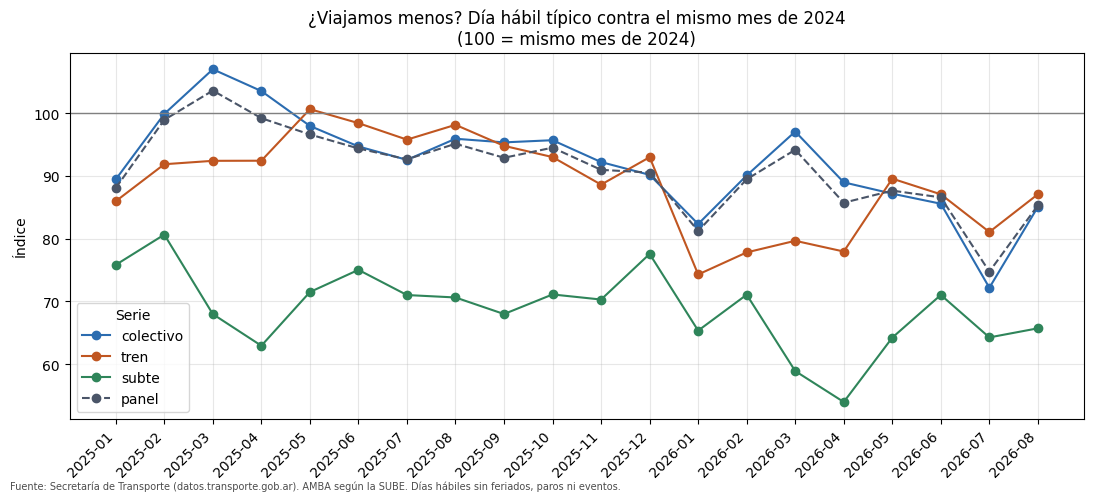

In [12]:
# El pulso del AMBA · Sección 09: eje2 viajamos menos
# Requiere haber ejecutado antes las secciones 00 a 08 en la misma sesión.

# ===============================================================
# 9. EJE 2 · ¿VIAJAMOS MENOS? — Tres intentos de refutar la caída
# ===============================================================

#   1. Cobertura: ¿informan menos líneas?
#   2. Panel balanceado: ¿la caída persiste en las líneas activas todo el período?
#   3. Por modo: ¿caen colectivo, tren y subte, o solo uno?

# 9.1 Cobertura
cobertura = conexion.sql("""
    WITH lineas_por_dia AS (
        SELECT v.fecha, v.tipo_transporte,
               COUNT(DISTINCT v.linea_id) FILTER (WHERE v.cantidad_analisis > 0) AS lineas_activas
        FROM vista_transacciones_consolidadas AS v
        JOIN vista_diaria_amba AS d ON d.fecha = v.fecha
        WHERE v.amba = 'SI' AND d.tipo_dia = 'HABIL'
        GROUP BY v.fecha, v.tipo_transporte
    )
    SELECT year(fecha) AS anio, month(fecha) AS mes, tipo_transporte,
           MEDIAN(lineas_activas) AS mediana_lineas_activas
    FROM lineas_por_dia GROUP BY ALL ORDER BY anio, mes, tipo_transporte
""").df()
print("1. COBERTURA: líneas activas por día hábil (mediana mensual)")
print(cobertura.pivot_table(index=["anio", "mes"], columns="tipo_transporte",
                            values="mediana_lineas_activas").to_string())

# 9.2 Panel balanceado
# clave_linea: el número para nacionales y porteñas (une el traspaso de 2025); el id para el resto
CONSULTA_LINEAS_AMBA = """
    SELECT v.fecha, v.tipo_transporte,
           CASE WHEN v.numero_linea IS NOT NULL THEN 'N' || v.numero_linea ELSE 'L' || v.linea_id END AS clave_linea,
           v.cantidad_analisis
    FROM vista_transacciones_consolidadas AS v WHERE v.amba = 'SI'
"""
CTE_PANEL = f"""
    lineas_amba AS ({CONSULTA_LINEAS_AMBA}),
    meses_por_linea AS (
        SELECT clave_linea, COUNT(DISTINCT strftime(fecha, '%Y-%m')) AS meses_activos
        FROM lineas_amba WHERE cantidad_analisis > 0 GROUP BY clave_linea
    ),
    total_meses AS (SELECT COUNT(DISTINCT strftime(fecha, '%Y-%m')) AS meses FROM lineas_amba),
    lineas_panel AS (
        SELECT clave_linea FROM meses_por_linea WHERE meses_activos = (SELECT meses FROM total_meses)
    )
"""
resumen_panel = conexion.sql(f"""
    WITH {CTE_PANEL}
    SELECT (SELECT COUNT(*) FROM meses_por_linea) AS lineas_totales,
           (SELECT COUNT(*) FROM lineas_panel)    AS lineas_en_panel,
           (SELECT meses FROM total_meses)        AS meses_del_periodo
""").df()
print("\n2. PANEL BALANCEADO")
print(resumen_panel.to_string(index=False))

panel_mensual = conexion.sql(f"""
    WITH {CTE_PANEL},
    total_diario_panel AS (
        SELECT l.fecha, SUM(l.cantidad_analisis) AS total_panel
        FROM lineas_amba AS l JOIN lineas_panel USING (clave_linea)
        GROUP BY l.fecha
    )
    SELECT d.anio, d.mes,
           MEDIAN(p.total_panel)             AS panel,
           MEDIAN(d.transacciones_total)     AS total,
           MEDIAN(d.transacciones_colectivo) AS colectivo,
           MEDIAN(d.transacciones_tren)      AS tren,
           MEDIAN(d.transacciones_subte)     AS subte
    FROM total_diario_panel AS p JOIN vista_diaria_amba AS d ON d.fecha = p.fecha
    WHERE d.tipo_dia = 'HABIL'
    GROUP BY d.anio, d.mes ORDER BY d.anio, d.mes
""").df()
panel_mensual["pct_panel_del_total"] = (panel_mensual["panel"] / panel_mensual["total"] * 100).round(1)
print("Peso del panel en el total por año (min–max %):")
print(panel_mensual.groupby("anio")["pct_panel_del_total"].agg(["min", "max"]).to_string())

# 9.3 Variación interanual: mismo mes contra mismo mes (elimina la estacionalidad)
SERIES_A_COMPARAR = ["total", "panel", "colectivo", "tren", "subte"]
MESES_COMPARABLES = range(1, 9)   # enero–agosto: disponibles en los tres años


def variaciones_interanuales(datos, serie, anio_actual):
    """Variaciones % de cada mes contra el mismo mes del año anterior."""
    actual = datos[(datos["anio"] == anio_actual) & datos["mes"].isin(MESES_COMPARABLES)].set_index("mes")[serie]
    anterior = datos[(datos["anio"] == anio_actual - 1) & datos["mes"].isin(MESES_COMPARABLES)].set_index("mes")[serie]
    return (actual / anterior - 1) * 100


filas_interanual = []
for serie in SERIES_A_COMPARAR:
    variaciones_2025 = variaciones_interanuales(panel_mensual, serie, 2025)
    variaciones_2026 = variaciones_interanuales(panel_mensual, serie, 2026)
    filas_interanual.append({
        "serie": serie,
        "var_2025_vs_2024": round(variaciones_2025.mean(), 1),
        "var_2026_vs_2025": round(variaciones_2026.mean(), 1),
        "peor_mes_2026": round(variaciones_2026.min(), 1),
        "mejor_mes_2026": round(variaciones_2026.max(), 1),
    })
tabla_interanual = pd.DataFrame(filas_interanual).set_index("serie")
print("\n3. VARIACIÓN INTERANUAL PROMEDIO (%, enero–agosto, día hábil típico)")
print(tabla_interanual.to_string())

# 9.4 Gráfico: cada mes contra el mismo mes de 2024
base_2024 = panel_mensual[panel_mensual["anio"] == 2024].set_index("mes")
indices = panel_mensual[panel_mensual["anio"] >= 2025].copy()
for serie in SERIES_A_COMPARAR:
    indices[f"indice_{serie}"] = indices[serie] / indices["mes"].map(base_2024[serie]) * 100
indices["periodo"] = indices["anio"].astype(str) + "-" + indices["mes"].astype(str).str.zfill(2)

figura, eje = plt.subplots(figsize=(11, 5))
for serie, color in {"colectivo": "#2b6cb0", "tren": "#c05621", "subte": "#2f855a", "panel": "#4a5568"}.items():
    eje.plot(indices["periodo"], indices[f"indice_{serie}"], marker="o", color=color, label=serie,
             linestyle="--" if serie == "panel" else "-")
eje.axhline(100, color="gray", linewidth=1)
eje.set_title("¿Viajamos menos? Día hábil típico contra el mismo mes de 2024\n(100 = mismo mes de 2024)")
eje.set_ylabel("Índice")
eje.legend(title="Serie")
eje.grid(alpha=0.3)
plt.setp(eje.get_xticklabels(), rotation=45, ha="right")
figura.text(0.01, 0.01, NOTA_FUENTE + " Días hábiles sin feriados, paros ni eventos.", fontsize=7, alpha=0.7)
figura.tight_layout()
figura.savefig("variacion_interanual_amba.png", dpi=200)
plt.show()

## Gráfico del post 2 · pictograma de la caída
Controla 11 cifras contra la slide 6 antes de dibujar (esperado: 11 de 11 OK). Genera `post2_viajamos_menos.png` (1080 × 1350). Descargalo desde el panel de archivos.

VERIFICACIÓN DE LAS CIFRAS DEL GRÁFICO DEL POST 2 (slide 6)
  OK      Variación total (%): calculado -11.8, publicado -11.8
  OK      Variación colectivo (%): calculado -11.9, publicado -11.9
  OK      Variación tren (%): calculado -13.4, publicado -13.4
  OK      Variación subte (%): calculado -10.7, publicado -10.7
  OK      Variación panel (%): calculado -10.9, publicado -10.9
  OK      Peor mes del total (%): calculado -20.1, publicado -20.1
  OK      Mejor mes del total (%): calculado -8.5, publicado -8.5
  OK      Líneas en el panel: calculado 381, publicado 381
  OK      Meses del período: calculado 32, publicado 32
  OK      Ningún mes mejoró: total: calculado -8.5, publicado < 0
  OK      Ningún mes mejoró: panel: calculado -7.8, publicado < 0

VEREDICTO: 11 de 11 controles OK


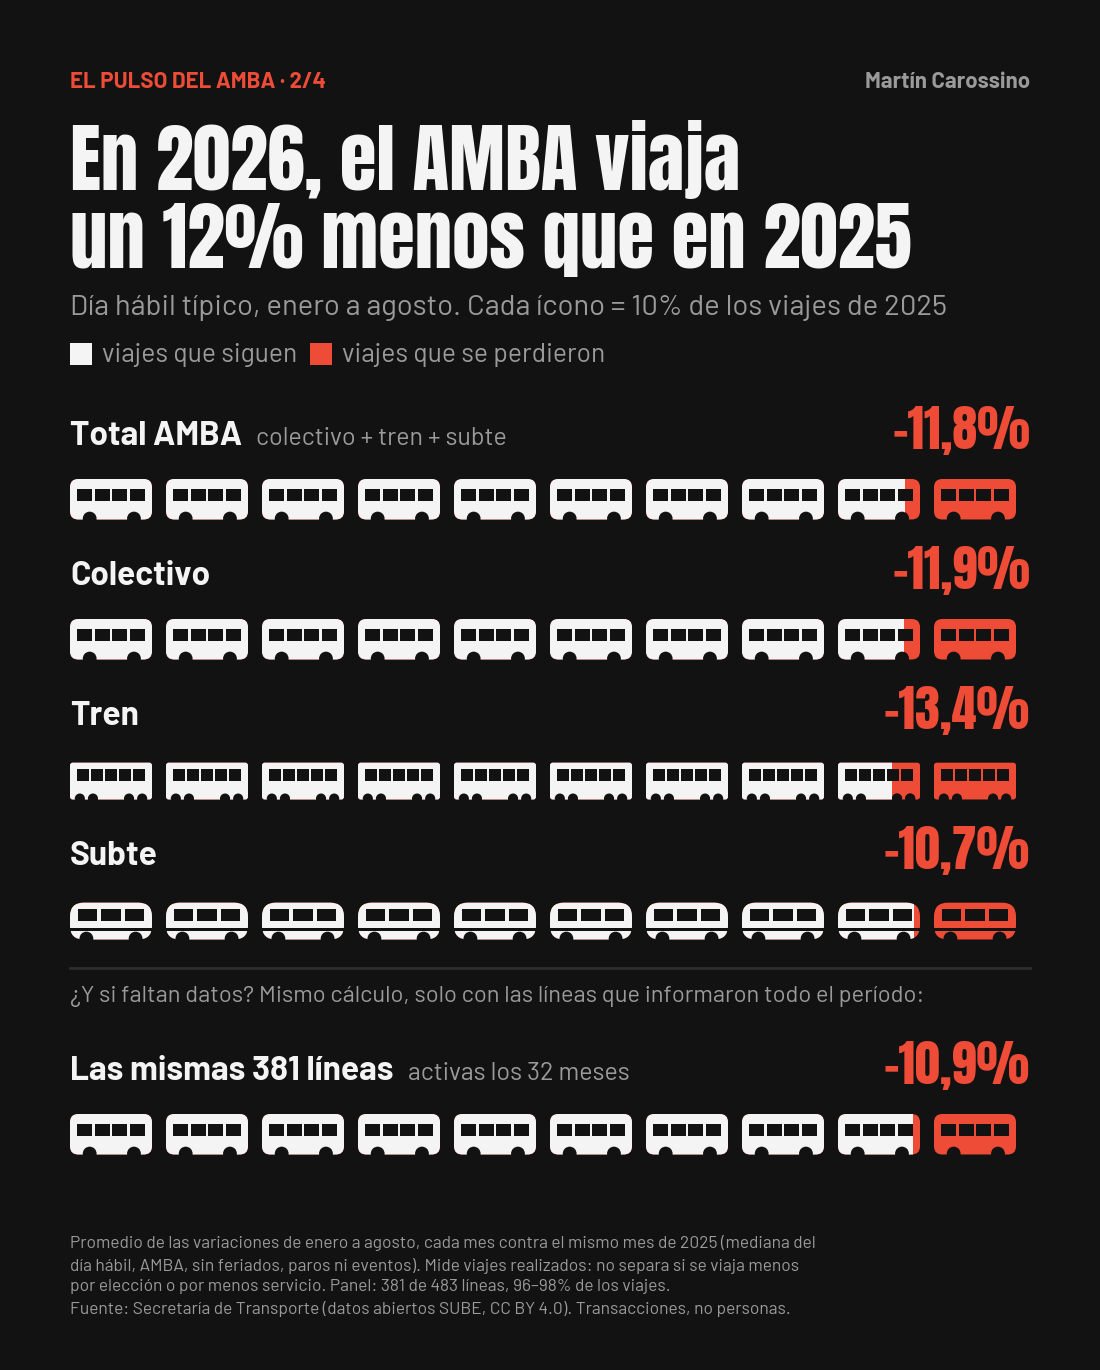

Guardado: post2_viajamos_menos.png (1080 × 1350 px)


In [13]:
# El pulso del AMBA · Gráfico del post 2: ¿viajamos menos?
# Requiere haber ejecutado antes las secciones 00 a 09 en la misma sesión
# (usa tabla_interanual y resumen_panel, creadas en la sección 09).

# ========================================================
# GRÁFICO DEL POST 2 · En 2026, el AMBA viaja un 12% menos
# ========================================================

# Mismo lenguaje visual que el post 1: 10 íconos por fila, fondo oscuro, un solo acento.
# Cambia lo que vale cada ícono: acá, 10% de los viajes del MISMO PERÍODO DE 2025.
# Así las cinco filas arrancan llenas (2025 = 10 íconos) y el rojo marca lo que se perdió.
import math
import os
from matplotlib import font_manager
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

# 1. Datos: se toman de la sección 09, ya verificada
# No se recalcula nada: el gráfico tiene que mostrar EXACTAMENTE las cifras de la slide 6.
def redondear(valor):
    """Redondeo "de escuela" (24,5 → 25). El round() de Python redondea al par (24,5 → 24),
    y eso haría que el gráfico muestre un número distinto del verificado."""
    return int(math.floor(valor + 0.5))

# 2. Control: las cifras de la sección 09 contra las publicadas en la slide 6
# Igual que en el post 1, el gráfico no se dibuja con cifras que no coinciden.
# Tolerancia 0,05: tabla_interanual ya viene redondeada a un decimal, así que tienen que
# ser idénticas; la tolerancia solo absorbe la representación de los decimales en memoria.
CIFRAS_PUBLICADAS_SLIDE_6 = {   # serie: variación 2026 vs 2025 (%), según 02_cifras_publicadas.md
    "total": -11.8, "colectivo": -11.9, "tren": -13.4, "subte": -10.7, "panel": -10.9,
}
controles_post_2 = []
for serie, publicado in CIFRAS_PUBLICADAS_SLIDE_6.items():
    calculado = tabla_interanual.loc[serie, "var_2026_vs_2025"]
    controles_post_2.append((f"Variación {serie} (%)", calculado, publicado, abs(calculado - publicado) <= 0.05))

controles_post_2.append(("Peor mes del total (%)", tabla_interanual.loc["total", "peor_mes_2026"], -20.1,
                         abs(tabla_interanual.loc["total", "peor_mes_2026"] + 20.1) <= 0.05))
controles_post_2.append(("Mejor mes del total (%)", tabla_interanual.loc["total", "mejor_mes_2026"], -8.5,
                         abs(tabla_interanual.loc["total", "mejor_mes_2026"] + 8.5) <= 0.05))
controles_post_2.append(("Líneas en el panel", resumen_panel["lineas_en_panel"].iloc[0], 381,
                         int(resumen_panel["lineas_en_panel"].iloc[0]) == 381))
controles_post_2.append(("Meses del período", resumen_panel["meses_del_periodo"].iloc[0], 32,
                         int(resumen_panel["meses_del_periodo"].iloc[0]) == 32))
# "Ningún mes mejoró": el MEJOR mes tiene que seguir siendo negativo. Solo para el total y el
# panel, que es lo que afirma la slide 6; por modo no se publicó nada mes a mes.
for serie in ["total", "panel"]:
    mejor_mes = tabla_interanual.loc[serie, "mejor_mes_2026"]
    controles_post_2.append((f"Ningún mes mejoró: {serie}", mejor_mes, "< 0", mejor_mes < 0))

print("VERIFICACIÓN DE LAS CIFRAS DEL GRÁFICO DEL POST 2 (slide 6)")
for descripcion, calculado, publicado, coincide in controles_post_2:
    print(f"  {'OK     ' if coincide else 'REVISAR'} {descripcion}: calculado {calculado}, publicado {publicado}")
cantidad_ok = sum(coincide for *_, coincide in controles_post_2)
print(f"\nVEREDICTO: {cantidad_ok} de {len(controles_post_2)} controles OK")
# assert detiene la celda si algo no coincide: mejor sin gráfico que un gráfico con una cifra falsa
assert cantidad_ok == len(controles_post_2), "Hay cifras que no coinciden con la slide 6: no se dibuja el gráfico"

# Cada fila: (nombre, vehículo, variación %, comentario). El valor que se pinta es 100 + variación:
# −11,8% → 88,2 de cada 100 viajes de 2025 siguen estando.
filas_pictograma = [
    ("Total AMBA",        "colectivo", tabla_interanual.loc["total", "var_2026_vs_2025"],     "colectivo + tren + subte"),
    ("Colectivo",         "colectivo", tabla_interanual.loc["colectivo", "var_2026_vs_2025"], ""),
    ("Tren",              "tren",      tabla_interanual.loc["tren", "var_2026_vs_2025"],      ""),
    ("Subte",             "subte",     tabla_interanual.loc["subte", "var_2026_vs_2025"],     ""),
    ("Las mismas 381 líneas", "colectivo", tabla_interanual.loc["panel", "var_2026_vs_2025"],
     "activas los 32 meses"),
]

# 3. Estética: la misma paleta y las mismas tipografías del post 1
COLOR_FONDO = "#121212"
COLOR_TEXTO = "#F4F4F4"
COLOR_TEXTO_SUAVE = "#9A9A9A"
COLOR_LLENO = "#F4F4F4"      # viajes que siguen estando en 2026
COLOR_PERDIDO = "#EE4C37"    # viajes que se perdieron frente a 2025 (el mismo rojo del post 1)
COLOR_SEPARADOR = "#2E2E2E"


def cargar_fuente(nombre_archivo, url):
    """Descarga una tipografía de Google Fonts y la registra en Matplotlib.
    Si falla (sin conexión), devuelve None y el gráfico usa la tipografía por defecto."""
    try:
        if not os.path.exists(nombre_archivo):
            respuesta = requests.get(url, timeout=30)
            respuesta.raise_for_status()
            with open(nombre_archivo, "wb") as archivo:
                archivo.write(respuesta.content)
        font_manager.fontManager.addfont(nombre_archivo)
        return font_manager.FontProperties(fname=nombre_archivo)
    except Exception as error:
        print(f"No se pudo cargar {nombre_archivo} ({error}); se usa la tipografía por defecto")
        return None


URL_FUENTES = "https://github.com/google/fonts/raw/main/ofl/"
fuente_impacto = cargar_fuente("Anton-Regular.ttf", URL_FUENTES + "anton/Anton-Regular.ttf")
fuente_texto = cargar_fuente("Barlow-Regular.ttf", URL_FUENTES + "barlow/Barlow-Regular.ttf")
fuente_negrita = cargar_fuente("Barlow-Bold.ttf", URL_FUENTES + "barlow/Barlow-Bold.ttf")


def estilo(fuente, tamanio, color=COLOR_TEXTO):
    """Parámetros de texto en un solo lugar: cada texto declara su jerarquía (fuente y tamaño)."""
    if fuente is None:
        return {"fontsize": tamanio, "color": color}
    return {"fontproperties": font_manager.FontProperties(fname=fuente.get_file(), size=tamanio), "color": color}


def formato_porcentaje(valor):
    """−11,8 → '−11,8%': coma decimal y signo menos tipográfico, como en el texto del post."""
    return f"{valor:+.1f}%".replace("-", "−").replace(".", ",")


# 4. Íconos: un vehículo por modo
# Cada fila usa el vehículo de su modo, para que el lector no tenga que leer el rótulo para
# saber de qué se habla. El total y el panel usan el colectivo: es el 84% de los viajes.
def dibujar_vehiculo(eje, tipo, x, y, ancho, alto, color, recorte=None):
    """Dibuja un vehículo de costado con su esquina inferior en (x, y).
    'recorte' es un rectángulo opcional: solo se ve la parte del vehículo que cae adentro.
    Así se pinta "medio vehículo" de un color y el resto de otro, sin dibujar figuras distintas."""
    if tipo == "colectivo":
        redondeo, ventanillas, ruedas, techo = alto * 0.18, 4, (0.24, 0.78), 0.88
    elif tipo == "tren":
        redondeo, ventanillas, ruedas, techo = alto * 0.06, 5, (0.12, 0.28, 0.72, 0.88), 0.80
    else:   # subte: más bajo, frente redondeado y una franja en lugar de ruedas visibles
        redondeo, ventanillas, ruedas, techo = alto * 0.30, 3, (0.20, 0.80), 0.80
    carroceria = FancyBboxPatch((x, y + alto * 0.12), ancho, alto * techo,
                                boxstyle=f"round,pad=0,rounding_size={redondeo}", linewidth=0, facecolor=color)
    eje.add_patch(carroceria)
    if recorte is not None:
        carroceria.set_clip_path(recorte)
    # Ventanillas y ruedas en color de fondo: "agujeros" que dan forma al ícono.
    # Van sin recorte: son del color del fondo, se ven igual sobre cualquier carrocería.
    margen = ancho * 0.07
    paso_ventanilla = (ancho - 2 * margen) / ventanillas
    for numero in range(ventanillas):
        eje.add_patch(Rectangle((x + margen + numero * paso_ventanilla + paso_ventanilla * 0.08, y + alto * 0.52),
                                paso_ventanilla * 0.84, alto * 0.26, facecolor=COLOR_FONDO, linewidth=0))
    if tipo == "subte":
        eje.add_patch(Rectangle((x, y + alto * 0.30), ancho, alto * 0.06, facecolor=COLOR_FONDO, linewidth=0))
    for posicion_rueda in ruedas:
        eje.add_patch(Circle((x + ancho * posicion_rueda, y + alto * 0.14), alto * (0.11 if tipo == "tren" else 0.15),
                             facecolor=COLOR_FONDO, linewidth=0))


# 5. Afiche
figura = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor=COLOR_FONDO)
eje = figura.add_axes([0, 0, 1, 1], facecolor=COLOR_FONDO)
eje.set_xlim(0, 1080)   # el eje mide lo mismo que la imagen: 1 unidad = 1 píxel
eje.set_ylim(0, 1350)
eje.axis("off")
dibujante = figura.canvas.get_renderer()


def borde_derecho(texto):
    """Dónde termina un texto, en píxeles. Se mide después de dibujarlo: así el comentario
    se ubica justo al lado del nombre, sea cual sea la tipografía."""
    return texto.get_window_extent(dibujante).x1


# Encabezado: la serie, el hallazgo como titular y cómo leer el gráfico.
# El titular dice "12%" (redondeo de −11,8) y nombra el período: sin el período, "12% menos"
# podría leerse como el año completo, y septiembre a diciembre todavía no están en el análisis.
variacion_total = tabla_interanual.loc["total", "var_2026_vs_2025"]
eje.text(60, 1272, "EL PULSO DEL AMBA · 2/4", **estilo(fuente_negrita, 16, COLOR_PERDIDO))
eje.text(1020, 1272, "Martín Carossino", ha="right", **estilo(fuente_negrita, 16, COLOR_TEXTO_SUAVE))
eje.text(60, 1240, f"En 2026, el AMBA viaja\nun {redondear(-variacion_total)}% menos que en 2025",
         va="top", linespacing=1.05, **estilo(fuente_impacto, 54))
# Posiciones medidas sobre la salida de Colab: con Anton descargada de Google Fonts, el
# titular de dos líneas termina cerca de y = 1095, así que el subtítulo va justo debajo.
eje.text(60, 1045, "Día hábil típico, enero a agosto. Cada ícono = 10% de los viajes de 2025",
         **estilo(fuente_texto, 21, COLOR_TEXTO_SUAVE))

# Leyenda: el rojo es lo único nuevo respecto del post 1, así que se explica una sola vez
eje.add_patch(Rectangle((60, 995), 22, 22, facecolor=COLOR_LLENO, linewidth=0))
eje.text(92, 998, "viajes que siguen", **estilo(fuente_texto, 19, COLOR_TEXTO_SUAVE))
eje.add_patch(Rectangle((300, 995), 22, 22, facecolor=COLOR_PERDIDO, linewidth=0))
eje.text(332, 998, "viajes que se perdieron", **estilo(fuente_texto, 19, COLOR_TEXTO_SUAVE))

ANCHO_ICONO, ALTO_ICONO, PASO = 82, 46, 96
ALTURA_FILA, Y_PRIMERA_FILA = 140, 915
for indice, (nombre, vehiculo, variacion, comentario) in enumerate(filas_pictograma):
    # La fila del panel se separa un poco más: no es "un modo más", es la prueba de que
    # la caída no es un faltante de datos. La línea divisoria marca ese cambio de pregunta.
    desplazamiento_panel = 75 if indice == 4 else 0
    y_fila = Y_PRIMERA_FILA - indice * ALTURA_FILA - desplazamiento_panel
    if indice == 4:
        eje.plot([60, 1020], [y_fila + 112, y_fila + 112], color=COLOR_SEPARADOR, linewidth=2)
        eje.text(60, y_fila + 78, "¿Y si faltan datos? Mismo cálculo, solo con las líneas que informaron todo el período:",
                 **estilo(fuente_texto, 17, COLOR_TEXTO_SUAVE))

    # Rótulo: nombre a la izquierda, comentario al lado, variación grande a la derecha
    texto_nombre = eje.text(60, y_fila, nombre, va="baseline", **estilo(fuente_negrita, 24))
    if comentario:
        eje.text(borde_derecho(texto_nombre) + 14, y_fila, comentario, va="baseline",
                 **estilo(fuente_texto, 18, COLOR_TEXTO_SUAVE))
    eje.text(1020, y_fila - 4, formato_porcentaje(variacion), ha="right", va="baseline",
             **estilo(fuente_impacto, 36, COLOR_PERDIDO))

    # Diez íconos: primero todos en rojo (lo que había en 2025), después el blanco encima,
    # recortado hasta lo que queda en 2026. Lo que no tapa el blanco es lo que se perdió.
    # El recorte se calcula ÍCONO POR ÍCONO: la fracción pintada es del ANCHO DEL ÍCONO, no
    # del paso entre íconos. Si se midiera sobre el paso (ícono + espacio vacío), 88,2 pintaría
    # el noveno ícono entero y el gráfico mostraría ≈ −10% en vez de −11,8%.
    y_iconos = y_fila - 24 - ALTO_ICONO - 10
    iconos_que_siguen = (100 + variacion) / 10    # −11,8% → 88,2 de cada 100 → 8,82 íconos
    for numero in range(10):
        x_icono = 60 + numero * PASO
        dibujar_vehiculo(eje, vehiculo, x_icono, y_iconos, ANCHO_ICONO, ALTO_ICONO, COLOR_PERDIDO)
        fraccion_blanca = min(max(iconos_que_siguen - numero, 0), 1)   # 1 = entero, 0,82 = el noveno, 0 = vacío
        if fraccion_blanca > 0:
            recorte = Rectangle((x_icono, y_iconos - 5), ANCHO_ICONO * fraccion_blanca, ALTO_ICONO + 10,
                                transform=eje.transData)
            dibujar_vehiculo(eje, vehiculo, x_icono, y_iconos, ANCHO_ICONO, ALTO_ICONO, COLOR_LLENO, recorte)

# Pie: método y fuente. "Viajes realizados" va escrito a propósito: la SUBE no dice si la
# gente viaja menos porque quiere o porque hay menos servicio (ver bitácora, sección 6).
NOTA = ("Promedio de las variaciones de enero a agosto, cada mes contra el mismo mes de 2025 (mediana del\n"
        "día hábil, AMBA, sin feriados, paros ni eventos). Mide viajes realizados: no separa si se viaja menos\n"
        "por elección o por menos servicio. Panel: 381 de 483 líneas, 96–98% de los viajes.\n"
        "Fuente: Secretaría de Transporte (datos abiertos SUBE, CC BY 4.0). Transacciones, no personas.")
eje.text(60, 125, NOTA, va="top", linespacing=1.5, **estilo(fuente_texto, 12.5, COLOR_TEXTO_SUAVE))

figura.savefig("post2_viajamos_menos.png", dpi=100, facecolor=COLOR_FONDO)
plt.show()
print("Guardado: post2_viajamos_menos.png (1080 × 1350 px)")

## 10 · Eje 3: ¿o pagamos distinto?
Tarjeta SUBE, QR y contraste con el BCRA. Lee `datos_bcra.csv` (única fuente de las cifras del BCRA) y se detiene si la slide 7 no da 8 de 8.
En 10.1, julio de 2025 en REVISAR es esperado: diferencia interna del BCRA (bitácora, sección 2).

In [14]:
# El pulso del AMBA · Sección 10: eje3 tarjeta qr bcra
# Requiere haber ejecutado antes las secciones 00 a 09 en la misma sesión.
# datos_bcra.csv se busca en la sesión de Colab y en la raíz de Google Drive;
# si no está en ninguna de las dos, se descarga del repositorio en GitHub.

# =========================================================================
# 10. EJE 3 · ¿O PAGAMOS DISTINTO? TARJETA SUBE, QR Y CONTRASTE CON EL BCRA
# =========================================================================

# Fuente: BCRA, Informes de Pagos Minoristas, cargados a mano en datos_bcra.csv
# (una fila por mes y medio de pago, con el informe de origen de cada cifra).
# Ojo con los meses: el informe del mes M trae la tarjeta SUBE del mes M-1 y el QR del mes M
# (lo dice la nota al pie de cada informe). El CSV guarda cada cifra en el MES DE LOS DATOS,
# no en el mes del informe.
import os

INICIO_VIAJE_CON_QR = "2025-05-01"       # el BCRA habilitó el Viaje con QR el 12/05/2025: antes, QR = 0
TOLERANCIA_REDONDEO_BCRA_PCT = 0.2       # el BCRA redondea viajes a 0,1 M y la variación a 0,1 punto

# 10.0 Carga de la serie del BCRA en DuckDB
# El CSV es la ÚNICA fuente de las cifras del BCRA: si una cifra cambia, se cambia
# ahí (con su informe de origen) y no en el código.
URL_DATOS_BCRA = "https://raw.githubusercontent.com/MartinCarossino/pulso-amba-sube/main/datos_bcra.csv"
RUTAS_POSIBLES_BCRA = ["datos_bcra.csv", "/content/drive/MyDrive/datos_bcra.csv"]
ruta_datos_bcra = next((ruta for ruta in RUTAS_POSIBLES_BCRA if os.path.exists(ruta)), None)
if ruta_datos_bcra is None:
    # Quien abre el notebook desde GitHub no tiene el CSV en la sesión: se baja del repositorio.
    # Primero se guarda en disco, en vez de leer la URL directo, para que pandas y DuckDB lean
    # exactamente el mismo archivo en el control de carga de abajo.
    respuesta = requests.get(URL_DATOS_BCRA, timeout=30)
    respuesta.raise_for_status()   # si falla, que se note: sin la serie del BCRA no hay sección 10
    with open("datos_bcra.csv", "wb") as archivo:
        archivo.write(respuesta.content)
    ruta_datos_bcra = "datos_bcra.csv"
    print(f"datos_bcra.csv descargado de {URL_DATOS_BCRA}")

# all_varchar evita que DuckDB "adivine" tipos; los convertimos nosotros, a la vista.
# NULLIF + TRY_CAST: la variación interanual viene vacía en las filas de QR.
conexion.execute(f"""
CREATE OR REPLACE TABLE bcra_viajes_mensuales AS
SELECT
    CAST(mes_de_los_datos || '-01' AS DATE)                    AS mes,
    medio_de_pago,
    CAST(viajes AS BIGINT)                                     AS viajes,
    TRY_CAST(NULLIF(variacion_interanual_pct, '') AS DOUBLE)   AS variacion_interanual_pct,
    es_estimado = 'SI'                                         AS es_estimado,
    informe_de_origen,
    url
FROM read_csv('{ruta_datos_bcra}', header = true, all_varchar = true)
""")

# Control de carga: DuckDB tiene que leer exactamente las filas que ve pandas,
# y no puede haber dos cifras para el mismo mes y medio de pago.
filas_csv_pandas = len(pd.read_csv(ruta_datos_bcra))
filas_tabla_bcra, combinaciones_unicas = conexion.sql("""
    SELECT COUNT(*), COUNT(DISTINCT (mes, medio_de_pago)) FROM bcra_viajes_mensuales
""").fetchone()
print(f"Serie del BCRA: {filas_tabla_bcra} filas (pandas: {filas_csv_pandas}) | "
      f"mes y medio repetidos: {filas_tabla_bcra - combinaciones_unicas} | archivo: {ruta_datos_bcra}")
if filas_tabla_bcra != filas_csv_pandas or filas_tabla_bcra != combinaciones_unicas:
    raise ValueError("La carga de datos_bcra.csv no es fiel al archivo: revisar antes de seguir")

# 10.1 Coherencia interna del BCRA (control de la carga manual)
# Cada informe publica la tarjeta del mes Y su variación interanual. Con las dos se puede
# reconstruir el mismo mes del año anterior: viajes / (1 + variación). Si el valor
# reconstruido no coincide con el que cargamos de OTRO informe, hay un error de tipeo
# o el BCRA revisó el dato. Es una verificación cruzada entre dos informes distintos.
coherencia_bcra = conexion.sql(f"""
    SELECT
        strftime(actual.mes, '%Y-%m')                                        AS mes,
        ROUND(actual.viajes / 1e6, 1)                                        AS tarjeta_millones,
        actual.variacion_interanual_pct,
        strftime(anterior.mes, '%Y-%m')                                      AS mes_anio_anterior,
        ROUND(anterior.viajes / 1e6, 1)                                      AS cargado_millones,
        ROUND(actual.viajes / (1 + actual.variacion_interanual_pct / 100) / 1e6, 1)
                                                                             AS reconstruido_millones,
        ROUND((actual.viajes / (1 + actual.variacion_interanual_pct / 100)
               / anterior.viajes - 1) * 100, 2)                              AS diferencia_pct
    FROM bcra_viajes_mensuales AS actual
    JOIN bcra_viajes_mensuales AS anterior
      ON  anterior.medio_de_pago = 'tarjeta_sube'
      AND anterior.mes = CAST(actual.mes - INTERVAL 1 YEAR AS DATE)
      AND NOT anterior.es_estimado          -- un estimado contra su propia fórmula sería circular
    WHERE actual.medio_de_pago = 'tarjeta_sube'
      AND actual.variacion_interanual_pct IS NOT NULL
    ORDER BY actual.mes
""").df()
coherencia_bcra["estado"] = coherencia_bcra["diferencia_pct"].abs().le(TOLERANCIA_REDONDEO_BCRA_PCT).map(
    {True: "OK", False: "REVISAR"})
print("\n10.1 COHERENCIA INTERNA DEL BCRA (mes del año anterior reconstruido con la variación interanual)")
print(coherencia_bcra.to_string(index=False))

# 10.2 Relación dataset / tarjeta SUBE a lo largo del tiempo
# Total país del dataset (la vista ya aplica las reglas: corte consolidado, sin duplicados,
# negativos en cero) frente a la tarjeta SUBE del BCRA. FILTER pivotea el medio de pago
# a columnas, como un SUM(CASE WHEN ...) en MySQL.
relacion_dataset_bcra = conexion.sql(f"""
    WITH dataset_mensual AS (
        SELECT CAST(date_trunc('month', fecha) AS DATE) AS mes,
               SUM(cantidad_analisis)                   AS total_dataset
        FROM vista_transacciones_consolidadas
        GROUP BY 1
    ),
    bcra_mensual AS (
        SELECT mes,
               MAX(viajes) FILTER (WHERE medio_de_pago = 'tarjeta_sube') AS tarjeta,
               CASE WHEN mes < DATE '{INICIO_VIAJE_CON_QR}' THEN 0
                    ELSE MAX(viajes) FILTER (WHERE medio_de_pago = 'qr')
               END                                                        AS qr
        FROM bcra_viajes_mensuales
        GROUP BY mes
    )
    SELECT
        strftime(b.mes, '%Y-%m')                                       AS mes,
        CASE WHEN b.mes < DATE '{INICIO_VIAJE_CON_QR}' THEN 'Sin QR' ELSE 'Con QR' END AS etapa,
        ROUND(d.total_dataset / 1e6, 1)                                AS dataset_millones,
        ROUND(b.tarjeta / 1e6, 1)                                      AS tarjeta_bcra_millones,
        ROUND(b.qr / 1e6, 1)                                           AS qr_millones,
        ROUND(d.total_dataset / b.tarjeta, 3)                          AS ratio_dataset_sobre_tarjeta,
        ROUND((d.total_dataset / b.tarjeta - 1) * 100, 1)              AS diferencia_pct,
        ROUND(d.total_dataset / (b.tarjeta + b.qr), 3)                 AS ratio_dataset_sobre_tarjeta_mas_qr
    FROM bcra_mensual AS b
    JOIN dataset_mensual AS d USING (mes)
    WHERE b.tarjeta IS NOT NULL
    ORDER BY b.mes
""").df()
print("\n10.2 RELACIÓN DATASET (TOTAL PAÍS) / TARJETA SUBE (BCRA)")
print(relacion_dataset_bcra.to_string(index=False))
print("Lectura: antes del QR la relación ya variaba; que el dataset incluya el QR es PLAUSIBLE,"
      " NO está demostrado (bitácora, sección 2). La última columna es exploratoria.")

# 10.3 Primer cuatrimestre: tarjeta 2025 frente a tarjeta + QR 2026 (slide 7)
# Se suman enero a abril porque el Carnaval cayó en marzo en 2025 y en febrero en 2026:
# mes contra mes, uno de los dos meses sale perjudicado; sumados, se compensa.
cuatrimestre = conexion.sql(f"""
    WITH por_anio AS (
        SELECT year(mes)                                                        AS anio,
               SUM(viajes)   FILTER (WHERE medio_de_pago = 'tarjeta_sube')      AS tarjeta,
               COALESCE(SUM(viajes) FILTER (WHERE medio_de_pago = 'qr'
                                              AND mes >= DATE '{INICIO_VIAJE_CON_QR}'), 0) AS qr,
               COUNT(*)      FILTER (WHERE medio_de_pago = 'tarjeta_sube')      AS meses_tarjeta,
               COUNT(*)      FILTER (WHERE medio_de_pago = 'qr')                AS meses_qr,
               COUNT(*)      FILTER (WHERE es_estimado)                         AS meses_estimados
        FROM bcra_viajes_mensuales
        WHERE year(mes) IN (2025, 2026) AND month(mes) BETWEEN 1 AND 4
        GROUP BY 1
    )
    SELECT
        a.tarjeta / 1e6                                         AS tarjeta_2025_millones,
        n.tarjeta / 1e6                                         AS tarjeta_2026_millones,
        n.qr / 1e6                                              AS qr_2026_millones,
        (n.tarjeta / a.tarjeta - 1) * 100                       AS variacion_tarjeta_pct,
        ((n.tarjeta + n.qr) / (a.tarjeta + a.qr) - 1) * 100     AS variacion_tarjeta_mas_qr_pct,
        n.qr / (a.tarjeta - n.tarjeta) * 100                    AS pct_perdida_que_aparece_en_qr,
        a.meses_tarjeta AS meses_tarjeta_2025, n.meses_tarjeta AS meses_tarjeta_2026,
        n.meses_qr      AS meses_qr_2026,
        a.meses_estimados + n.meses_estimados                   AS meses_estimados
    FROM por_anio AS a
    JOIN por_anio AS n ON a.anio = 2025 AND n.anio = 2026
""").df().iloc[0]

# Sin los 4 meses completos de cada serie, la comparación no vale: se detiene.
if (cuatrimestre["meses_tarjeta_2025"], cuatrimestre["meses_tarjeta_2026"], cuatrimestre["meses_qr_2026"]) != (4, 4, 4):
    raise ValueError("Faltan meses en el cuatrimestre: revisar datos_bcra.csv")

print("\n10.3 PRIMER CUATRIMESTRE (enero–abril), total país, cifras del BCRA")
print(f"Tarjeta 2025: {cuatrimestre['tarjeta_2025_millones']:,.1f} M")
print(f"Tarjeta 2026: {cuatrimestre['tarjeta_2026_millones']:,.1f} M → {cuatrimestre['variacion_tarjeta_pct']:+.1f}%")
print(f"QR 2026:      {cuatrimestre['qr_2026_millones']:,.1f} M "
      f"(enero–abril de 2025: cero; el Viaje con QR empezó el 12/05/2025)")
print(f"Tarjeta + QR: {cuatrimestre['tarjeta_2026_millones'] + cuatrimestre['qr_2026_millones']:,.1f} M"
      f" → {cuatrimestre['variacion_tarjeta_mas_qr_pct']:+.1f}%")
print(f"Parte de la pérdida de la tarjeta que aparece en el QR: {cuatrimestre['pct_perdida_que_aparece_en_qr']:.1f}%")
print(f"Meses estimados en el cálculo: {int(cuatrimestre['meses_estimados'])}")

# 10.4 Control de las cifras publicadas (slide 7 y textos de los posts 2 y 3)
# Mismo criterio que el gráfico del post 2: si una cifra no coincide, la celda se detiene.
CIFRAS_PUBLICADAS_SLIDE_7 = {
    "tarjeta_2025_millones":         1289.0,
    "tarjeta_2026_millones":         1080.2,
    "qr_2026_millones":              82.5,
    "variacion_tarjeta_pct":         -16.2,
    "variacion_tarjeta_mas_qr_pct":  -9.8,
    "pct_perdida_que_aparece_en_qr": 39.5,
}
controles_slide_7 = [
    {"cifra": nombre, "publicada": publicada, "calculada": round(float(cuatrimestre[nombre]), 1),
     "estado": "OK" if round(float(cuatrimestre[nombre]), 1) == publicada else "FALLA"}
    for nombre, publicada in CIFRAS_PUBLICADAS_SLIDE_7.items()
]
# Las frases también se controlan: "1 de cada 6" exige que 100 / caída redondee a 6,
# y "casi 4 de cada 10" exige un valor entre 35% y 40% (casi, no más).
caida_tarjeta = abs(float(cuatrimestre["variacion_tarjeta_pct"]))
parte_en_qr = float(cuatrimestre["pct_perdida_que_aparece_en_qr"])
controles_slide_7.append({"cifra": "frase '1 de cada 6'", "publicada": 6, "calculada": round(100 / caida_tarjeta, 2),
                          "estado": "OK" if round(100 / caida_tarjeta) == 6 else "FALLA"})
controles_slide_7.append({"cifra": "frase 'casi 4 de cada 10'", "publicada": "35–40", "calculada": round(parte_en_qr, 1),
                          "estado": "OK" if 35 <= parte_en_qr < 40 else "FALLA"})

informe_slide_7 = pd.DataFrame(controles_slide_7)
print("\n10.4 CONTROL DE CIFRAS PUBLICADAS (slide 7)")
print(informe_slide_7.to_string(index=False))
cantidad_ok = int((informe_slide_7["estado"] == "OK").sum())
print(f"\n{cantidad_ok} de {len(informe_slide_7)} en OK")
if cantidad_ok != len(informe_slide_7):
    raise ValueError("Hay cifras de la slide 7 que no coinciden: actualizar 02_cifras_publicadas.md antes de seguir")

Serie del BCRA: 25 filas (pandas: 25) | mes y medio repetidos: 0 | archivo: /content/drive/MyDrive/datos_bcra.csv

10.1 COHERENCIA INTERNA DEL BCRA (mes del año anterior reconstruido con la variación interanual)
    mes  tarjeta_millones  variacion_interanual_pct mes_anio_anterior  cargado_millones  reconstruido_millones  diferencia_pct  estado
2025-12             305.0                     -14.4           2024-12             356.2                  356.3            0.03      OK
2026-01             240.4                     -18.4           2025-01             294.5                  294.6            0.04      OK
2026-02             222.7                     -21.3           2025-02             283.0                  283.0           -0.01      OK
2026-03             311.5                     -10.5           2025-03             348.0                  348.0            0.01      OK
2026-04             305.6                     -15.9           2025-04             363.5                  363.4   

## Gráfico del post 3 · pictograma de tarjetas
Genera `post3_pagamos_distinto.png` (1080 × 1350). Reutiliza la paleta, las tipografías y las funciones de la celda del gráfico del post 2.
Antes de dibujar controla que el dibujo coincida con la slide 7 (5 controles); si alguno falla, no se dibuja.

VERIFICACIÓN DEL GRÁFICO DEL POST 3 (slide 7)
  OK      Rojo en la fila de tarjeta = caída de la tarjeta (%): dibujado 16.20, esperado 16.20
  OK      Rojo en la fila de tarjeta + QR = caída con QR (%): dibujado 9.80, esperado 9.80
  OK      Gris / rojo de la fila de tarjeta = parte en QR (%): dibujado 39.51, esperado 39.51
  OK      Titular '16%' = caída de la tarjeta redondeada: dibujado 16.00, esperado 16.00
  OK      Conclusión '10%' = caída con QR redondeada: dibujado 10.00, esperado 10.00

VEREDICTO: 5 de 5 controles OK


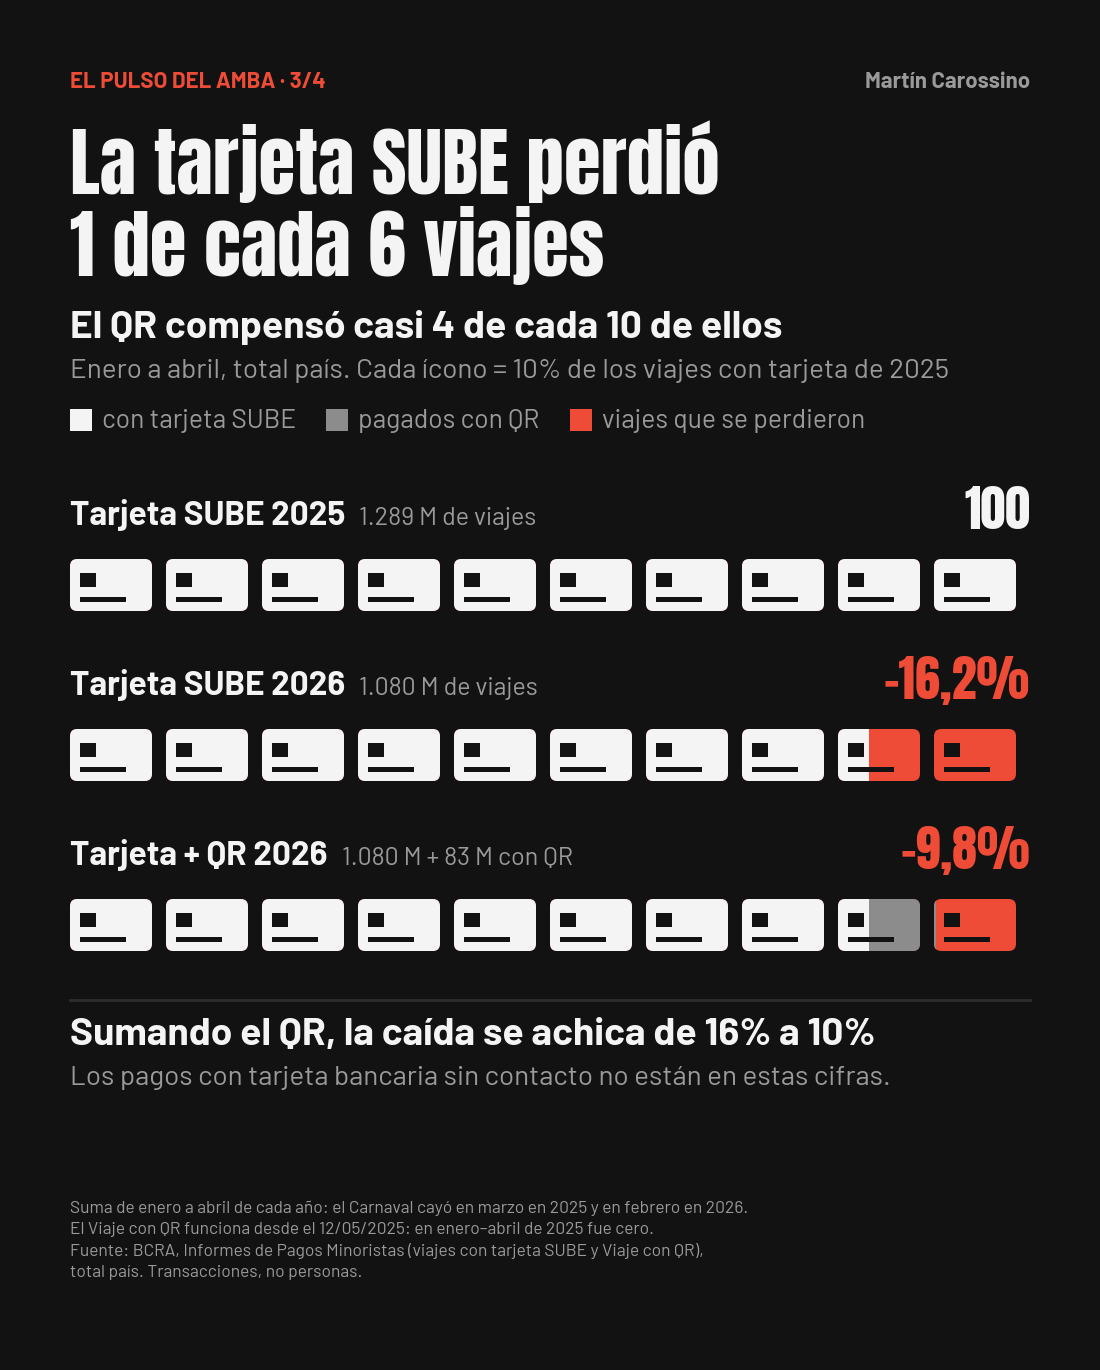

Guardado: post3_pagamos_distinto.png (1080 × 1350 px)


In [15]:
# El pulso del AMBA · Gráfico del post 3: ¿o pagamos distinto?
# Requiere haber ejecutado antes, en la misma sesión, la sección 10 (usa cuatrimestre e
# informe_slide_7) y la celda del gráfico del post 2 (reutiliza su paleta, sus tipografías
# y las funciones estilo, redondear y formato_porcentaje).

# =================================================================================================
# GRÁFICO DEL POST 3 · La tarjeta SUBE perdió 1 de cada 6 viajes; el QR compensó casi 4 de cada 10.
# =================================================================================================

# Mismo lenguaje visual que los posts 1 y 2: 10 íconos por fila, fondo oscuro, rojo = perdido.
# Cambia el ícono (una tarjeta: el post habla del MEDIO DE PAGO, no del vehículo) y aparece
# un tercer estado, el QR, en gris: así el rojo sigue significando solo "lo que se perdió".
# Cada ícono = 10% de los viajes con tarjeta de enero a abril de 2025. Formato 1080 × 1350 px.

# 0. Dependencias de celdas anteriores
# Se reutiliza lo que ya definió la celda del post 2 en vez de copiarlo: si la paleta o las
# tipografías cambian, cambian en un solo lugar y los tres gráficos siguen siendo una serie.
for nombre_necesario in ["cuatrimestre", "informe_slide_7", "estilo", "redondear", "formato_porcentaje",
                         "fuente_impacto", "fuente_texto", "fuente_negrita", "COLOR_FONDO", "COLOR_LLENO",
                         "COLOR_PERDIDO", "COLOR_TEXTO", "COLOR_TEXTO_SUAVE", "COLOR_SEPARADOR"]:
    if nombre_necesario not in globals():
        raise NameError(f"Falta '{nombre_necesario}': ejecutá antes la sección 10 y la celda del gráfico del post 2")


# 1. Datos: se toman de la sección 10, ya verificada
# No se recalcula nada contra el BCRA: el gráfico muestra EXACTAMENTE lo que controló la 10.4.
assert (informe_slide_7["estado"] == "OK").all(), "La slide 7 no está verificada: no se dibuja el gráfico"

tarjeta_2025 = float(cuatrimestre["tarjeta_2025_millones"])
tarjeta_2026 = float(cuatrimestre["tarjeta_2026_millones"])
qr_2026 = float(cuatrimestre["qr_2026_millones"])
variacion_tarjeta = float(cuatrimestre["variacion_tarjeta_pct"])
variacion_tarjeta_mas_qr = float(cuatrimestre["variacion_tarjeta_mas_qr_pct"])

# Todo se expresa en íconos: 10 íconos = la tarjeta de 2025 (la base, 100%)
iconos_tarjeta_2026 = tarjeta_2026 / tarjeta_2025 * 10   # 1.080,2 / 1.289,0 × 10 = 8,38
iconos_qr_2026 = qr_2026 / tarjeta_2025 * 10             # 82,5 / 1.289,0 × 10 = 0,64

# 2. Control: lo que se DIBUJA tiene que coincidir con lo que se ESCRIBE
# El post 2 controlaba cifras; acá además se controla que el dibujo cuente lo mismo que los
# números: si los íconos rojos no midieran 9,8% en la fila de tarjeta + QR, el gráfico
# contradiría a su propio titular sin que nadie lo notara a simple vista.
iconos_perdidos_solo_tarjeta = 10 - iconos_tarjeta_2026
iconos_perdidos_con_qr = 10 - iconos_tarjeta_2026 - iconos_qr_2026
controles_post_3 = [
    ("Rojo en la fila de tarjeta = caída de la tarjeta (%)", iconos_perdidos_solo_tarjeta * 10, -variacion_tarjeta),
    ("Rojo en la fila de tarjeta + QR = caída con QR (%)", iconos_perdidos_con_qr * 10, -variacion_tarjeta_mas_qr),
    ("Gris / rojo de la fila de tarjeta = parte en QR (%)", iconos_qr_2026 / iconos_perdidos_solo_tarjeta * 100,
     float(cuatrimestre["pct_perdida_que_aparece_en_qr"])),
    ("Titular '16%' = caída de la tarjeta redondeada", redondear(-variacion_tarjeta), 16),
    ("Conclusión '10%' = caída con QR redondeada", redondear(-variacion_tarjeta_mas_qr), 10),
]
print("VERIFICACIÓN DEL GRÁFICO DEL POST 3 (slide 7)")
for descripcion, dibujado, esperado in controles_post_3:
    coincide = abs(dibujado - esperado) <= 0.05
    print(f"  {'OK     ' if coincide else 'REVISAR'} {descripcion}: dibujado {dibujado:.2f}, esperado {esperado:.2f}")
cantidad_ok = sum(abs(dibujado - esperado) <= 0.05 for _, dibujado, esperado in controles_post_3)
print(f"\nVEREDICTO: {cantidad_ok} de {len(controles_post_3)} controles OK")
assert cantidad_ok == len(controles_post_3), "El dibujo no coincide con las cifras de la slide 7: no se guarda"


def formato_millones(valor):
    """1.289,0 → '1.289 M': punto de miles, como en la slide 7 (1.289 M / 1.080 M + 83 M QR)."""
    return f"{redondear(valor):,}".replace(",", ".") + " M"


# 3. Estética: la paleta del post 2 más un tercer estado
COLOR_QR = "#8C8C8C"   # gris medio: se distingue del blanco y del rojo sin competir con el acento


# 4. Ícono: una tarjeta
# Rectángulo redondeado con proporción de tarjeta (≈ 1,6 : 1), un chip y una banda de números.
# El chip y la banda van en color de fondo: son "agujeros" que la hacen reconocible.
ANCHO_ICONO, ALTO_ICONO, PASO = 82, 52, 96


def dibujar_tarjeta(eje, x, y, color, recorte=None):
    """Dibuja una tarjeta con su esquina inferior izquierda en (x, y).
    'recorte' es un rectángulo opcional: solo se ve la parte de la tarjeta que cae adentro."""
    cuerpo = FancyBboxPatch((x, y), ANCHO_ICONO, ALTO_ICONO,
                            boxstyle=f"round,pad=0,rounding_size={ALTO_ICONO * 0.14}",
                            linewidth=0, facecolor=color)
    eje.add_patch(cuerpo)
    if recorte is not None:
        cuerpo.set_clip_path(recorte)
    eje.add_patch(Rectangle((x + ANCHO_ICONO * 0.12, y + ALTO_ICONO * 0.46), ANCHO_ICONO * 0.20, ALTO_ICONO * 0.28,
                            facecolor=COLOR_FONDO, linewidth=0))    # chip
    eje.add_patch(Rectangle((x + ANCHO_ICONO * 0.12, y + ALTO_ICONO * 0.18), ANCHO_ICONO * 0.56, ALTO_ICONO * 0.08,
                            facecolor=COLOR_FONDO, linewidth=0))    # banda de números


def pintar_tramo(eje, y, inicio, fin, color):
    """Pinta de 'color' el tramo de la fila que va del ícono 'inicio' al ícono 'fin'
    (en unidades de ícono: 8,38 → 9,02 es el final del noveno ícono y el principio del décimo).
    Igual que en los posts 1 y 2, el recorte se mide sobre el ANCHO DEL ÍCONO, ícono por ícono,
    nunca sobre el paso entre íconos (el error que se corrigió en el post 1)."""
    for numero in range(10):
        desde = min(max(inicio - numero, 0), 1)
        hasta = min(max(fin - numero, 0), 1)
        if hasta > desde:
            x_icono = 60 + numero * PASO
            recorte = Rectangle((x_icono + ANCHO_ICONO * desde, y - 5), ANCHO_ICONO * (hasta - desde), ALTO_ICONO + 10,
                                transform=eje.transData)
            dibujar_tarjeta(eje, x_icono, y, color, recorte)


# Cada fila: (nombre, comentario, número de la derecha, color del número, tramos sobre el rojo).
# El fondo de cada fila es rojo (lo que había en 2025); encima se pintan los tramos que siguen.
filas_pictograma = [
    ("Tarjeta SUBE 2025", f"{formato_millones(tarjeta_2025)} de viajes", "100", COLOR_TEXTO,
     [(0, 10, COLOR_LLENO)]),
    ("Tarjeta SUBE 2026", f"{formato_millones(tarjeta_2026)} de viajes", formato_porcentaje(variacion_tarjeta),
     COLOR_PERDIDO, [(0, iconos_tarjeta_2026, COLOR_LLENO)]),
    ("Tarjeta + QR 2026", f"{formato_millones(tarjeta_2026)} + {formato_millones(qr_2026)} con QR",
     formato_porcentaje(variacion_tarjeta_mas_qr), COLOR_PERDIDO,
     [(0, iconos_tarjeta_2026, COLOR_LLENO), (iconos_tarjeta_2026, iconos_tarjeta_2026 + iconos_qr_2026, COLOR_QR)]),
]

# 5. Afiche
figura = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor=COLOR_FONDO)
eje = figura.add_axes([0, 0, 1, 1], facecolor=COLOR_FONDO)
eje.set_xlim(0, 1080)   # 1 unidad = 1 píxel
eje.set_ylim(0, 1350)
eje.axis("off")
dibujante = figura.canvas.get_renderer()


def borde_derecho(texto):
    """Dónde termina un texto, en píxeles (se mide sobre ESTA figura, no sobre la del post 2)."""
    return texto.get_window_extent(dibujante).x1


# Encabezado. El titular usa "1 de cada 6" (controlado en la 10.4) y el subtítulo el hallazgo.
# "Total país" va escrito: los posts 1 y 2 hablan del AMBA, y el BCRA informa todo el país.
eje.text(60, 1272, "EL PULSO DEL AMBA · 3/4", **estilo(fuente_negrita, 16, COLOR_PERDIDO))
eje.text(1020, 1272, "Martín Carossino", ha="right", **estilo(fuente_negrita, 16, COLOR_TEXTO_SUAVE))
eje.text(60, 1240, "La tarjeta SUBE perdió\n1 de cada 6 viajes", va="top", linespacing=1.05,
         **estilo(fuente_impacto, 54))
eje.text(60, 1022, "El QR compensó casi 4 de cada 10 de ellos", **estilo(fuente_negrita, 28))
eje.text(60, 982, "Enero a abril, total país. Cada ícono = 10% de los viajes con tarjeta de 2025",
         **estilo(fuente_texto, 20, COLOR_TEXTO_SUAVE))

# Leyenda: tres estados. Cada etiqueta se ubica donde termina la anterior (no a ojo).
x_leyenda = 60
for color, etiqueta in [(COLOR_LLENO, "con tarjeta SUBE"), (COLOR_QR, "pagados con QR"),
                        (COLOR_PERDIDO, "viajes que se perdieron")]:
    eje.add_patch(Rectangle((x_leyenda, 929), 22, 22, facecolor=color, linewidth=0))
    texto_leyenda = eje.text(x_leyenda + 32, 932, etiqueta, **estilo(fuente_texto, 19, COLOR_TEXTO_SUAVE))
    x_leyenda = borde_derecho(texto_leyenda) + 30

ALTURA_FILA, Y_PRIMERA_FILA = 170, 835
for indice, (nombre, comentario, numero_derecha, color_numero, tramos) in enumerate(filas_pictograma):
    y_fila = Y_PRIMERA_FILA - indice * ALTURA_FILA
    texto_nombre = eje.text(60, y_fila, nombre, va="baseline", **estilo(fuente_negrita, 24))
    eje.text(borde_derecho(texto_nombre) + 14, y_fila, comentario, va="baseline",
             **estilo(fuente_texto, 18, COLOR_TEXTO_SUAVE))
    eje.text(1020, y_fila - 4, numero_derecha, ha="right", va="baseline", **estilo(fuente_impacto, 36, color_numero))

    # Primero las diez tarjetas en rojo (todo lo que había en 2025); encima, los tramos que siguen.
    # Lo que no tapan el blanco ni el gris es lo que se perdió.
    y_iconos = y_fila - 24 - ALTO_ICONO - 10
    for numero in range(10):
        dibujar_tarjeta(eje, 60 + numero * PASO, y_iconos, COLOR_PERDIDO)
    for inicio, fin, color in tramos:
        pintar_tramo(eje, y_iconos, inicio, fin, color)

# Conclusión: lo que el lector se lleva, con las dos cifras redondeadas de la slide 7.
# La segunda línea es la limitación: el BCRA no informa los pagos con tarjeta bancaria.
eje.plot([60, 1020], [360, 360], color=COLOR_SEPARADOR, linewidth=2)
eje.text(60, 315, f"Sumando el QR, la caída se achica de {redondear(-variacion_tarjeta)}% "
                  f"a {redondear(-variacion_tarjeta_mas_qr)}%",
         **estilo(fuente_negrita, 28))
eje.text(60, 275, "Los pagos con tarjeta bancaria sin contacto no están en estas cifras.",
         **estilo(fuente_texto, 20, COLOR_TEXTO_SUAVE))

NOTA = ("Suma de enero a abril de cada año: el Carnaval cayó en marzo en 2025 y en febrero en 2026.\n"
        "El Viaje con QR funciona desde el 12/05/2025: en enero–abril de 2025 fue cero.\n"
        "Fuente: BCRA, Informes de Pagos Minoristas (viajes con tarjeta SUBE y Viaje con QR),\n"
        "total país. Transacciones, no personas.")
eje.text(60, 160, NOTA, va="top", linespacing=1.5, **estilo(fuente_texto, 12.5, COLOR_TEXTO_SUAVE))

figura.savefig("post3_pagamos_distinto.png", dpi=100, facecolor=COLOR_FONDO)
plt.show()
print("Guardado: post3_pagamos_distinto.png (1080 × 1350 px)")

## Prueba de sensibilidad · días sin causa confirmada
¿Las cifras publicadas dependen de los 22 días hábiles con caída sin causa confirmada? Se recalculan 25 cifras en tres escenarios.

In [16]:
# El pulso del AMBA · Prueba de sensibilidad: días hábiles con caída sin causa confirmada
# Requiere haber ejecutado antes, en la misma sesión, las secciones 00 a 09 y la verificación
# del post 1 (usa dias_atipicos, feriados_en_dia_habil, CTE_PANEL y variaciones_interanuales).

# ==============================================================
# ¿LOS DÍAS SIN CAUSA CONFIRMADA CAMBIAN ALGUNA CIFRA PUBLICADA?
# ==============================================================
# La sección 07 encontró 22 días hábiles que caen debajo del 80% de su referencia y no tienen
# un evento confirmado. Quedan como días hábiles: son viajes que de verdad se midieron.
# Esta prueba responde si alguna cifra publicada depende de ellos:
#   Escenario A: como se publicó (los 22 días quedan como hábiles).
#   Escenario B: sin los 7 días en que el colectivo cae mucho más que el subte.
#   Escenario C: sin los 22 días (el caso extremo: la mayoría son lluvias o vacaciones de invierno).
# Si una cifra no cambia en B ni en C, no depende de esos días.

for nombre_necesario in ["dias_atipicos", "feriados_en_dia_habil", "CTE_PANEL", "variaciones_interanuales",
                         "MESES_COMPARABLES"]:
    if nombre_necesario not in globals():
        raise NameError(f"Falta '{nombre_necesario}': ejecutá antes las secciones 00 a 09 y la verificación del post 1")

# Los 7 días con firma de paro de colectivos (bitácora, sección 3). Se escriben a mano a propósito:
# son una selección hecha mirando la firma por modo, no un umbral automático.
DIAS_FIRMA_PARO_COLECTIVOS = ["2024-03-12", "2024-03-20", "2025-02-05", "2025-05-16",
                              "2025-08-19", "2026-07-15", "2026-08-06"]
dias_sin_causa = pd.to_datetime(dias_atipicos["fecha"]).dt.date.tolist()
assert len(dias_sin_causa) == 22, f"Se esperaban 22 días sin causa confirmada y hay {len(dias_sin_causa)}"
assert set(pd.to_datetime(DIAS_FIRMA_PARO_COLECTIVOS).date) <= set(dias_sin_causa), "Los 7 días no están entre los 22"

ESCENARIOS = {
    "A_publicado":   [],
    "B_sin_7_dias":  pd.to_datetime(DIAS_FIRMA_PARO_COLECTIVOS).date.tolist(),
    "C_sin_22_dias": dias_sin_causa,
}

# feriados_en_dia_habil ya trae la categoría que usó la verificación del post 1
categoria_por_fecha = feriados_en_dia_habil[["fecha", "categoria"]].copy()
categoria_por_fecha["fecha"] = pd.to_datetime(categoria_por_fecha["fecha"]).dt.date
conexion.register("categoria_feriados", categoria_por_fecha)

FECHAS_PAROS = ["2024-05-09", "2026-02-19", "2024-04-11", "2025-05-06", "2025-04-10"]


def calcular_cifras(fechas_excluidas):
    """Recalcula las cifras de los posts 1 y 2 sacando 'fechas_excluidas' de los días hábiles.
    Toda la lógica está en SQL: la única diferencia con el análisis publicado es la CTE 'habiles'."""
    conexion.register("fechas_excluidas", pd.DataFrame({"fecha": pd.Series(fechas_excluidas, dtype="object")}))
    # CTE común: los días hábiles de referencia, sin las fechas excluidas.
    # CAST(... AS DATE): pandas registra las fechas como objeto; así la comparación es entre fechas.
    habiles = """
        habiles AS (
            SELECT * FROM vista_diaria_amba
            WHERE tipo_dia = 'HABIL'
              AND fecha NOT IN (SELECT CAST(fecha AS DATE) FROM fechas_excluidas)
        )
    """
    cifras = {}

    # Slide 2 · día hábil típico
    cifras["Día hábil típico (millones)"] = conexion.sql(
        f"WITH {habiles} SELECT MEDIAN(transacciones_total) / 1e6 FROM habiles").fetchone()[0]

    # Slide 3 · sábado y domingo frente a la mediana hábil del mismo mes
    perfil = conexion.sql(f"""
        WITH {habiles},
        base_mensual AS (SELECT anio, mes, MEDIAN(transacciones_total) AS mediana_habil_mes
                         FROM habiles GROUP BY anio, mes)
        SELECT d.nombre_dia, MEDIAN(d.transacciones_total / b.mediana_habil_mes * 100) AS indice
        FROM vista_diaria_amba AS d JOIN base_mensual AS b USING (anio, mes)
        WHERE d.tipo_dia = 'FIN_DE_SEMANA'
        GROUP BY d.nombre_dia
    """).df().set_index("nombre_dia")["indice"]
    cifras["Índice sábado"] = perfil["sábado"]
    cifras["Índice domingo"] = perfil["domingo"]

    # Slides 4 y 5 · feriados y paros frente a los hábiles del mismo día de la semana, ±35 días
    # (la misma referencia que vista_dia_vs_habil_tipico, pero sin las fechas excluidas)
    contra_referencia = conexion.sql(f"""
        WITH {habiles},
        dias_a_medir AS (
            SELECT d.fecha, d.dia_semana, d.transacciones_total, c.categoria
            FROM vista_diaria_amba AS d
            LEFT JOIN categoria_feriados AS c ON c.fecha = d.fecha
            WHERE c.categoria IS NOT NULL
               OR d.fecha IN ({", ".join(f"DATE '{fecha}'" for fecha in FECHAS_PAROS)})
        )
        SELECT m.fecha, m.categoria,
               m.transacciones_total / MEDIAN(r.transacciones_total) * 100 AS pct_total
        FROM dias_a_medir AS m
        JOIN habiles AS r
          ON  r.dia_semana = m.dia_semana
          AND r.fecha <> m.fecha
          AND r.fecha BETWEEN m.fecha - INTERVAL 35 DAY AND m.fecha + INTERVAL 35 DAY
        GROUP BY m.fecha, m.categoria, m.transacciones_total
    """).df()
    contra_referencia["fecha"] = contra_referencia["fecha"].astype(str)
    por_categoria = contra_referencia.dropna(subset=["categoria"]).groupby("categoria")["pct_total"]
    for categoria in ["Puente turístico no laborable", "Feriado nacional", "Navidad y Año Nuevo"]:
        cifras[f"{categoria}: mínimo (%)"] = por_categoria.min()[categoria]
        cifras[f"{categoria}: máximo (%)"] = por_categoria.max()[categoria]
    cifras["Feriado nacional: mediana (%)"] = por_categoria.median()["Feriado nacional"]
    cifras["1 de mayo: promedio (%)"] = por_categoria.mean()["1 de mayo"]
    paros = contra_referencia.set_index("fecha")["pct_total"]
    for fecha in FECHAS_PAROS:
        cifras[f"Paro {fecha} (%)"] = paros[fecha]
    cifras["Paro de colectivos: mediana (%)"] = (paros["2024-04-11"] + paros["2025-05-06"]) / 2
    cifras["Paro general: mediana (%)"] = (paros["2024-05-09"] + paros["2026-02-19"]) / 2

    # Slide 6 · variación interanual: misma consulta que la sección 09, con los hábiles filtrados
    mensual = conexion.sql(f"""
        WITH {CTE_PANEL}, {habiles},
        total_diario_panel AS (
            SELECT l.fecha, SUM(l.cantidad_analisis) AS total_panel
            FROM lineas_amba AS l JOIN lineas_panel USING (clave_linea)
            GROUP BY l.fecha
        )
        SELECT h.anio, h.mes,
               MEDIAN(p.total_panel)             AS panel,
               MEDIAN(h.transacciones_total)     AS total,
               MEDIAN(h.transacciones_colectivo) AS colectivo,
               MEDIAN(h.transacciones_tren)      AS tren,
               MEDIAN(h.transacciones_subte)     AS subte
        FROM habiles AS h JOIN total_diario_panel AS p ON p.fecha = h.fecha
        GROUP BY h.anio, h.mes
    """).df()
    for serie in ["total", "colectivo", "tren", "subte", "panel"]:
        variaciones = variaciones_interanuales(mensual, serie, 2026)
        cifras[f"Variación 2026 {serie} (%)"] = variaciones.mean()
        if serie == "total":
            cifras["Peor mes 2026, total (%)"] = variaciones.min()
            cifras["Mejor mes 2026, total (%)"] = variaciones.max()
    return cifras


# Valor publicado y tolerancia: la misma regla que la verificación del post 1.
# Las cifras que el post 2 publica con un decimal (−11,9, −13,4…) tienen tolerancia 0,05.
CIFRAS_PUBLICADAS = {
    "Día hábil típico (millones)": (10.5, 0.05),
    "Índice sábado": (60, 0.5), "Índice domingo": (31, 0.5),
    "Puente turístico no laborable: mínimo (%)": (46, 0.5), "Puente turístico no laborable: máximo (%)": (63, 0.5),
    "Feriado nacional: mínimo (%)": (27, 0.5), "Feriado nacional: máximo (%)": (42, 0.5),
    "Feriado nacional: mediana (%)": (35, 0.5),
    "Navidad y Año Nuevo: mínimo (%)": (14, 0.5), "Navidad y Año Nuevo: máximo (%)": (19, 0.5),
    "1 de mayo: promedio (%)": (25, 1),
    "Paro 2024-05-09 (%)": (5, 0.5), "Paro 2026-02-19 (%)": (8, 0.5), "Paro 2024-04-11 (%)": (33, 0.5),
    "Paro 2025-05-06 (%)": (27, 0.5), "Paro 2025-04-10 (%)": (53, 0.5),
    "Paro de colectivos: mediana (%)": (30, 0.5), "Paro general: mediana (%)": (6, 0.5),
    "Variación 2026 total (%)": (-11.8, 0.05), "Variación 2026 colectivo (%)": (-11.9, 0.05),
    "Variación 2026 tren (%)": (-13.4, 0.05), "Variación 2026 subte (%)": (-10.7, 0.05),
    "Variación 2026 panel (%)": (-10.9, 0.05),
    "Peor mes 2026, total (%)": (-20, 0.5), "Mejor mes 2026, total (%)": (-8.5, 0.05),
}

resultados = {nombre: calcular_cifras(fechas) for nombre, fechas in ESCENARIOS.items()}
filas_sensibilidad = []
for cifra, (publicado, tolerancia) in CIFRAS_PUBLICADAS.items():
    fila = {"cifra": cifra, "publicado": publicado}
    for nombre in ESCENARIOS:
        fila[nombre] = round(float(resultados[nombre][cifra]), 2)
    # El escenario A TIENE que coincidir con lo publicado: si no, la prueba está mal armada
    fila["A_coincide"] = abs(fila["A_publicado"] - publicado) <= tolerancia
    fila["B_mantiene"] = abs(fila["B_sin_7_dias"] - publicado) <= tolerancia
    fila["C_mantiene"] = abs(fila["C_sin_22_dias"] - publicado) <= tolerancia
    filas_sensibilidad.append(fila)
sensibilidad = pd.DataFrame(filas_sensibilidad)

print("=" * 110 + "\nSENSIBILIDAD DE LAS CIFRAS PUBLICADAS A LOS DÍAS SIN CAUSA CONFIRMADA\n" + "=" * 110)
print(sensibilidad.to_string(index=False))
assert sensibilidad["A_coincide"].all(), "El escenario A no reproduce lo publicado: revisar la prueba antes de leerla"
print(f"\nEscenario A reproduce lo publicado: {int(sensibilidad['A_coincide'].sum())} de {len(sensibilidad)}")
print(f"Sin los 7 días con firma de paro, se mantienen: {int(sensibilidad['B_mantiene'].sum())} de {len(sensibilidad)}")
print(f"Sin los 22 días, se mantienen:                  {int(sensibilidad['C_mantiene'].sum())} de {len(sensibilidad)}")
cambian = sensibilidad[~(sensibilidad["B_mantiene"] & sensibilidad["C_mantiene"])]
if len(cambian):
    print("\nCifras que cambian en algún escenario:")
    print(cambian[["cifra", "publicado", "A_publicado", "B_sin_7_dias", "C_sin_22_dias"]].to_string(index=False))

SENSIBILIDAD DE LAS CIFRAS PUBLICADAS A LOS DÍAS SIN CAUSA CONFIRMADA
                                    cifra  publicado  A_publicado  B_sin_7_dias  C_sin_22_dias  A_coincide  B_mantiene  C_mantiene
              Día hábil típico (millones)       10.5        10.50         10.54          10.59        True        True       False
                            Índice sábado       60.0        60.10         59.98          59.86        True        True        True
                           Índice domingo       31.0        31.10         31.10          31.01        True        True        True
Puente turístico no laborable: mínimo (%)       46.0        45.76         45.76          45.68        True        True        True
Puente turístico no laborable: máximo (%)       63.0        62.64         62.64          62.14        True        True       False
             Feriado nacional: mínimo (%)       27.0        27.33         27.33          27.33        True        True        True
             

## 11 · Eje 4: fusiones de líneas
¿Cuánta demanda conservó la línea receptora? Una sola consulta SQL, con controles de entrada y dos variantes de sensibilidad.

In [17]:
# El pulso del AMBA · Sección 11: eje 4 · fusiones de líneas
# Requiere haber ejecutado antes las secciones 00 a 05 en la misma sesión
# (usa la conexión, la vista consolidada, feriados_oficiales e incidencias_calidad).

# ===============================================================================
# 11. EJE 4 · FUSIONES DE LÍNEAS: ¿cuántos pasajeros absorbió la línea receptora?
# ===============================================================================

# Método (bitácora, sección 5): demanda de la receptora en las 4 semanas posteriores
# frente a la suma de ambas líneas en las 4 semanas previas, corregida por cuánto
# cambió el resto del sistema en el mismo período (factor estacional).
# Fuentes de las fusiones: canal26.com (05/02/2026) y Resolución 18/2026 (Transporte CABA).
DIAS_VENTANA = 28             # cuatro semanas antes y cuatro después del último día de servicio
MINIMO_DIAS_HABILES = 15      # con menos días hábiles normales, el promedio de una ventana es frágil
UMBRAL_PESO_MEDIBLE_PCT = 5   # si la línea eliminada pesa menos que esto frente a la receptora,
                              # su aporte se pierde en el ruido diario: la absorción no es medible

# Valores publicados en la slide 8. Se fijan a mano a propósito: son el punto de comparación,
# no un resultado.
ABSORCION_PUBLICADA_SLIDE_8 = {99: 106, 23: 93, 6: 84, 90: 107}

tabla_fusiones = conexion.sql(f"""
    -- 1. Fusiones informadas. La 75 se eliminó sin línea receptora (destino NULL).
    WITH fusiones_informadas AS (
        SELECT * FROM (VALUES (5, 8), (6, 50), (23, 115), (75, NULL), (90, 151), (99, 106))
            AS f(linea_origen, linea_destino)
    ),
    -- 2. Todas las líneas que participan de alguna fusión: el control "limpio" las excluye,
    --    porque cambian de tamaño por motivos que no son estacionales.
    lineas_en_fusiones AS (
        SELECT linea_origen AS numero_linea FROM fusiones_informadas
        UNION
        SELECT linea_destino FROM fusiones_informadas WHERE linea_destino IS NOT NULL
    ),
    -- 3. Un registro por día y línea, solo días hábiles normales (sin eventos ni feriados).
    --    CAST a DOUBLE: la suma de enteros da HUGEINT, y acá solo vamos a dividir.
    dias_habiles_normales AS (
        SELECT v.fecha,
               v.numero_linea,
               CAST(SUM(v.cantidad_analisis) AS DOUBLE) AS transacciones
        FROM vista_transacciones_consolidadas AS v
        WHERE v.numero_linea IS NOT NULL
          AND v.dia_semana <= 5
          AND v.tipo_evento IS NULL
          AND v.fecha NOT IN (SELECT fecha FROM feriados_oficiales)
        GROUP BY v.fecha, v.numero_linea
    ),
    dias_con_marca AS (
        SELECT d.fecha, d.numero_linea, d.transacciones,
               l.numero_linea IS NOT NULL AS es_linea_de_fusion
        FROM dias_habiles_normales AS d
        LEFT JOIN lineas_en_fusiones AS l ON l.numero_linea = d.numero_linea
    ),
    -- 4. El último día de cada línea eliminada sale de los datos, no se escribe a mano.
    --    Se busca en todos los días (puede ser un fin de semana). LEFT JOIN: la línea 5
    --    no aparece en el período y tiene que figurar igual, con NULL.
    ultimo_dia AS (
        SELECT f.linea_origen, f.linea_destino, MAX(v.fecha) AS ultimo_dia_origen
        FROM fusiones_informadas AS f
        LEFT JOIN vista_transacciones_consolidadas AS v ON v.numero_linea = f.linea_origen
        GROUP BY f.linea_origen, f.linea_destino
    ),
    -- 5. Serie diaria de cada fusión dentro de su ventana. Se excluye el último día:
    --    es una jornada de transición (la 99 hizo 3.245 transacciones ese día).
    serie_por_fusion AS (
        SELECT u.linea_origen,
               d.fecha,
               CASE WHEN d.fecha < u.ultimo_dia_origen THEN 'antes' ELSE 'despues' END AS periodo,
               SUM(d.transacciones) FILTER (WHERE d.numero_linea = u.linea_origen)  AS origen,
               SUM(d.transacciones) FILTER (WHERE d.numero_linea = u.linea_destino) AS destino,
               -- Control del método publicado: todas las demás líneas nacionales y porteñas
               SUM(d.transacciones) FILTER (WHERE d.numero_linea NOT IN (u.linea_origen, u.linea_destino)) AS control,
               -- Control "limpio" (sensibilidad): sin ninguna línea que participe de una fusión
               SUM(d.transacciones) FILTER (WHERE NOT d.es_linea_de_fusion) AS control_limpio
        FROM ultimo_dia AS u
        JOIN dias_con_marca AS d
          ON  d.fecha BETWEEN u.ultimo_dia_origen - INTERVAL {DIAS_VENTANA} DAY
                          AND u.ultimo_dia_origen + INTERVAL {DIAS_VENTANA} DAY
          AND d.fecha <> u.ultimo_dia_origen
        GROUP BY u.linea_origen, d.fecha, periodo
    ),
    -- 6. Promedio por ventana (método publicado) y mediana (sensibilidad: resiste días
    --    con caída sin causa, como el 16/05/2025 dentro de la ventana de la 6 → 50).
    resumen_por_fusion AS (
        SELECT linea_origen,
               COUNT(*) FILTER (WHERE periodo = 'antes')                  AS dias_habiles_antes,
               COUNT(*) FILTER (WHERE periodo = 'despues')                AS dias_habiles_despues,
               AVG(origen)         FILTER (WHERE periodo = 'antes')       AS origen_antes,
               AVG(destino)        FILTER (WHERE periodo = 'antes')       AS destino_antes,
               AVG(destino)        FILTER (WHERE periodo = 'despues')     AS destino_despues,
               AVG(control)        FILTER (WHERE periodo = 'antes')       AS control_antes,
               AVG(control)        FILTER (WHERE periodo = 'despues')     AS control_despues,
               AVG(control_limpio) FILTER (WHERE periodo = 'antes')       AS control_limpio_antes,
               AVG(control_limpio) FILTER (WHERE periodo = 'despues')     AS control_limpio_despues,
               MEDIAN(origen)      FILTER (WHERE periodo = 'antes')       AS mediana_origen_antes,
               MEDIAN(destino)     FILTER (WHERE periodo = 'antes')       AS mediana_destino_antes,
               MEDIAN(destino)     FILTER (WHERE periodo = 'despues')     AS mediana_destino_despues,
               MEDIAN(control)     FILTER (WHERE periodo = 'antes')       AS mediana_control_antes,
               MEDIAN(control)     FILTER (WHERE periodo = 'despues')     AS mediana_control_despues
        FROM serie_por_fusion
        GROUP BY linea_origen
    )
    -- 7. Absorción: lo que la receptora tiene después, frente a lo que ambas líneas tenían
    --    antes, multiplicado por cuánto cambió el resto del sistema (factor estacional).
    SELECT u.linea_origen,
           u.linea_destino,
           u.ultimo_dia_origen,
           fin.hasta                                                   AS fin_documentado,
           r.dias_habiles_antes,
           r.dias_habiles_despues,
           ROUND(r.origen_antes)                                       AS origen_antes,
           ROUND(r.destino_antes)                                      AS destino_antes,
           ROUND(r.destino_despues)                                    AS destino_despues,
           ROUND(r.origen_antes / r.destino_antes * 100, 1)            AS peso_origen_pct,
           ROUND(r.control_despues / r.control_antes, 3)               AS factor_estacional,
           ROUND(r.destino_despues / (r.origen_antes + r.destino_antes) * 100, 1)
                                                                       AS pct_absorcion_bruto,
           ROUND(r.destino_despues
                 / ((r.origen_antes + r.destino_antes) * r.control_despues / r.control_antes) * 100, 1)
                                                                       AS pct_absorcion_ajustado,
           ROUND(r.mediana_destino_despues
                 / ((r.mediana_origen_antes + r.mediana_destino_antes)
                    * r.mediana_control_despues / r.mediana_control_antes) * 100, 1)
                                                                       AS sens_con_medianas,
           ROUND(r.destino_despues
                 / ((r.origen_antes + r.destino_antes)
                    * r.control_limpio_despues / r.control_limpio_antes) * 100, 1)
                                                                       AS sens_control_limpio
    FROM ultimo_dia AS u
    LEFT JOIN resumen_por_fusion AS r USING (linea_origen)
    LEFT JOIN incidencias_calidad AS fin
           ON fin.numero_linea = u.linea_origen AND fin.tipo_incidencia = 'FIN_DE_SERVICIO'
    ORDER BY u.ultimo_dia_origen NULLS LAST
""").df()

tabla_fusiones["linea_destino"] = tabla_fusiones["linea_destino"].astype("Int64")
print("FUSIONES DE LÍNEAS (promedio por día hábil normal, ventanas de 4 semanas)")
print(tabla_fusiones.to_string(index=False))
tabla_fusiones.to_csv("fusiones_absorcion.csv", index=False, encoding="utf-8")


# 11.1 Controles: ¿los datos de entrada son los que creemos?
controles_fusiones = []


def registrar_control_fusion(control, valor, estado):
    """Agrega una fila al informe de controles de la sección 11."""
    controles_fusiones.append({"control": control, "valor": valor, "estado": estado})


for fila in tabla_fusiones.itertuples():
    if pd.isna(fila.ultimo_dia_origen):
        # La línea 5 no aparece en el período (bitácora, sección 5): es lo esperado
        registrar_control_fusion(f"Línea {fila.linea_origen}: sin datos en el período", "sin datos",
                                 "OK" if fila.linea_origen == 5 else "REVISAR")
        continue

    # (a) El último día calculado debe coincidir con el documentado a mano en el modelo
    ultimo_dia_calculado = pd.Timestamp(fila.ultimo_dia_origen)
    coincide_con_modelo = ultimo_dia_calculado == pd.Timestamp(fila.fin_documentado)
    registrar_control_fusion(f"Línea {fila.linea_origen}: último día = incidencia FIN_DE_SERVICIO",
                             str(ultimo_dia_calculado.date()), "OK" if coincide_con_modelo else "FALLA")

    if pd.isna(fila.linea_destino):
        continue   # la 75 no tiene receptora: no hay absorción que medir

    # (b) Cada ventana necesita suficientes días hábiles para que el promedio sea estable.
    # Si una ventana queda corta, se averigua por qué: cuántos días hábiles del calendario se
    # excluyeron por un evento verificado o un feriado. Una ventana corta se acepta solo si
    # (1) todo lo que falta está explicado por esas exclusiones y (2) con medianas, que resisten
    # días raros, el resultado no se mueve más de 1 punto.
    dias_en_la_ventana_mas_corta = min(fila.dias_habiles_antes, fila.dias_habiles_despues)
    dias_calendario_antes, excluidos_antes, dias_calendario_despues, excluidos_despues = conexion.sql(f"""
        SELECT COUNT(*) FILTER (WHERE f.fecha < DATE '{ultimo_dia_calculado.date()}'),
               COUNT(*) FILTER (WHERE f.fecha < DATE '{ultimo_dia_calculado.date()}' AND (
                   f.fecha IN (SELECT fecha FROM eventos_verificados)
                   OR f.fecha IN (SELECT fecha FROM feriados_oficiales))),
               COUNT(*) FILTER (WHERE f.fecha > DATE '{ultimo_dia_calculado.date()}'),
               COUNT(*) FILTER (WHERE f.fecha > DATE '{ultimo_dia_calculado.date()}' AND (
                   f.fecha IN (SELECT fecha FROM eventos_verificados)
                   OR f.fecha IN (SELECT fecha FROM feriados_oficiales)))
        FROM dim_fecha AS f
        WHERE f.dia_semana <= 5
          AND f.fecha BETWEEN DATE '{ultimo_dia_calculado.date()}' - INTERVAL {DIAS_VENTANA} DAY
                          AND DATE '{ultimo_dia_calculado.date()}' + INTERVAL {DIAS_VENTANA} DAY
          AND f.fecha <> DATE '{ultimo_dia_calculado.date()}'
    """).fetchone()
    faltantes_explicados = (fila.dias_habiles_antes + excluidos_antes == dias_calendario_antes
                            and fila.dias_habiles_despues + excluidos_despues == dias_calendario_despues)
    diferencia_con_medianas = abs(fila.sens_con_medianas - fila.pct_absorcion_ajustado)
    if dias_en_la_ventana_mas_corta >= MINIMO_DIAS_HABILES:
        estado_ventana = "OK"
    elif faltantes_explicados and diferencia_con_medianas <= 1:
        estado_ventana = "OK: corta por días excluidos verificados; con medianas, mismo resultado"
    else:
        estado_ventana = "REVISAR"
    registrar_control_fusion(
        f"{fila.linea_origen} → {fila.linea_destino}: días hábiles por ventana (mínimo)",
        f"{int(dias_en_la_ventana_mas_corta)} (excluidos: {excluidos_antes} antes, {excluidos_despues} después; "
        f"medianas a {diferencia_con_medianas:.1f} puntos)",
        estado_ventana)

    # (c) ¿La línea eliminada pesa lo suficiente como para que su absorción se distinga del ruido?
    es_medible = fila.peso_origen_pct >= UMBRAL_PESO_MEDIBLE_PCT
    registrar_control_fusion(f"{fila.linea_origen} → {fila.linea_destino}: peso de la línea eliminada",
                             f"{fila.peso_origen_pct:.1f}%", "INFO: medible" if es_medible else "INFO: no medible")

print("\nCONTROLES DE ENTRADA DE LA SECCIÓN 11")
print(pd.DataFrame(controles_fusiones).to_string(index=False))


# 11.2 Slide 8: valores publicados frente a los recalculados
def redondear_a_entero(valor):
    """Redondeo 'del colegio' (85,5 → 86). round() de Python redondea al par: 86,5 → 86."""
    return int(valor + 0.5)


filas_slide_8 = []
for linea_origen, valor_publicado in ABSORCION_PUBLICADA_SLIDE_8.items():
    fila = tabla_fusiones.loc[tabla_fusiones["linea_origen"] == linea_origen].iloc[0]
    valor_recalculado = fila["pct_absorcion_ajustado"]
    variantes = [valor_recalculado, fila["sens_con_medianas"], fila["sens_control_limpio"]]
    filas_slide_8.append({
        "fusion": f"{linea_origen} → {fila['linea_destino']}",
        "publicado": valor_publicado,
        "recalculado": valor_recalculado,
        "para_publicar": redondear_a_entero(valor_recalculado),
        "estado": "OK" if redondear_a_entero(valor_recalculado) == valor_publicado else "REVISAR",
        "rango_sensibilidad": f"{min(variantes):.1f} a {max(variantes):.1f}",
    })
print("\nSLIDE 8: ABSORCIÓN AJUSTADA (valor publicado) Y RANGO DE LAS VARIANTES")
print(pd.DataFrame(filas_slide_8).to_string(index=False))

# La frase publicada "con la 6, alrededor de 1 de cada 6 viajes no reapareció en la 50"
# depende del valor de la 6 → 50: se controla que siga siendo verdadera.
absorcion_6_a_50 = tabla_fusiones.loc[tabla_fusiones["linea_origen"] == 6, "pct_absorcion_ajustado"].iloc[0]
pct_que_no_reaparecio = 100 - absorcion_6_a_50
uno_de_cada = 100 / pct_que_no_reaparecio if pct_que_no_reaparecio > 0 else float("inf")
estado_frase = "OK" if redondear_a_entero(uno_de_cada) == 6 else "REVISAR"
registrar_control_fusion("Frase '1 de cada 6 viajes no reapareció en la 50'",
                         f"no reapareció el {pct_que_no_reaparecio:.1f}% → 1 de cada {uno_de_cada:.1f}", estado_frase)
print(f"\nFrase de la 6 → 50: no reapareció el {pct_que_no_reaparecio:.1f}% → 1 de cada {uno_de_cada:.1f} → {estado_frase}")

estados_finales = pd.concat([pd.DataFrame(controles_fusiones)["estado"], pd.DataFrame(filas_slide_8)["estado"]])
cantidad_problemas = int(estados_finales.isin(["FALLA", "REVISAR"]).sum())
print("\nVEREDICTO:", "sección 11 verificada ✔ (controles de entrada, slide 8 y frase)" if cantidad_problemas == 0
      else f"{cantidad_problemas} control(es) con FALLA o REVISAR: revisar antes de publicar la slide 8")

FUSIONES DE LÍNEAS (promedio por día hábil normal, ventanas de 4 semanas)
 linea_origen  linea_destino ultimo_dia_origen fin_documentado  dias_habiles_antes  dias_habiles_despues  origen_antes  destino_antes  destino_despues  peso_origen_pct  factor_estacional  pct_absorcion_bruto  pct_absorcion_ajustado  sens_con_medianas  sens_control_limpio
            6             50        2025-05-07      2025-05-07                  14                    20       13595.0        25029.0          30956.0             54.3              0.952                 80.1                    84.2               83.6                 84.2
           90            151        2025-09-16      2025-09-16                  20                    19         481.0        34382.0          38313.0              1.4              1.024                109.9                   107.3              109.1                107.2
           23            115        2025-11-12      2025-11-12                  20                    17      

## 12 · Verificación final del carrusel
Cada cifra publicada, recalculada contra su valor publicado. Esperado: 66 de 66.

In [18]:
# El pulso del AMBA · Sección 12: verificación final del carrusel
# Requiere haber ejecutado antes las secciones 00 a 11 en la misma sesión.

# ========================================================================
# 12. VERIFICACIÓN FINAL: cada cifra publicada en el carrusel, recalculada
# ========================================================================

# OK = el valor calculado coincide con el publicado dentro de la tolerancia del redondeo.
# REVISAR = hay que corregir la slide antes de publicar.
# Al terminar esta sección con todo en OK, las cifras quedan CONGELADAS.
cifras_carrusel = []

def verificar_cifra(slide, descripcion, calculado, publicado, tolerancia):
    """Compara una cifra recalculada con la publicada.
    La tolerancia es la del redondeo: si la slide dice 84%, vale cualquier valor entre 83,5 y 84,5."""
    cifras_carrusel.append({
        "slide": slide, "cifra": descripcion, "calculado": round(float(calculado), 2),
        "publicado": publicado,
        "estado": "OK" if abs(float(calculado) - publicado) <= tolerancia else "REVISAR",
    })

def verificar_condicion(slide, descripcion, calculado, condicion_cumplida, texto_publicado):
    """Para afirmaciones en palabras ('menos de una quinta parte', '1 de cada 6'):
    no se compara un número, se comprueba que la frase sea verdadera con el valor calculado."""
    cifras_carrusel.append({"slide": slide, "cifra": descripcion, "calculado": round(float(calculado), 2),
                            "publicado": texto_publicado, "estado": "OK" if condicion_cumplida else "REVISAR"})

# Slide 1 · Portada
verificar_cifra(1, "Registros analizados (millones)", len(df_sube) / 1e6, 1.5, 0.05)
verificar_cifra(1, "Tarjeta SUBE ene–abr 2026 vs 2025 (%)", cuatrimestre["variacion_tarjeta_pct"], -16, 0.5)
caida_tarjeta = abs(float(cuatrimestre["variacion_tarjeta_pct"]))
verificar_condicion(1, "Frase '1 de cada 6 viajes' (100 / caída)", 100 / caida_tarjeta,
                    round(100 / caida_tarjeta) == 6, "1 de cada 6")

# Slide 2 · Un día hábil
verificar_cifra(2, "Día hábil típico (millones)", mediana_dia_habil / 1e6, 10.5, 0.05)
verificar_cifra(2, "Participación colectivo (%)", participacion_modos["colectivo"][0], 84, 0.5)
verificar_cifra(2, "Participación tren (%)", participacion_modos["tren"][0], 10, 0.5)
verificar_cifra(2, "Participación subte (%)", participacion_modos["subte"][0], 5.5, 0.05)

# Slide 3 · Perfil semanal
for dia, publicado in zip(perfil_indice["nombre_dia"], [98, 100, 100, 101, 101, 60, 31]):
    verificar_cifra(3, f"Índice {dia}", perfil_indice.loc[perfil_indice["nombre_dia"] == dia, "mediana"].iloc[0],
                    publicado, 0.5)


# Slide 4 · Días libres
def categoria_feriado(fila):
    """Agrupa los feriados como los presenta la slide 4. El orden importa: un puente de 2025
    se llama 'Puente turístico no laborable' y tiene que caer en la primera categoría."""
    nombre = fila["nombre_feriado"].lower()
    if "no laborable" in nombre:
        return "Puente turístico no laborable"
    if "año nuevo" in nombre or "navidad" in nombre:
        return "Navidad y Año Nuevo"
    if "trabajador" in nombre:
        return "1 de mayo"
    if "puente" in fila["tipo_feriado"]:
        return "Feriado puente 2024 (no publicado)"
    return "Feriado nacional"


feriados_en_dia_habil["categoria"] = feriados_en_dia_habil.apply(categoria_feriado, axis=1)
rangos_feriados = feriados_en_dia_habil.groupby("categoria")["pct_total"].agg(["min", "max", "mean", "count"])
print("Rangos por categoría de feriado (%):")
print(rangos_feriados.round(1).to_string())
for categoria, (minimo, maximo) in {"Puente turístico no laborable": (46, 63), "Feriado nacional": (27, 42),
                                    "Navidad y Año Nuevo": (14, 19)}.items():
    verificar_cifra(4, f"{categoria}: mínimo (%)", rangos_feriados.loc[categoria, "min"], minimo, 0.5)
    verificar_cifra(4, f"{categoria}: máximo (%)", rangos_feriados.loc[categoria, "max"], maximo, 0.5)
verificar_cifra(4, "1 de mayo: promedio (%)", rangos_feriados.loc["1 de mayo", "mean"], 25, 1)
verificar_cifra(4, "Feriados en día hábil hasta el corte", len(feriados_en_dia_habil), 44, 0)

# Slide 5 · Paros (AMBA, frente a días hábiles del mismo día de la semana, ±35 días)
paros = conexion.sql("""
    SELECT fecha, pct_total, pct_colectivo, pct_tren, pct_subte
    FROM vista_dia_vs_habil_tipico
    WHERE fecha IN ('2024-05-09', '2026-02-19', '2024-04-11', '2025-05-06', '2025-04-10')
""").df().set_index("fecha")
paros.index = paros.index.astype(str)
print("\nParos recalculados (AMBA):")
print(paros.to_string())
# Valores publicados: AMBA, frente a días hábiles del mismo día de la semana ±35 días
for fecha, publicado in {"2024-05-09": 5, "2026-02-19": 8, "2024-04-11": 33,
                         "2025-05-06": 27, "2025-04-10": 53}.items():
    verificar_cifra(5, f"Paro {fecha}: total (%)", paros.loc[fecha, "pct_total"], publicado, 0.5)
# "Colectivo a una quinta parte": se exige que el valor esté claramente cerca de 20%
# (entre 18 y 22), no en el borde de un redondeo.
verificar_condicion(5, "Paro 2024-04-11: colectivo a una quinta parte (18–22%)",
                    paros.loc["2024-04-11", "pct_colectivo"],
                    18 <= paros.loc["2024-04-11", "pct_colectivo"] <= 22, "una quinta parte")
verificar_condicion(5, "Paro 2024-04-11: subte normal (≥ 90%)", paros.loc["2024-04-11", "pct_subte"],
                    paros.loc["2024-04-11", "pct_subte"] >= 90, "subte normal")
verificar_condicion(5, "Paro 2025-04-10: trenes y subte en 0%",
                    paros.loc["2025-04-10", ["pct_tren", "pct_subte"]].max(),
                    paros.loc["2025-04-10", ["pct_tren", "pct_subte"]].max() < 1, "0%")
# Frase de cierre: "entre un cuarto y un tercio" (paros de colectivos) y "menos de una décima parte" (generales)
paros_de_colectivos = paros.loc[["2024-04-11", "2025-05-06"], "pct_total"]
paros_generales = paros.loc[["2024-05-09", "2026-02-19"], "pct_total"]
verificar_condicion(5, "Paros de colectivos: entre 25% y 33,3%", paros_de_colectivos.min(),
                    paros_de_colectivos.min() >= 25 and paros_de_colectivos.max() <= 100 / 3,
                    "entre un cuarto y un tercio")
verificar_condicion(5, "Paros generales: menos del 10%", paros_generales.max(),
                    paros_generales.max() < 10, "menos de una décima parte")

# Slide 6 · ¿Viajamos menos?
verificar_cifra(6, "Total AMBA 2026 vs 2025 (%)", tabla_interanual.loc["total", "var_2026_vs_2025"], -12, 0.5)
verificar_cifra(6, "Colectivo (%)", tabla_interanual.loc["colectivo", "var_2026_vs_2025"], -11.9, 0.05)
verificar_cifra(6, "Tren (%)", tabla_interanual.loc["tren", "var_2026_vs_2025"], -13.4, 0.05)
verificar_cifra(6, "Subte (%)", tabla_interanual.loc["subte", "var_2026_vs_2025"], -10.7, 0.05)
verificar_cifra(6, "Peor mes 2026 (%)", tabla_interanual.loc["total", "peor_mes_2026"], -20, 0.5)
verificar_cifra(6, "Mejor mes 2026 (%)", tabla_interanual.loc["total", "mejor_mes_2026"], -8.5, 0.05)
verificar_condicion(6, "Ningún mes de 2026 mejoró (mejor mes < 0)", tabla_interanual.loc["total", "mejor_mes_2026"],
                    tabla_interanual.loc["total", "mejor_mes_2026"] < 0, "ningún mes mejoró")
verificar_cifra(6, "Líneas en el panel", resumen_panel["lineas_en_panel"][0], 381, 0)
verificar_cifra(6, "Meses del panel", resumen_panel["meses_del_periodo"][0], 32, 0)
verificar_cifra(6, "Panel 2026 vs 2025 (%)", tabla_interanual.loc["panel", "var_2026_vs_2025"], -10.9, 0.05)

# Slide 7 · QR (variables de la sección 10.3)
verificar_cifra(7, "Tarjeta 2025 ene–abr (millones)", cuatrimestre["tarjeta_2025_millones"], 1289, 0.5)
verificar_cifra(7, "Tarjeta 2026 ene–abr (millones)", cuatrimestre["tarjeta_2026_millones"], 1080, 0.5)
verificar_cifra(7, "QR 2026 ene–abr (millones)", cuatrimestre["qr_2026_millones"], 83, 0.6)
verificar_cifra(7, "Solo tarjeta (%)", cuatrimestre["variacion_tarjeta_pct"], -16, 0.5)
verificar_cifra(7, "Tarjeta + QR (%)", cuatrimestre["variacion_tarjeta_mas_qr_pct"], -10, 0.5)
verificar_condicion(7, "Pérdida que aparece en QR ('casi 4 de cada 10')", cuatrimestre["pct_perdida_que_aparece_en_qr"],
                    35 <= cuatrimestre["pct_perdida_que_aparece_en_qr"] < 40, "casi 4 de cada 10")
verificar_cifra(7, "Meses estimados en el cuatrimestre", cuatrimestre["meses_estimados"], 0, 0)

# Slide 8 · Fusiones (ventanas sin feriados ni eventos verificados)
absorcion = tabla_fusiones.set_index("linea_origen")["pct_absorcion_ajustado"]
for linea, publicado in {99: 106, 23: 93, 6: 84, 90: 107}.items():
    verificar_cifra(8, f"Absorción ajustada línea {linea} (%)", absorcion[linea], publicado, 0.5)
perdida_6_a_50 = 100 - absorcion[6]
verificar_condicion(8, "Frase '1 de cada 6 no reapareció en la 50'", 100 / perdida_6_a_50,
                    round(100 / perdida_6_a_50) == 6, "1 de cada 6")

# Slide 9 · Verificación
verificar_cifra(9, "Controles automáticos del modelo", len(informe_modelo), 17, 0)
verificar_cifra(9, "Controles del modelo en OK", (informe_modelo["estado"] == "OK").sum(), 17, 0)
verificar_cifra(9, "Días atípicos clasificados", consultar_valor("SELECT COUNT(*) FROM eventos_verificados"), 19, 0)
verificar_cifra(9, "Incidencias documentadas", consultar_valor("SELECT COUNT(*) FROM incidencias_calidad"), 10, 0)
verificar_cifra(9, "Días con doble conteo (línea 99)", consultar_valor(
    "SELECT COUNT(*) FROM hechos_transacciones_diarias WHERE es_duplicado"), 11, 0)
verificar_cifra(9, "Líneas traspasadas de Nación a Ciudad", consultar_valor(
    "SELECT COUNT(DISTINCT numero_linea) FROM dim_linea WHERE starts_with(linea, 'CABA_LINEA_')"), 31, 0)
# "Cinco bajas de líneas": líneas cuya serie termina dentro del período (incidencias FIN_DE_SERVICIO).
verificar_cifra(9, "Bajas de líneas (FIN_DE_SERVICIO)", consultar_valor(
    "SELECT COUNT(*) FROM incidencias_calidad WHERE tipo_incidencia = 'FIN_DE_SERVICIO'"), 5, 0)
# Distancia con el BCRA, enero a octubre de 2025 (sección 10.2; el mes viene como texto 'AAAA-MM')
diferencias_2025 = relacion_dataset_bcra.loc[
    relacion_dataset_bcra["mes"].between("2025-01", "2025-10"), "diferencia_pct"]
verificar_cifra(9, "Distancia con el BCRA, la más chica (%)", diferencias_2025.max(), -2, 0.5)
verificar_cifra(9, "Distancia con el BCRA, la más grande (%)", diferencias_2025.min(), -8, 0.5)

# Slide 10 · Tres datos que me sorprendieron
domingo = fin_de_semana_modos.set_index("nombre_dia").loc["domingo"]
verificar_condicion(10, "Tren el domingo (< 20%)", domingo["tren"], domingo["tren"] < 20, "menos de una quinta parte")
verificar_cifra(10, "Colectivo el domingo (~ un tercio, %)", domingo["colectivo"], 33.3, 2)
verificar_cifra(10, "Subte 2025 vs 2024 (%)", tabla_interanual.loc["subte", "var_2025_vs_2024"], -28, 0.5)

# Informe final
informe_carrusel = pd.DataFrame(cifras_carrusel)
print("\n" + "=" * 100 + "\nVERIFICACIÓN DE LAS CIFRAS DEL CARRUSEL\n" + "=" * 100)
print(informe_carrusel.to_string(index=False))
cifras_a_revisar = informe_carrusel[informe_carrusel["estado"] == "REVISAR"]
print(f"\nVEREDICTO: {len(informe_carrusel) - len(cifras_a_revisar)} de {len(informe_carrusel)} cifras OK")
if len(cifras_a_revisar):
    print("Corregir antes de publicar:")
    print(cifras_a_revisar.to_string(index=False))
else:
    print("Cifras congeladas ✔ (descarga del 16/10/2026, corte consolidado al 31/08/2026)")
informe_carrusel.to_csv("verificacion_cifras_carrusel.csv", index=False, encoding="utf-8")

Rangos por categoría de feriado (%):
                                     min   max  mean  count
categoria                                                  
1 de mayo                           24.5  25.2  24.9      3
Feriado nacional                    27.3  42.3  34.8     27
Feriado puente 2024 (no publicado)  32.1  46.0  37.0      3
Navidad y Año Nuevo                 13.8  19.3  15.8      5
Puente turístico no laborable       45.8  62.6  56.7      6

Paros recalculados (AMBA):
            pct_total  pct_colectivo  pct_tren  pct_subte
fecha                                                    
2024-05-09        4.8            5.8       0.0        0.0
2025-05-06       27.3           18.1      67.4      100.4
2026-02-19        8.0            9.5       0.0        0.0
2024-04-11       33.0           20.5      80.2      101.1
2025-04-10       53.1           62.5       0.0        0.0

VERIFICACIÓN DE LAS CIFRAS DEL CARRUSEL
 slide                                                  cifra  calcu